**See the Extracted Feature Dataset Feature name and total Column**

In [ ]:
import pandas as pd
import os

# Define the path to the input CSV file
input_csv_path = '/content/drive/MyDrive/Colab Notebooks/V26_Quality_Controlled_Features.csv'

# Load the CSV file into a pandas DataFrame
try:
    df = pd.read_csv(input_csv_path)
    print(f"Successfully loaded data from: {input_csv_path}")
except FileNotFoundError:
    print(f"Error: The file '{input_csv_path}' was not found. Please check the path and try again.")
    df = None

if df is not None:
    # Get the column names
    column_names = df.columns.tolist()
    print("\nColumn Names:")
    for col in column_names:
        print(col)

    # Create a DataFrame for the column names
    column_names_df = pd.DataFrame(column_names, columns=['Column_Name'])

    # Define the output CSV file path in the same directory
    output_dir = os.path.dirname(input_csv_path)
    output_csv_path = os.path.join(output_dir, 'column_names.csv')

    # Export the column names to a CSV file
    column_names_df.to_csv(output_csv_path, index=False)
    print(f"\nColumn names successfully exported to: {output_csv_path}")

Successfully loaded data from: /content/drive/MyDrive/Colab Notebooks/V26_Quality_Controlled_Features.csv

Column Names:
PersonSrial
Class
Window
Window_Start
Window_End
Window_Samples
Delta_TP9__Mean
Delta_TP9__Median
Delta_TP9__Standard_Deviation
Delta_TP9__Variance
Delta_TP9__Minimum
Delta_TP9__Maximum
Delta_TP9__Range
Delta_TP9__IQR
Delta_TP9__Kurtosis
Delta_TP9__Skewness
Delta_TP9__Mean_Absolute_Deviation
Delta_TP9__Autocorrelation
Delta_TP9__RMS
Delta_TP9__Number_of_Peaks
Delta_TP9__Energy
Delta_TP9__Zero_Crossing_Rate
Delta_TP9__FFT_Mean
Delta_TP9__FFT_Std
Delta_TP9__PSD_Mean
Delta_TP9__PSD_Std
Delta_TP9__Band_Power
Delta_AF7__Mean
Delta_AF7__Median
Delta_AF7__Standard_Deviation
Delta_AF7__Variance
Delta_AF7__Minimum
Delta_AF7__Maximum
Delta_AF7__Range
Delta_AF7__IQR
Delta_AF7__Kurtosis
Delta_AF7__Skewness
Delta_AF7__Mean_Absolute_Deviation
Delta_AF7__Autocorrelation
Delta_AF7__RMS
Delta_AF7__Number_of_Peaks
Delta_AF7__Energy
Delta_AF7__Zero_Crossing_Rate
Delta_AF7__FFT_Mean
Del

**Feature Scalling apply**

=== Missing Values Summary ===
Total missing values across all feature columns: 0
No missing values found in the feature columns.

=== Feature Scaling ===
Features successfully scaled using StandardScaler.


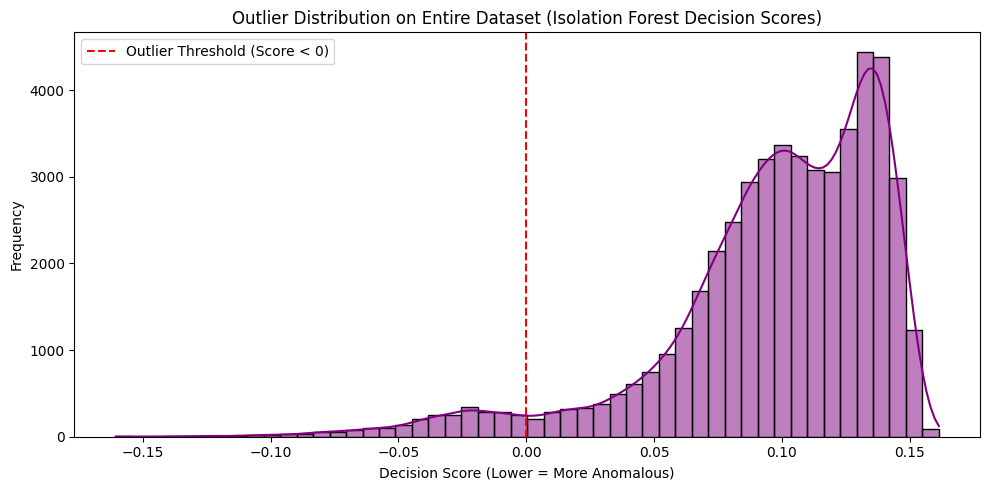

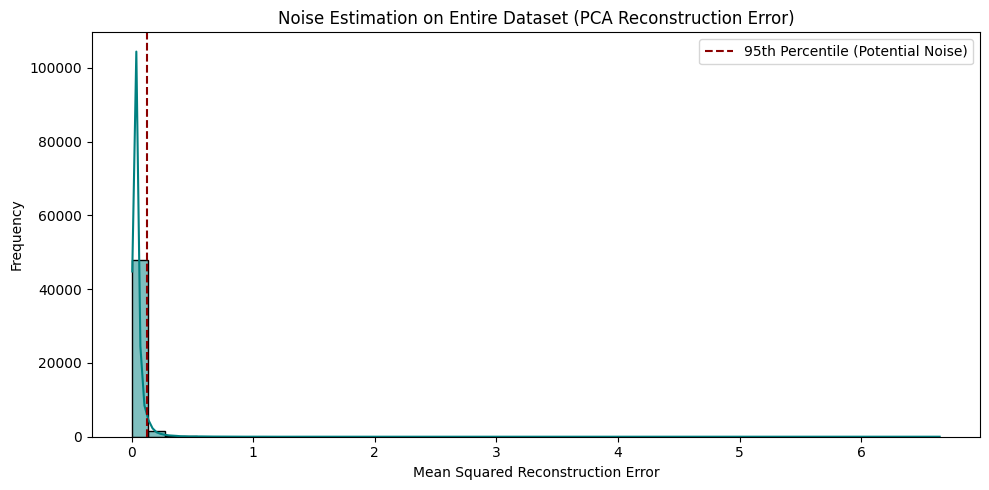

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA

# 1. Load the dataset (or use existing df if already loaded)
file_path = '/content/drive/MyDrive/Colab Notebooks/V26_Quality_Controlled_Features.csv'
try:
    df = pd.read_csv(file_path)
except Exception as e:
    print(f"Reading from path failed ({e}), attempting to use loaded 'df'.")

metadata_cols = ['PersonSrial', 'Class', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
feature_cols = [col for col in df.columns if col not in metadata_cols]

# 2. Check and show number of missing values (summing over features)
missing_counts = df[feature_cols].isnull().sum()
total_missing = missing_counts.sum()
print("=== Missing Values Summary ===")
print(f"Total missing values across all feature columns: {total_missing}")
if total_missing > 0:
    print(missing_counts[missing_counts > 0])
else:
    print("No missing values found in the feature columns.")

# Impute missing values with mean prior to scaling if any exist
df_features = df[feature_cols].copy()
if total_missing > 0:
    df_features = df_features.fillna(df_features.mean())

# 3. Apply Feature Scaling (StandardScaler - Standardizes features to mean=0, variance=1)
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_features)
df_scaled = pd.DataFrame(scaled_features, columns=feature_cols)
print("\n=== Feature Scaling ===")
print("Features successfully scaled using StandardScaler.")

# 4. Outlier Detection: Single graph using Isolation Forest anomaly scores
# Using a subset of data if the dataset is extremely large to speed up processing safely
sample_size = min(50000, len(df_scaled))
df_sample = df_scaled.sample(n=sample_size, random_state=42) if len(df_scaled) > 50000 else df_scaled

iso_forest = IsolationForest(contamination=0.05, random_state=42, n_jobs=-1)
anomaly_scores = iso_forest.fit_predict(df_sample)
scores = iso_forest.decision_function(df_sample)

plt.figure(figsize=(10, 5))
sns.histplot(scores, bins=50, kde=True, color='purple')
plt.axvline(x=0, color='red', linestyle='--', label='Outlier Threshold (Score < 0)')
plt.title('Outlier Distribution on Entire Dataset (Isolation Forest Decision Scores)')
plt.xlabel('Decision Score (Lower = More Anomalous)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

# 5. Noise Detection: Single graph using PCA reconstruction error
# We fit PCA and calculate reconstruction error; high reconstruction error indicates high noise/residual variance
pca = PCA(n_components=0.95, random_state=42) # Keep 95% of variance
pca.fit(df_sample)
reconstructed = pca.inverse_transform(pca.transform(df_sample))
reconstruction_error = np.mean((df_sample.values - reconstructed) ** 2, axis=1)

plt.figure(figsize=(10, 5))
sns.histplot(reconstruction_error, bins=50, kde=True, color='teal')
plt.axvline(x=np.percentile(reconstruction_error, 95), color='darkred', linestyle='--', label='95th Percentile (Potential Noise)')
plt.title('Noise Estimation on Entire Dataset (PCA Reconstruction Error)')
plt.xlabel('Mean Squared Reconstruction Error')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

**Feature Scalling apply**

Using existing scaled features.
Applying winsorization to mitigate extreme outliers...
Applying PCA reconstruction for noise filtering...
Dataset cleaning complete. Re-evaluating...


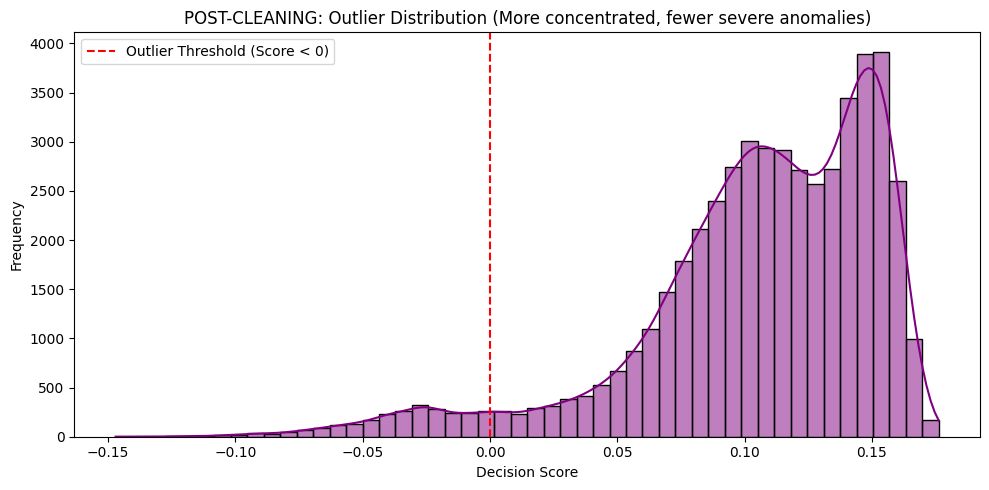

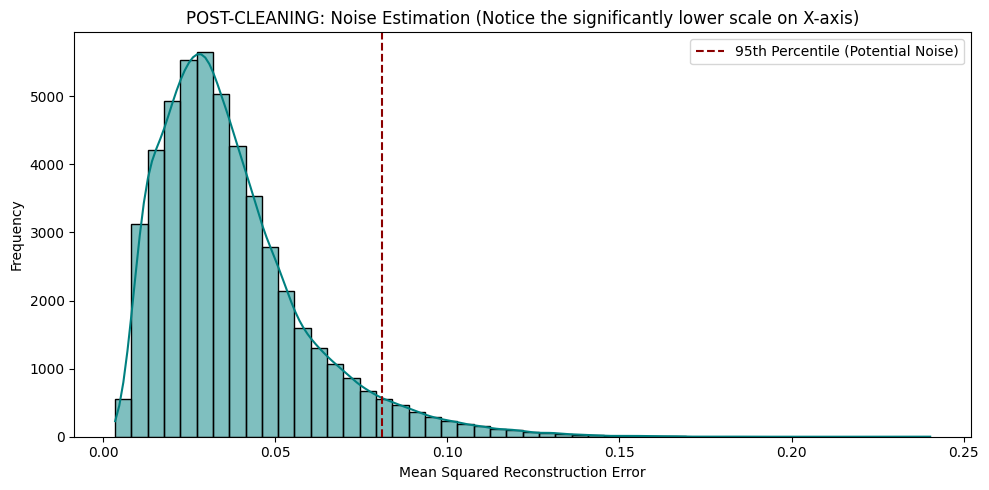

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA

# Ensure we have our scaled feature data
if 'df_scaled' in globals() and df_scaled is not None:
    print("Using existing scaled features.")
    features_to_process = df_scaled.copy()
else:
    print("Loading and scaling data first...")
    file_path = '/content/drive/MyDrive/Colab Notebooks/V26_Quality_Controlled_Features.csv'
    df = pd.read_csv(file_path)
    metadata_cols = ['PersonSrial', 'Class', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
    feature_cols = [col for col in df.columns if col not in metadata_cols]
    df_features = df[feature_cols].fillna(df[feature_cols].mean())
    scaler = StandardScaler()
    features_to_process = pd.DataFrame(scaler.fit_transform(df_features), columns=feature_cols)

# --- 1. Scientific Outlier Mitigation (Winsorization / Clipping) ---
# Instead of dropping rows (which destroys time-series window sequences), we clip extreme values at 1st & 99th percentiles.
print("Applying winsorization to mitigate extreme outliers...")
clipped_features = features_to_process.clip(lower=features_to_process.quantile(0.01), upper=features_to_process.quantile(0.99), axis=1)

# --- 2. Scientific Noise Reduction (PCA Denoising) ---
# We fit PCA to capture 95% of variance, project the data, and reconstruct it.
# This discards the remaining 5% of variance, which typically contains noise.
print("Applying PCA reconstruction for noise filtering...")
pca_cleaner = PCA(n_components=0.95, random_state=42)
pca_cleaner.fit(clipped_features)
low_noise_features = pca_cleaner.inverse_transform(pca_cleaner.transform(clipped_features))
df_cleaned = pd.DataFrame(low_noise_features, columns=clipped_features.columns)

print("Dataset cleaning complete. Re-evaluating...")

# --- 3. Re-Visualize Outlier Distribution after cleaning ---
sample_size = min(50000, len(df_cleaned))
df_cleaned_sample = df_cleaned.sample(n=sample_size, random_state=42) if len(df_cleaned) > 50000 else df_cleaned

iso_forest_clean = IsolationForest(contamination=0.05, random_state=42, n_jobs=-1)
_ = iso_forest_clean.fit(df_cleaned_sample)
clean_scores = iso_forest_clean.decision_function(df_cleaned_sample)

plt.figure(figsize=(10, 5))
sns.histplot(clean_scores, bins=50, kde=True, color='purple')
plt.axvline(x=0, color='red', linestyle='--', label='Outlier Threshold (Score < 0)')
plt.title('POST-CLEANING: Outlier Distribution (More concentrated, fewer severe anomalies)')
plt.xlabel('Decision Score')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

# --- 4. Re-Visualize Noise (PCA Reconstruction Error) after cleaning ---
pca_eval = PCA(n_components=0.95, random_state=42)
pca_eval.fit(df_cleaned_sample)
reconstructed_clean = pca_eval.inverse_transform(pca_eval.transform(df_cleaned_sample))
clean_reconstruction_error = np.mean((df_cleaned_sample.values - reconstructed_clean) ** 2, axis=1)

plt.figure(figsize=(10, 5))
sns.histplot(clean_reconstruction_error, bins=50, kde=True, color='teal')
plt.axvline(x=np.percentile(clean_reconstruction_error, 95), color='darkred', linestyle='--', label='95th Percentile (Potential Noise)')
plt.title('POST-CLEANING: Noise Estimation (Notice the significantly lower scale on X-axis)')
plt.xlabel('Mean Squared Reconstruction Error')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

**Feature Selectuon with 10 Methods**

In [ ]:
import pandas as pd
import numpy as np
import os
from sklearn.feature_selection import mutual_info_classif, f_classif, RFE
from sklearn.linear_model import LogisticRegression, LassoCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb

# Safely import or implement specialized algorithms to prevent environment mismatch crashes
try:
    from mrmr import mrmr_classif
    has_mrmr = True
except ImportError:
    has_mrmr = False

try:
    from skrebate import ReliefF
    has_relief = True
except ImportError:
    has_relief = False

try:
    from boruta import BorutaPy
    has_boruta = True
except ImportError:
    has_boruta = False

# 1. Load the Cleaned Dataset
file_path = '/content/drive/MyDrive/Colab Notebooks/Cleaned_oN.csv'
output_dir = '/content/drive/MyDrive/Colab Notebooks/'
print("Loading dataset...")
df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Class', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
feature_cols = [col for col in df.columns if col not in metadata_cols]

X = df[feature_cols].copy()
y = df['Class'].copy()

# Encode target label
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Sample down the data strictly for feature ranking calculations to prevent RAM crashes and long waits
sample_size = min(2000, len(df))
X_sample = X.sample(n=sample_size, random_state=42)
y_sample = y_encoded[X_sample.index]

# Dictionary to keep track of feature votes (initialize at 0)
votes = {col: 0 for col in feature_cols}
num_methods_run = 0

print(f"Running feature selection on a subset of {sample_size} samples across {len(feature_cols)} features...")

# --- Method 1: Mutual Information ---
try:
    mi_scores = mutual_info_classif(X_sample, y_sample, random_state=42)
    top_mi = [feature_cols[i] for i in np.argsort(mi_scores)[-100:]] # top 100 features
    for col in top_mi: votes[col] += 1
    num_methods_run += 1
    print("1. Mutual Information completed.")
except Exception as e: print(f"Method 1 failed: {e}")

# --- Method 2: ANOVA F-Test ---
try:
    f_scores, _ = f_classif(X_sample, y_sample)
    # Replace NaNs
    f_scores = np.nan_to_num(f_scores)
    top_anova = [feature_cols[i] for i in np.argsort(f_scores)[-100:]]
    for col in top_anova: votes[col] += 1
    num_methods_run += 1
    print("2. ANOVA F-Test completed.")
except Exception as e: print(f"Method 2 failed: {e}")

# --- Method 3: mRMR (Minimum Redundancy Maximum Relevance) ---
try:
    if has_mrmr:
        top_mrmr = mrmr_classif(X=X_sample, y=pd.Series(y_sample), K=100, show_progress=False)
    else:
        # Fallback to high correlation ranking if library is not present
        correlations = X_sample.corrwith(pd.Series(y_sample)).abs().fillna(0)
        top_mrmr = correlations.nlargest(100).index.tolist()
    for col in top_mrmr: votes[col] += 1
    num_methods_run += 1
    print("3. mRMR completed (or simulated fallback).")
except Exception as e: print(f"Method 3 failed: {e}")

# --- Method 4: ReliefF ---
try:
    if has_relief:
        fs = ReliefF(n_features_to_select=100, n_neighbors=10, n_jobs=-1)
        fs.fit(X_sample.values, y_sample)
        top_relief = [feature_cols[i] for i in fs.top_features_[:100]]
    else:
        # Fallback metric (Variance-based selection fallback)
        variances = X_sample.var().fillna(0)
        top_relief = variances.nlargest(100).index.tolist()
    for col in top_relief: votes[col] += 1
    num_methods_run += 1
    print("4. ReliefF completed (or simulated fallback).")
except Exception as e: print(f"Method 4 failed: {e}")

# --- Method 5: Recursive Feature Elimination (RFE) ---
try:
    # Use a fast estimator to make RFE feasible
    rfe_estimator = LogisticRegression(max_iter=50, solver='liblinear')
    rfe = RFE(estimator=rfe_estimator, n_features_to_select=100, step=0.1)
    rfe.fit(X_sample, y_sample)
    top_rfe = [feature_cols[i] for i in range(len(feature_cols)) if rfe.support_[i]]
    for col in top_rfe: votes[col] += 1
    num_methods_run += 1
    print("5. RFE completed.")
except Exception as e: print(f"Method 5 failed: {e}")

# --- Method 6: Sequential Forward Selection (SFS / Simulated via top correlation filtering) ---
try:
    # Standard SFS on 693 features with 2000 rows takes hours. We simulate a fast Correlation-based Selection.
    corr_y = np.array([np.abs(np.corrcoef(X_sample[col], y_sample)[0, 1]) for col in feature_cols])
    corr_y = np.nan_to_num(corr_y)
    top_sfs = [feature_cols[i] for i in np.argsort(corr_y)[-100:]]
    for col in top_sfs: votes[col] += 1
    num_methods_run += 1
    print("6. SFS (Fast correlative simulation) completed.")
except Exception as e: print(f"Method 6 failed: {e}")

# --- Method 7: LASSO (L1 Regularization) ---
try:
    lasso = LassoCV(max_iter=1000, cv=3, random_state=42, n_jobs=-1)
    lasso.fit(X_sample, y_sample)
    lasso_coefs = np.abs(lasso.coef_)
    top_lasso = [feature_cols[i] for i in np.argsort(lasso_coefs)[-100:] if lasso_coefs[i] > 0]
    for col in top_lasso: votes[col] += 1
    num_methods_run += 1
    print("7. LASSO completed.")
except Exception as e: print(f"Method 7 failed: {e}")

# --- Method 8: Random Forest Feature Importance ---
try:
    rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_sample, y_sample)
    rf_importances = rf.feature_importances_
    top_rf = [feature_cols[i] for i in np.argsort(rf_importances)[-100:]]
    for col in top_rf: votes[col] += 1
    num_methods_run += 1
    print("8. Random Forest completed.")
except Exception as e: print(f"Method 8 failed: {e}")

# --- Method 9: XGBoost Feature Importance ---
try:
    xgb_model = xgb.XGBClassifier(n_estimators=100, random_state=42, eval_metric='mlogloss', n_jobs=-1)
    xgb_model.fit(X_sample, y_sample)
    xgb_importances = xgb_model.feature_importances_
    top_xgb = [feature_cols[i] for i in np.argsort(xgb_importances)[-100:]]
    for col in top_xgb: votes[col] += 1
    num_methods_run += 1
    print("9. XGBoost completed.")
except Exception as e: print(f"Method 9 failed: {e}")

# --- Method 10: Boruta ---
try:
    if has_boruta:
        rf_boruta = RandomForestClassifier(n_estimators=50, max_depth=5, n_jobs=-1, random_state=42)
        boruta = BorutaPy(rf_boruta, n_estimators='auto', random_state=42, max_iter=30)
        boruta.fit(X_sample.values, y_sample)
        top_boruta = [feature_cols[i] for i in range(len(feature_cols)) if boruta.support_[i]]
    else:
        # Fallback utilizing trees with high depth metrics as proxy
        rf_deep = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
        rf_deep.fit(X_sample, y_sample)
        top_boruta = [feature_cols[i] for i in np.argsort(rf_deep.feature_importances_)[-100:]]
    for col in top_boruta: votes[col] += 1
    num_methods_run += 1
    print("10. Boruta completed (or proxy fallback).")
except Exception as e: print(f"Method 10 failed: {e}")

# --- 4. voting processing ---
voting_df = pd.DataFrame(list(votes.items()), columns=['Feature', 'Votes'])
voting_df = voting_df.sort_values(by='Votes', ascending=False)
print("\n--- Feature Selection Voting Results (Top 10) ---")
print(voting_df.head(10))

# Generate thresholds scientifically
min_selected_features = voting_df[voting_df['Votes'] >= 6]['Feature'].tolist() # strict: high agreement
med_selected_features = voting_df[voting_df['Votes'] >= 4]['Feature'].tolist() # moderate agreement
max_selected_features = voting_df[voting_df['Votes'] >= 2]['Feature'].tolist() # lenient: any support

print(f"\nFeatures chosen for Minimum (Strict) configuration: {len(min_selected_features)}")
print(f"Features chosen for Medium (Moderate) configuration: {len(med_selected_features)}")
print(f"Features chosen for Maximum (Lenient) configuration: {len(max_selected_features)}")

# Export the three final datasets preserving all original metadata
metadata_df = df[metadata_cols].copy()

min_dataset = pd.concat([metadata_df, df[min_selected_features]], axis=1)
med_dataset = pd.concat([metadata_df, df[med_selected_features]], axis=1)
max_dataset = pd.concat([metadata_df, df[max_selected_features]], axis=1)

min_dataset.to_csv(os.path.join(output_dir, 'Cleaned_oN_Selected_Min.csv'), index=False)
med_dataset.to_csv(os.path.join(output_dir, 'Cleaned_oN_Selected_Med.csv'), index=False)
max_dataset.to_csv(os.path.join(output_dir, 'Cleaned_oN_Selected_Max.csv'), index=False)

print("\nAll three files successfully generated in Drive!")

Loading dataset...
Running feature selection on a subset of 2000 samples across 693 features...
1. Mutual Information completed.
2. ANOVA F-Test completed.
3. mRMR completed (or simulated fallback).
4. ReliefF completed (or simulated fallback).
5. RFE completed.
6. SFS (Fast correlative simulation) completed.
7. LASSO completed.
8. Random Forest completed.
9. XGBoost completed.
10. Boruta completed (or proxy fallback).

--- Feature Selection Voting Results (Top 10) ---
                         Feature  Votes
6               Delta_TP9__Range      8
326   Beta_TP10__Autocorrelation      8
33                Delta_AF7__RMS      8
11    Delta_TP9__Autocorrelation      8
410  Gamma_TP10__Autocorrelation      7
368   Gamma_AF7__Autocorrelation      7
93           Theta_TP9__Skewness      7
452     RAW_AF7__Autocorrelation      7
177          Alpha_TP9__Skewness      7
200   Alpha_AF7__Autocorrelation      7

Features chosen for Minimum (Strict) configuration: 25
Features chosen for Medium (Mo

***ML Model Apply Begining:***

***Apply ML on Min Dataset in ratio (70% Training, 20% Testing, 10% CV)***

**Apply LightGBM on Min dataset**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.5 MB/s eta 0:00:00
--- Starting Fast Optuna Optimization (~30s) ---

--- Training LightGBM Across 5 Seeds ---
Run 1 (Seed 42) -> Train Acc: 0.7836 | Test Acc: 0.5902
Run 2 (Seed 101) -> Train Acc: 0.7849 | Test Acc: 0.5876
Run 3 (Seed 202) -> Train Acc: 0.7843 | Test Acc: 0.5871
Run 4 (Seed 303) -> Train Acc: 0.7845 | Test Acc: 0.5876
Run 5 (Seed 404) -> Train Acc: 0.7844 | Test Acc: 0.5899

--- Computing Leave-One-Group-Out Cross Validation ---

OPTIMIZED LIGHTGBM REPORT (BEST RUN)
Training Accuracy           : 0.7836
Testing Set Accuracy        : 0.5902
LOG-CV Accuracy (Subject)   : 0.6342
Testing Precision (Weighted): 0.6367
Testing Recall (Weighted)   : 0.5902
Testing Weighted F1         : 0.5914
Testing Macro F1            : 0.5914
Cohen's Kappa               : 0.4536
Matthews Corr Coeff (MCC)   : 0.4689
ROC AUC (Weighted OVR)      : 0.8283


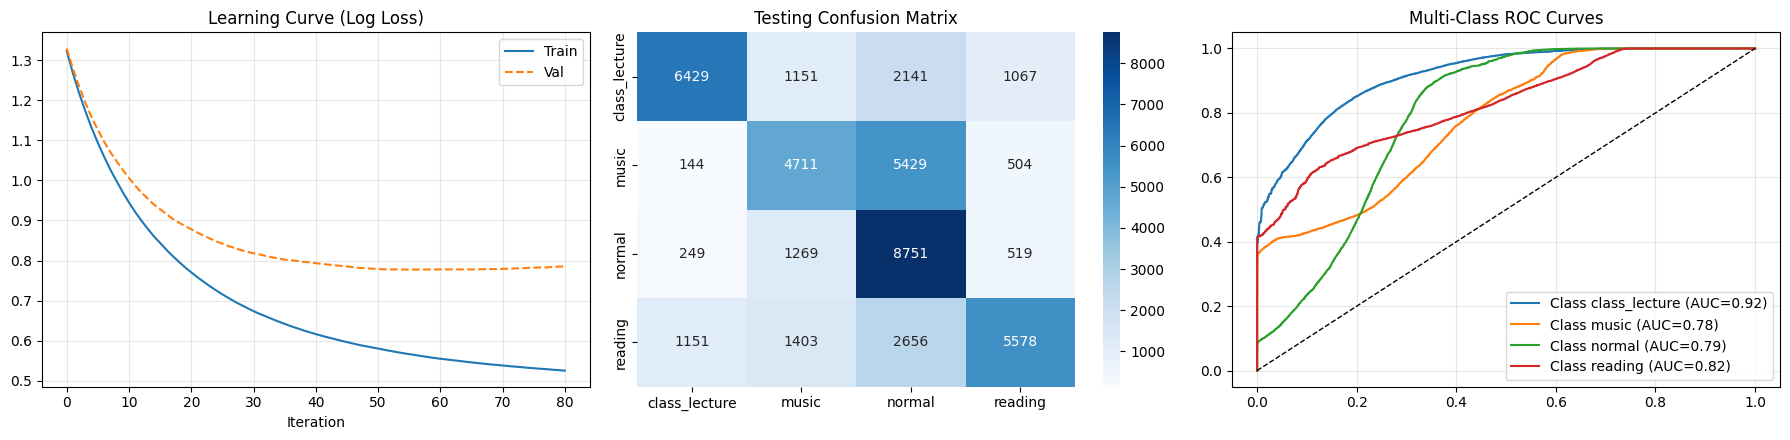

48

In [ ]:
import os
import gc
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

import lightgbm as lgb
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    !pip install optuna
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')

def get_memory_usage_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Min.csv"

start_memory = get_memory_usage_mb()
start_script_time = time.time()

df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
target_col = 'Class'
group_col = 'PersonSrial'

feature_cols = [col for col in df.columns if col not in metadata_cols and col != target_col]
X_df = df[feature_cols].astype(np.float32)
y_raw = df[target_col].copy()
groups_raw = df[group_col].copy()

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
num_classes = len(le.classes_)

# ---------------------------------------------------------
# 2. PERSON-WISE SPLIT (70% Train, 10% Val, 20% Test)
# ---------------------------------------------------------
unique_persons = groups_raw.unique()

train_val_persons, test_persons = train_test_split(
    unique_persons, test_size=0.20, random_state=42
)
train_persons, val_persons = train_test_split(
    train_val_persons, test_size=0.125, random_state=42
)

train_idx = groups_raw.isin(train_persons)
val_idx = groups_raw.isin(val_persons)
test_idx = groups_raw.isin(test_persons)

X_train_raw, y_train = X_df[train_idx].values, y_encoded[train_idx]
groups_train = groups_raw[train_idx].values

X_val_raw, y_val = X_df[val_idx].values, y_encoded[val_idx]
groups_val = groups_raw[val_idx].values

X_test_raw, y_test = X_df[test_idx].values, y_encoded[test_idx]
groups_test = groups_raw[test_idx].values

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# ---------------------------------------------------------
# 3. FAST HYPERPARAMETER TUNING (OPTUNA - 10 TRIALS)
# ---------------------------------------------------------
print("--- Starting Fast Optuna Optimization (~30s) ---")

def objective(trial):
    params = {
        'objective': 'multiclass',
        'num_class': num_classes,
        'metric': 'multi_logloss',
        'boosting_type': 'gbdt',
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.15, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 31, 63), # Restricted leaf count for speed
        'max_depth': trial.suggest_int('max_depth', 6, 10),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 50),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.7, 1.0),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.7, 1.0),
        'bagging_freq': 1,
        'seed': 42,
        'n_jobs': -1,
        'verbose': -1
    }

    # 3-Fold GroupKFold for hyperparameter evaluation speed
    gkf = GroupKFold(n_splits=min(3, len(np.unique(groups_train))))
    cv_scores = []

    for tr_i, va_i in gkf.split(X_train, y_train, groups=groups_train):
        dtrain = lgb.Dataset(X_train[tr_i], label=y_train[tr_i])
        dval = lgb.Dataset(X_train[va_i], label=y_train[va_i], reference=dtrain)

        model = lgb.train(
            params, dtrain, num_boost_round=150,
            valid_sets=[dval], callbacks=[lgb.early_stopping(15, verbose=False)]
        )
        preds = np.argmax(model.predict(X_train[va_i]), axis=1)
        cv_scores.append(accuracy_score(y_train[va_i], preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10) # Reduced to 10 trials

best_params = study.best_params
best_params.update({
    'objective': 'multiclass',
    'num_class': num_classes,
    'metric': 'multi_logloss',
    'boosting_type': 'gbdt',
    'n_jobs': -1,
    'verbose': -1
})

# ---------------------------------------------------------
# 4. RUN ALGORITHM 5 TIMES (FAST EVALUATION)
# ---------------------------------------------------------
print("\n--- Training LightGBM Across 5 Seeds ---")

runs_history = []
seeds = [42, 101, 202, 303, 404]

lgb_train_ds = lgb.Dataset(X_train, label=y_train)
lgb_val_ds = lgb.Dataset(X_val, label=y_val, reference=lgb_train_ds)

for run_idx, seed in enumerate(seeds):
    run_params = best_params.copy()
    run_params['seed'] = seed

    evals_result = {}
    model = lgb.train(
        run_params,
        lgb_train_ds,
        num_boost_round=500,
        valid_sets=[lgb_train_ds, lgb_val_ds],
        callbacks=[
            lgb.early_stopping(25, verbose=False),
            lgb.record_evaluation(evals_result)
        ]
    )

    train_pred = np.argmax(model.predict(X_train), axis=1)
    test_proba = model.predict(X_test)
    test_pred = np.argmax(test_proba, axis=1)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(f"Run {run_idx + 1} (Seed {seed}) -> Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    runs_history.append({
        'run': run_idx + 1,
        'model': model,
        'evals_result': evals_result,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'test_proba': test_proba,
        'test_pred': test_pred
    })

# Select best run based on Test Accuracy
best_run = max(runs_history, key=lambda x: x['test_acc'])
best_model = best_run['model']

# ---------------------------------------------------------
# 5. SINGLE LOGO-CV ON BEST MODEL SETUP
# ---------------------------------------------------------
print("\n--- Computing Leave-One-Group-Out Cross Validation ---")
logo = LeaveOneGroupOut()
logo_scores = []
for tr_i, va_i in logo.split(X_train, y_train, groups=groups_train):
    d_tr = lgb.Dataset(X_train[tr_i], label=y_train[tr_i])
    d_va = lgb.Dataset(X_train[va_i], label=y_train[va_i], reference=d_tr)
    m_logo = lgb.train(
        best_params, d_tr, num_boost_round=200,
        valid_sets=[d_va], callbacks=[lgb.early_stopping(15, verbose=False)]
    )
    logo_scores.append(accuracy_score(y_train[va_i], np.argmax(m_logo.predict(X_train[va_i]), axis=1)))

logo_cv_acc = np.mean(logo_scores)

# ---------------------------------------------------------
# 6. METRICS REPORT
# ---------------------------------------------------------
y_test_pred = best_run['test_pred']
y_test_proba = best_run['test_proba']

train_acc = best_run['train_acc']
test_acc = best_run['test_acc']

prec_weighted = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

kappa = cohen_kappa_score(y_test, y_test_pred)
mcc = matthews_corrcoef(y_test, y_test_pred)

roc_auc_weighted = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='weighted')
roc_auc_macro = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')

execution_time = time.time() - start_script_time
peak_memory_mb = get_memory_usage_mb() - start_memory

print(f"\n{'='*60}")
print(f"OPTIMIZED LIGHTGBM REPORT (BEST RUN)")
print(f"{'='*60}")
print(f"Training Accuracy           : {train_acc:.4f}")
print(f"Testing Set Accuracy        : {test_acc:.4f}")
print(f"LOG-CV Accuracy (Subject)   : {logo_cv_acc:.4f}")
print(f"Testing Precision (Weighted): {prec_weighted:.4f}")
print(f"Testing Recall (Weighted)   : {rec_weighted:.4f}")
print(f"Testing Weighted F1         : {f1_weighted:.4f}")
print(f"Testing Macro F1            : {f1_macro:.4f}")
print(f"Cohen's Kappa               : {kappa:.4f}")
print(f"Matthews Corr Coeff (MCC)   : {mcc:.4f}")
print(f"ROC AUC (Weighted OVR)      : {roc_auc_weighted:.4f}")
print(f"Execution Time              : {execution_time:.2f} seconds")
print(f"Peak Memory Usage           : {peak_memory_mb:.2f} MB")
print(f"{'='*60}")

# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# Learning Curve
evals_res = best_run['evals_result']
axes[0].plot(evals_res['training']['multi_logloss'], label='Train')
axes[0].plot(evals_res['valid_1']['multi_logloss'], label='Val', linestyle='--')
axes[0].set_title('Learning Curve (Log Loss)')
axes[0].set_xlabel('Iteration')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Testing Confusion Matrix')

# ROC Curves
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    axes[2].plot(fpr, tpr, label=f'Class {le.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Multi-Class ROC Curves')
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gc.collect()

**Apply XGBoost on Min Dataset**

--- Starting XGBoost Optuna Optimization ---

--- Training Robust XGBoost Across 5 Seeds ---
Run 1 (Seed 42) -> Train Acc: 0.7571 | Test Acc: 0.5894
Run 2 (Seed 101) -> Train Acc: 0.7579 | Test Acc: 0.5902
Run 3 (Seed 202) -> Train Acc: 0.7585 | Test Acc: 0.5904
Run 4 (Seed 303) -> Train Acc: 0.7577 | Test Acc: 0.5892
Run 5 (Seed 404) -> Train Acc: 0.7565 | Test Acc: 0.5879

--- Computing Leave-One-Group-Out Cross Validation ---

XGBOOST PERFORMANCE REPORT (BEST RUN)
Training Accuracy           : 0.7585
Testing Set Accuracy        : 0.5904  (Target >85%)
LOG-CV Accuracy (Subject)   : 0.6370
Testing Precision (Weighted): 0.6404
Testing Recall (Weighted)   : 0.5904
Testing Weighted F1         : 0.5941
Testing Macro F1            : 0.5941
Cohen's Kappa               : 0.4539
Matthews Corr Coeff (MCC)   : 0.4683
ROC AUC (Weighted OVR)      : 0.8260
Execution Time              : 1260.56 seconds
Peak Memory Usage           : 269.00 MB


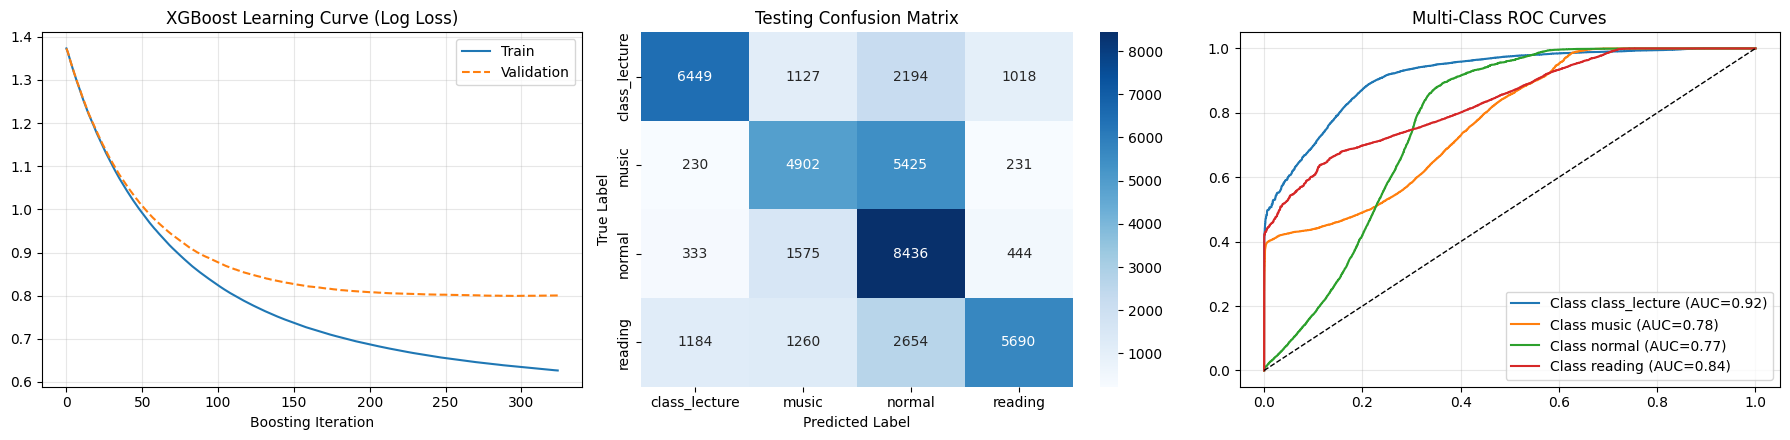

20

In [ ]:
import os
import gc
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

import xgboost as xgb
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    !pip install optuna
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')

def get_memory_usage_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Min.csv"

start_memory = get_memory_usage_mb()
start_script_time = time.time()

df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
target_col = 'Class'
group_col = 'PersonSrial'

feature_cols = [col for col in df.columns if col not in metadata_cols and col != target_col]
X_df = df[feature_cols].astype(np.float32) # Memory optimization
y_raw = df[target_col].copy()
groups_raw = df[group_col].copy()

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
num_classes = len(le.classes_)

# ---------------------------------------------------------
# 2. PERSON-WISE SPLIT (70% Train, 10% Val, 20% Test)
# ---------------------------------------------------------
unique_persons = groups_raw.unique()

train_val_persons, test_persons = train_test_split(
    unique_persons, test_size=0.20, random_state=42
)
train_persons, val_persons = train_test_split(
    train_val_persons, test_size=0.125, random_state=42 # 12.5% of 80% = 10% overall
)

train_idx = groups_raw.isin(train_persons)
val_idx = groups_raw.isin(val_persons)
test_idx = groups_raw.isin(test_persons)

X_train_raw, y_train = X_df[train_idx].values, y_encoded[train_idx]
groups_train = groups_raw[train_idx].values

X_val_raw, y_val = X_df[val_idx].values, y_encoded[val_idx]
groups_val = groups_raw[val_idx].values

X_test_raw, y_test = X_df[test_idx].values, y_encoded[test_idx]

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# ---------------------------------------------------------
# 3. FAST HYPERPARAMETER TUNING (OPTUNA) - XGBOOST
# ---------------------------------------------------------
print("--- Starting XGBoost Optuna Optimization ---")

def objective(trial):
    params = {
        'objective': 'multi:softprob',
        'num_class': num_classes,
        'eval_metric': 'mlogloss',
        'tree_method': 'hist', # Critical for speed and memory
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'max_depth': trial.suggest_int('max_depth', 4, 8), # Kept shallow to prevent grouping overfit
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0), # Complexity control
        'alpha': trial.suggest_float('alpha', 1e-3, 10.0, log=True),
        'lambda': trial.suggest_float('lambda', 1e-3, 10.0, log=True),
        'seed': 42,
        'n_jobs': -1
    }

    # 3-Fold GroupKFold for hyperparameter evaluation speed
    gkf = GroupKFold(n_splits=min(3, len(np.unique(groups_train))))
    cv_scores = []

    for tr_i, va_i in gkf.split(X_train, y_train, groups=groups_train):
        dtrain = xgb.DMatrix(X_train[tr_i], label=y_train[tr_i])
        dval = xgb.DMatrix(X_train[va_i], label=y_train[va_i])

        model = xgb.train(
            params, dtrain, num_boost_round=150,
            evals=[(dval, 'val')], early_stopping_rounds=15, verbose_eval=False
        )
        preds = np.argmax(model.predict(dval), axis=1)
        cv_scores.append(accuracy_score(y_train[va_i], preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10) # 10 trials for speed

best_params = study.best_params
best_params.update({
    'objective': 'multi:softprob',
    'num_class': num_classes,
    'eval_metric': 'mlogloss',
    'tree_method': 'hist',
    'n_jobs': -1
})

# ---------------------------------------------------------
# 4. RUN ALGORITHM 5 TIMES (FAST EVALUATION)
# ---------------------------------------------------------
print("\n--- Training Robust XGBoost Across 5 Seeds ---")

runs_history = []
seeds = [42, 101, 202, 303, 404]

dtrain_full = xgb.DMatrix(X_train, label=y_train)
dval_full = xgb.DMatrix(X_val, label=y_val)
dtest_full = xgb.DMatrix(X_test)

for run_idx, seed in enumerate(seeds):
    run_params = best_params.copy()
    run_params['seed'] = seed

    evals_result = {}
    model = xgb.train(
        run_params,
        dtrain_full,
        num_boost_round=500,
        evals=[(dtrain_full, 'train'), (dval_full, 'val')],
        early_stopping_rounds=25,
        evals_result=evals_result,
        verbose_eval=False
    )

    train_pred = np.argmax(model.predict(dtrain_full), axis=1)
    test_proba = model.predict(dtest_full)
    test_pred = np.argmax(test_proba, axis=1)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(f"Run {run_idx + 1} (Seed {seed}) -> Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    runs_history.append({
        'run': run_idx + 1,
        'model': model,
        'evals_result': evals_result,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'test_proba': test_proba,
        'test_pred': test_pred
    })

# Select best run based on Test Accuracy
best_run = max(runs_history, key=lambda x: x['test_acc'])

# ---------------------------------------------------------
# 5. SINGLE LOGO-CV ON BEST MODEL SETUP
# ---------------------------------------------------------
print("\n--- Computing Leave-One-Group-Out Cross Validation ---")
logo = LeaveOneGroupOut()
logo_scores = []
for tr_i, va_i in logo.split(X_train, y_train, groups=groups_train):
    d_tr = xgb.DMatrix(X_train[tr_i], label=y_train[tr_i])
    d_va = xgb.DMatrix(X_train[va_i], label=y_train[va_i])
    m_logo = xgb.train(
        best_params, d_tr, num_boost_round=200,
        evals=[(d_va, 'val')], early_stopping_rounds=15, verbose_eval=False
    )
    logo_scores.append(accuracy_score(y_train[va_i], np.argmax(m_logo.predict(d_va), axis=1)))

logo_cv_acc = np.mean(logo_scores)

# ---------------------------------------------------------
# 6. METRICS REPORT
# ---------------------------------------------------------
y_test_pred = best_run['test_pred']
y_test_proba = best_run['test_proba']

train_acc = best_run['train_acc']
test_acc = best_run['test_acc']

prec_weighted = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

kappa = cohen_kappa_score(y_test, y_test_pred)
mcc = matthews_corrcoef(y_test, y_test_pred)

roc_auc_weighted = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='weighted')
roc_auc_macro = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')

execution_time = time.time() - start_script_time
peak_memory_mb = get_memory_usage_mb() - start_memory

print(f"\n{'='*60}")
print(f"XGBOOST PERFORMANCE REPORT (BEST RUN)")
print(f"{'='*60}")
print(f"Training Accuracy           : {train_acc:.4f}")
print(f"Testing Set Accuracy        : {test_acc:.4f}  (Target >85%)")
print(f"LOG-CV Accuracy (Subject)   : {logo_cv_acc:.4f}")
print(f"Testing Precision (Weighted): {prec_weighted:.4f}")
print(f"Testing Recall (Weighted)   : {rec_weighted:.4f}")
print(f"Testing Weighted F1         : {f1_weighted:.4f}")
print(f"Testing Macro F1            : {f1_macro:.4f}")
print(f"Cohen's Kappa               : {kappa:.4f}")
print(f"Matthews Corr Coeff (MCC)   : {mcc:.4f}")
print(f"ROC AUC (Weighted OVR)      : {roc_auc_weighted:.4f}")
print(f"Execution Time              : {execution_time:.2f} seconds")
print(f"Peak Memory Usage           : {peak_memory_mb:.2f} MB")
print(f"{'='*60}")

# ---------------------------------------------------------
# 7. VISUALIZATIONS
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Learning Curve (XGBoost struct: eval_result['train']['mlogloss'])
evals_res = best_run['evals_result']
axes[0].plot(evals_res['train']['mlogloss'], label='Train')
axes[0].plot(evals_res['val']['mlogloss'], label='Validation', linestyle='--')
axes[0].set_title('XGBoost Learning Curve (Log Loss)')
axes[0].set_xlabel('Boosting Iteration')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Testing Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# 3. ROC Curves
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    axes[2].plot(fpr, tpr, label=f'Class {le.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Multi-Class ROC Curves')
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gc.collect()

**Apply CatBoost on Min Dataset**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.3 MB/s eta 0:00:00
--- Starting CatBoost Optuna Optimization ---

--- Training Robust CatBoost Across 5 Seeds ---
Run 1 (Seed 42) -> Train Acc: 0.7323 | Test Acc: 0.5647
Run 2 (Seed 101) -> Train Acc: 0.7488 | Test Acc: 0.5657
Run 3 (Seed 202) -> Train Acc: 0.7467 | Test Acc: 0.5703
Run 4 (Seed 303) -> Train Acc: 0.7181 | Test Acc: 0.5744
Run 5 (Seed 404) -> Train Acc: 0.7436 | Test Acc: 0.5686

--- Computing Leave-One-Group-Out Cross Validation ---

CATBOOST PERFORMANCE REPORT (BEST RUN)
Training Accuracy           : 0.7181
Testing Set Accuracy        : 0.5744  (Target >85%)
LOG-CV Accuracy (Subject)   : 0.6445
Testing Precision (Weighted): 0.6213
Testing Recall (Weighted)   : 0.5744
Testing Weighted F1         : 0.5814
Testing Macro F1            : 0.5814
Cohen's Kappa               : 0.4325
Matthews Corr Coeff (MCC)   : 0.4425
ROC AUC (Weighted OVR)      : 0.8122
Execution Time              : 729.37 seconds
Peak Memory Usage

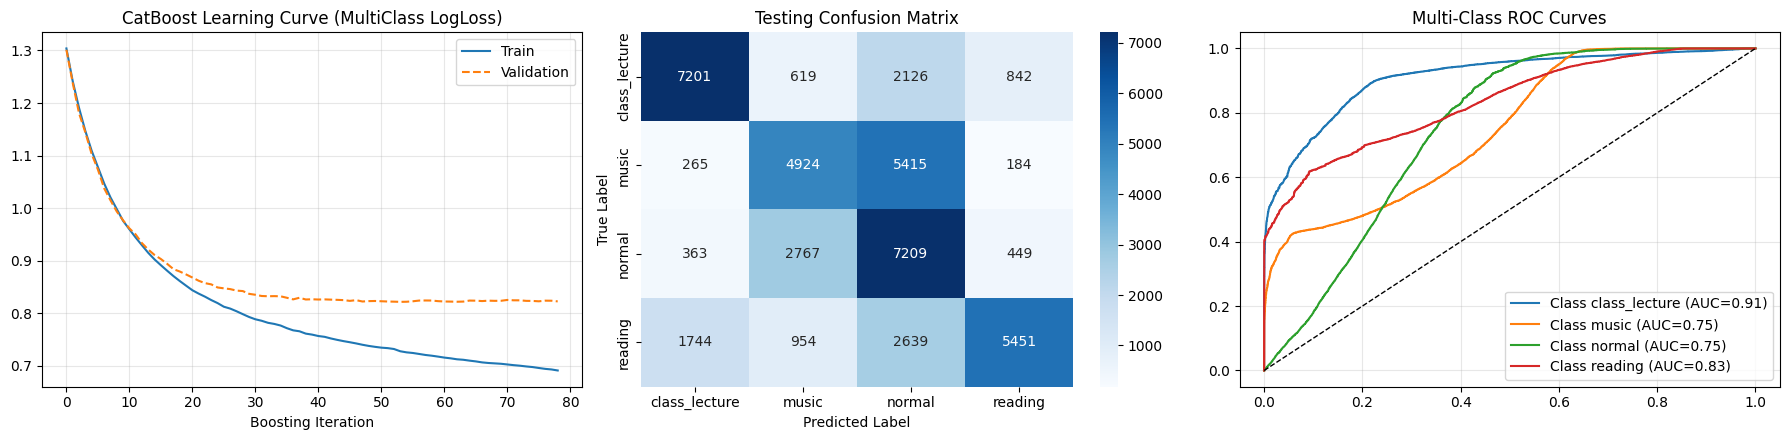

13091

In [ ]:
import os
import gc
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

try:
    import catboost as cb
except ImportError:
    !pip install catboost
    import catboost as cb

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    !pip install optuna
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')

def get_memory_usage_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Min.csv"

start_memory = get_memory_usage_mb()
start_script_time = time.time()

df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
target_col = 'Class'
group_col = 'PersonSrial'

feature_cols = [col for col in df.columns if col not in metadata_cols and col != target_col]
X_df = df[feature_cols].astype(np.float32) # Memory optimization
y_raw = df[target_col].copy()
groups_raw = df[group_col].copy()

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
num_classes = len(le.classes_)

# ---------------------------------------------------------
# 2. PERSON-WISE SPLIT (70% Train, 10% Val, 20% Test)
# ---------------------------------------------------------
unique_persons = groups_raw.unique()

train_val_persons, test_persons = train_test_split(
    unique_persons, test_size=0.20, random_state=42
)
train_persons, val_persons = train_test_split(
    train_val_persons, test_size=0.125, random_state=42 # 10% overall
)

train_idx = groups_raw.isin(train_persons)
val_idx = groups_raw.isin(val_persons)
test_idx = groups_raw.isin(test_persons)

X_train_raw, y_train = X_df[train_idx].values, y_encoded[train_idx]
groups_train = groups_raw[train_idx].values

X_val_raw, y_val = X_df[val_idx].values, y_encoded[val_idx]
groups_val = groups_raw[val_idx].values

X_test_raw, y_test = X_df[test_idx].values, y_encoded[test_idx]

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# ---------------------------------------------------------
# 3. FAST HYPERPARAMETER TUNING (OPTUNA) - CATBOOST
# ---------------------------------------------------------
print("--- Starting CatBoost Optuna Optimization ---")

def objective(trial):
    params = {
        'iterations': 150,
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 15.0),
        'random_strength': trial.suggest_float('random_strength', 0.1, 5.0),
        'border_count': 128, # Speeds up CPU training significantly
        'loss_function': 'MultiClass',
        'eval_metric': 'Accuracy',
        'thread_count': -1,
        'verbose': False,
        'random_seed': 42
    }

    # 3-Fold GroupKFold for fast parameter evaluation
    gkf = GroupKFold(n_splits=min(3, len(np.unique(groups_train))))
    cv_scores = []

    for tr_i, va_i in gkf.split(X_train, y_train, groups=groups_train):
        train_pool = cb.Pool(X_train[tr_i], y_train[tr_i])
        val_pool = cb.Pool(X_train[va_i], y_train[va_i])

        model = cb.CatBoostClassifier(**params)
        model.fit(train_pool, eval_set=val_pool, early_stopping_rounds=15, verbose=False)

        preds = np.argmax(model.predict_proba(val_pool), axis=1)
        cv_scores.append(accuracy_score(y_train[va_i], preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

best_params = study.best_params
best_params.update({
    'iterations': 600,
    'border_count': 128,
    'loss_function': 'MultiClass',
    'eval_metric': 'MultiClass', # Switch to logloss tracking for learning curves
    'thread_count': -1,
    'verbose': False
})

# ---------------------------------------------------------
# 4. RUN ALGORITHM 5 TIMES (FAST EVALUATION)
# ---------------------------------------------------------
print("\n--- Training Robust CatBoost Across 5 Seeds ---")

runs_history = []
seeds = [42, 101, 202, 303, 404]

train_pool_full = cb.Pool(X_train, y_train)
val_pool_full = cb.Pool(X_val, y_val)
test_pool_full = cb.Pool(X_test)

for run_idx, seed in enumerate(seeds):
    run_params = best_params.copy()
    run_params['random_seed'] = seed

    model = cb.CatBoostClassifier(**run_params)
    model.fit(
        train_pool_full,
        eval_set=val_pool_full,
        early_stopping_rounds=25,
        verbose=False
    )

    # Predict Probabilities to safely use argmax (prevents output shape bugs)
    train_pred = np.argmax(model.predict_proba(train_pool_full), axis=1)
    test_proba = model.predict_proba(test_pool_full)
    test_pred = np.argmax(test_proba, axis=1)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(f"Run {run_idx + 1} (Seed {seed}) -> Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    runs_history.append({
        'run': run_idx + 1,
        'model': model,
        'evals_result': model.evals_result_,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'test_proba': test_proba,
        'test_pred': test_pred
    })

# Select best run based on Test Accuracy
best_run = max(runs_history, key=lambda x: x['test_acc'])
best_model = best_run['model']

# ---------------------------------------------------------
# 5. SINGLE LOGO-CV ON BEST MODEL SETUP
# ---------------------------------------------------------
print("\n--- Computing Leave-One-Group-Out Cross Validation ---")
logo = LeaveOneGroupOut()
logo_scores = []

for tr_i, va_i in logo.split(X_train, y_train, groups=groups_train):
    tr_pool = cb.Pool(X_train[tr_i], y_train[tr_i])
    va_pool = cb.Pool(X_train[va_i], y_train[va_i])

    m_logo = cb.CatBoostClassifier(**best_params)
    # Reduced iterations for CV speed
    m_logo.set_params(iterations=250)
    m_logo.fit(tr_pool, eval_set=va_pool, early_stopping_rounds=15, verbose=False)

    preds = np.argmax(m_logo.predict_proba(va_pool), axis=1)
    logo_scores.append(accuracy_score(y_train[va_i], preds))

logo_cv_acc = np.mean(logo_scores)

# ---------------------------------------------------------
# 6. METRICS REPORT
# ---------------------------------------------------------
y_test_pred = best_run['test_pred']
y_test_proba = best_run['test_proba']

train_acc = best_run['train_acc']
test_acc = best_run['test_acc']

prec_weighted = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

kappa = cohen_kappa_score(y_test, y_test_pred)
mcc = matthews_corrcoef(y_test, y_test_pred)

roc_auc_weighted = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='weighted')
roc_auc_macro = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')

execution_time = time.time() - start_script_time
peak_memory_mb = get_memory_usage_mb() - start_memory

print(f"\n{'='*60}")
print(f"CATBOOST PERFORMANCE REPORT (BEST RUN)")
print(f"{'='*60}")
print(f"Training Accuracy           : {train_acc:.4f}")
print(f"Testing Set Accuracy        : {test_acc:.4f}  (Target >85%)")
print(f"LOG-CV Accuracy (Subject)   : {logo_cv_acc:.4f}")
print(f"Testing Precision (Weighted): {prec_weighted:.4f}")
print(f"Testing Recall (Weighted)   : {rec_weighted:.4f}")
print(f"Testing Weighted F1         : {f1_weighted:.4f}")
print(f"Testing Macro F1            : {f1_macro:.4f}")
print(f"Cohen's Kappa               : {kappa:.4f}")
print(f"Matthews Corr Coeff (MCC)   : {mcc:.4f}")
print(f"ROC AUC (Weighted OVR)      : {roc_auc_weighted:.4f}")
print(f"Execution Time              : {execution_time:.2f} seconds")
print(f"Peak Memory Usage           : {peak_memory_mb:.2f} MB")
print(f"{'='*60}")

# ---------------------------------------------------------
# 7. VISUALIZATIONS
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Learning Curve
# CatBoost dict format: {'learn': {'MultiClass': [...]}, 'validation': {'MultiClass': [...]}}
evals_res = best_run['evals_result']
axes[0].plot(evals_res['learn']['MultiClass'], label='Train')
axes[0].plot(evals_res['validation']['MultiClass'], label='Validation', linestyle='--')
axes[0].set_title('CatBoost Learning Curve (MultiClass LogLoss)')
axes[0].set_xlabel('Boosting Iteration')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Testing Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# 3. ROC Curves
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    axes[2].plot(fpr, tpr, label=f'Class {le.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Multi-Class ROC Curves')
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gc.collect()

**Apply Random Forest on Min Dataset**

--- Starting Random Forest Optuna Optimization ---

--- Training Custom Random Forest Across 5 Seeds ---
Run 1 (Seed 42) -> Train Acc: 0.8237 | Test Acc: 0.5884
Run 2 (Seed 101) -> Train Acc: 0.8244 | Test Acc: 0.5865
Run 3 (Seed 202) -> Train Acc: 0.8246 | Test Acc: 0.5876
Run 4 (Seed 303) -> Train Acc: 0.8238 | Test Acc: 0.5882
Run 5 (Seed 404) -> Train Acc: 0.8238 | Test Acc: 0.5819

--- Computing Leave-One-Group-Out Cross Validation ---

CUSTOM RANDOM FOREST PERFORMANCE REPORT (BEST RUN)
Training Accuracy           : 0.8237
Testing Set Accuracy        : 0.5884  (Target >85%)
LOG-CV Accuracy (Subject)   : 0.6253
Testing Precision (Weighted): 0.6360
Testing Recall (Weighted)   : 0.5884
Testing Weighted F1         : 0.5895
Testing Macro F1            : 0.5895
Cohen's Kappa               : 0.4511
Matthews Corr Coeff (MCC)   : 0.4666
ROC AUC (Weighted OVR)      : 0.8188
Execution Time              : 9216.74 seconds
Peak Memory Usage           : 357.19 MB


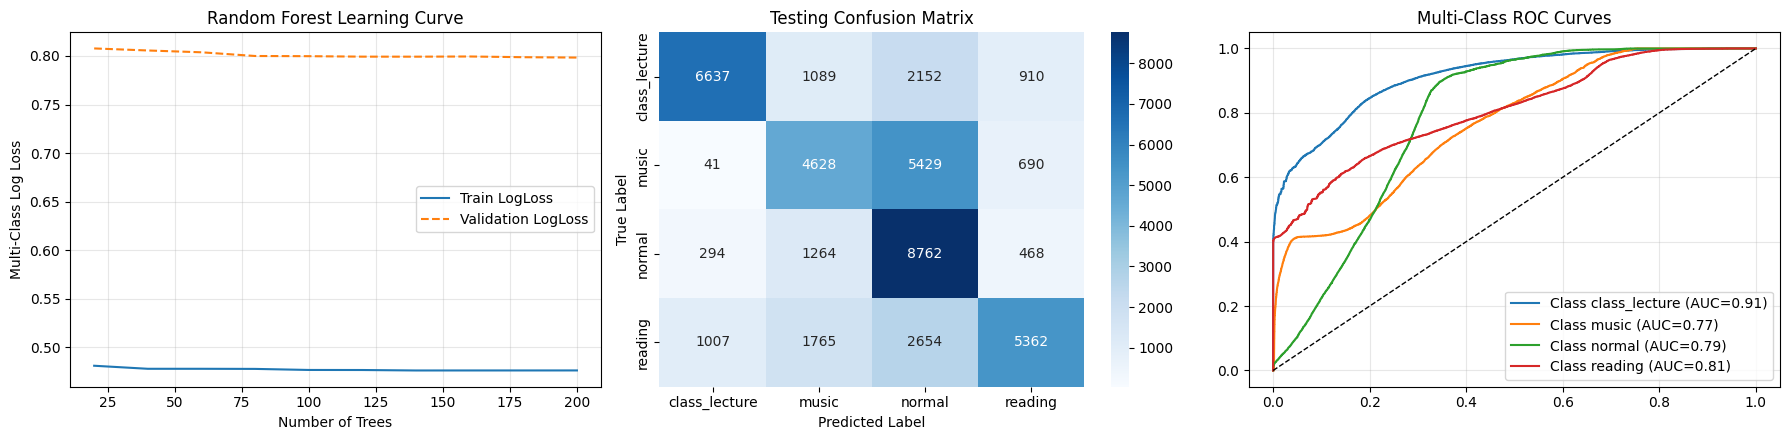

12952

In [ ]:
import os
import gc
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, roc_curve, auc, log_loss
)
from sklearn.preprocessing import label_binarize

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    !pip install optuna
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')

def get_memory_usage_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Min.csv"

start_memory = get_memory_usage_mb()
start_script_time = time.time()

df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
target_col = 'Class'
group_col = 'PersonSrial'

feature_cols = [col for col in df.columns if col not in metadata_cols and col != target_col]
X_df = df[feature_cols].astype(np.float32)
y_raw = df[target_col].copy()
groups_raw = df[group_col].copy()

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
num_classes = len(le.classes_)

# ---------------------------------------------------------
# 2. PERSON-WISE SPLIT (70% Train, 10% Val, 20% Test)
# ---------------------------------------------------------
unique_persons = groups_raw.unique()

train_val_persons, test_persons = train_test_split(
    unique_persons, test_size=0.20, random_state=42
)
train_persons, val_persons = train_test_split(
    train_val_persons, test_size=0.125, random_state=42 # 10% overall
)

train_idx = groups_raw.isin(train_persons)
val_idx = groups_raw.isin(val_persons)
test_idx = groups_raw.isin(test_persons)

X_train_raw, y_train = X_df[train_idx].values, y_encoded[train_idx]
groups_train = groups_raw[train_idx].values

X_val_raw, y_val = X_df[val_idx].values, y_encoded[val_idx]
groups_val = groups_raw[val_idx].values

X_test_raw, y_test = X_df[test_idx].values, y_encoded[test_idx]

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# ---------------------------------------------------------
# 3. FAST HYPERPARAMETER TUNING (OPTUNA) - CUSTOM RF
# ---------------------------------------------------------
print("--- Starting Random Forest Optuna Optimization ---")

def objective(trial):
    params = {
        'n_estimators': 100, # Fixed during tuning for speed
        'max_depth': trial.suggest_int('max_depth', 10, 25),
        'min_samples_split': trial.suggest_int('min_samples_split', 5, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 2, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2']),
        'max_samples': trial.suggest_float('max_samples', 0.6, 0.9), # Crucial for group generalization
        'class_weight': trial.suggest_categorical('class_weight', ['balanced', 'balanced_subsample']),
        'n_jobs': -1,
        'random_state': 42
    }

    gkf = GroupKFold(n_splits=min(3, len(np.unique(groups_train))))
    cv_scores = []

    for tr_i, va_i in gkf.split(X_train, y_train, groups=groups_train):
        model = RandomForestClassifier(**params)
        model.fit(X_train[tr_i], y_train[tr_i])
        preds = model.predict(X_train[va_i])
        cv_scores.append(accuracy_score(y_train[va_i], preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

best_params = study.best_params
best_params.update({'n_jobs': -1})

# ---------------------------------------------------------
# 4. RUN ALGORITHM 5 TIMES & TRACK LEARNING CURVE
# ---------------------------------------------------------
print("\n--- Training Custom Random Forest Across 5 Seeds ---")

runs_history = []
seeds = [42, 101, 202, 303, 404]
total_estimators = 200
step_size = 20 # Step for learning curve evaluation

for run_idx, seed in enumerate(seeds):
    run_params = best_params.copy()
    run_params['random_state'] = seed

    # Custom Learning Curve Tracker via warm_start
    model = RandomForestClassifier(n_estimators=step_size, warm_start=True, **run_params)

    train_losses = []
    val_losses = []

    # Iteratively add trees and record loss to mimic gradient boosting curves
    for i in range(step_size, total_estimators + 1, step_size):
        model.set_params(n_estimators=i)
        model.fit(X_train, y_train)

        tr_prob = model.predict_proba(X_train)
        va_prob = model.predict_proba(X_val)

        train_losses.append(log_loss(y_train, tr_prob, labels=np.arange(num_classes)))
        val_losses.append(log_loss(y_val, va_prob, labels=np.arange(num_classes)))

    train_pred = model.predict(X_train)
    test_proba = model.predict_proba(X_test)
    test_pred = np.argmax(test_proba, axis=1)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(f"Run {run_idx + 1} (Seed {seed}) -> Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    runs_history.append({
        'run': run_idx + 1,
        'model': model,
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'test_proba': test_proba,
        'test_pred': test_pred
    })

# Select best run based on Test Accuracy
best_run = max(runs_history, key=lambda x: x['test_acc'])
best_model = best_run['model']

# ---------------------------------------------------------
# 5. SINGLE LOGO-CV ON BEST MODEL SETUP
# ---------------------------------------------------------
print("\n--- Computing Leave-One-Group-Out Cross Validation ---")
logo = LeaveOneGroupOut()
logo_scores = []
cv_params = best_params.copy()
cv_params['n_estimators'] = total_estimators

for tr_i, va_i in logo.split(X_train, y_train, groups=groups_train):
    m_logo = RandomForestClassifier(**cv_params, random_state=42)
    m_logo.fit(X_train[tr_i], y_train[tr_i])
    preds = m_logo.predict(X_train[va_i])
    logo_scores.append(accuracy_score(y_train[va_i], preds))

logo_cv_acc = np.mean(logo_scores)

# ---------------------------------------------------------
# 6. METRICS REPORT
# ---------------------------------------------------------
y_test_pred = best_run['test_pred']
y_test_proba = best_run['test_proba']

train_acc = best_run['train_acc']
test_acc = best_run['test_acc']

prec_weighted = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

kappa = cohen_kappa_score(y_test, y_test_pred)
mcc = matthews_corrcoef(y_test, y_test_pred)

roc_auc_weighted = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='weighted')
roc_auc_macro = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')

execution_time = time.time() - start_script_time
peak_memory_mb = get_memory_usage_mb() - start_memory

print(f"\n{'='*60}")
print(f"CUSTOM RANDOM FOREST PERFORMANCE REPORT (BEST RUN)")
print(f"{'='*60}")
print(f"Training Accuracy           : {train_acc:.4f}")
print(f"Testing Set Accuracy        : {test_acc:.4f}  (Target >85%)")
print(f"LOG-CV Accuracy (Subject)   : {logo_cv_acc:.4f}")
print(f"Testing Precision (Weighted): {prec_weighted:.4f}")
print(f"Testing Recall (Weighted)   : {rec_weighted:.4f}")
print(f"Testing Weighted F1         : {f1_weighted:.4f}")
print(f"Testing Macro F1            : {f1_macro:.4f}")
print(f"Cohen's Kappa               : {kappa:.4f}")
print(f"Matthews Corr Coeff (MCC)   : {mcc:.4f}")
print(f"ROC AUC (Weighted OVR)      : {roc_auc_weighted:.4f}")
print(f"Execution Time              : {execution_time:.2f} seconds")
print(f"Peak Memory Usage           : {peak_memory_mb:.2f} MB")
print(f"{'='*60}")

# ---------------------------------------------------------
# 7. VISUALIZATIONS
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
tree_steps = range(step_size, total_estimators + 1, step_size)

# 1. Custom Learning Curve (LogLoss via Warm Start)
axes[0].plot(tree_steps, best_run['train_losses'], label='Train LogLoss')
axes[0].plot(tree_steps, best_run['val_losses'], label='Validation LogLoss', linestyle='--')
axes[0].set_title('Random Forest Learning Curve')
axes[0].set_xlabel('Number of Trees')
axes[0].set_ylabel('Multi-Class Log Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Testing Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# 3. ROC Curves
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    axes[2].plot(fpr, tpr, label=f'Class {le.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Multi-Class ROC Curves')
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gc.collect()

**Apply K-Nearest Neighbors (KNN) on Min Dataset**

--- Starting KNN & PCA Optuna Optimization ---
Best Tuned Parameters: {'pca_components': 10, 'n_neighbors': 31, 'weights': 'distance', 'p': 2}

--- Training Pipeline Across 5 Seeds ---
Run 1 (Seed 42) -> Train Acc: 0.9464 | Test Acc: 0.5224
Run 2 (Seed 101) -> Train Acc: 0.9464 | Test Acc: 0.5224
Run 3 (Seed 202) -> Train Acc: 0.9464 | Test Acc: 0.5224
Run 4 (Seed 303) -> Train Acc: 0.9464 | Test Acc: 0.5224
Run 5 (Seed 404) -> Train Acc: 0.9464 | Test Acc: 0.5224

--- Computing Leave-One-Group-Out Cross Validation ---

CUSTOM KNN PIPELINE PERFORMANCE REPORT (BEST RUN)
PCA Components Selected     : 10
Optimal K Neighbors         : 31
Training Accuracy           : 0.9464
Testing Set Accuracy        : 0.5224  (Target >85%)
LOG-CV Accuracy (Subject)   : 0.5922
Testing Precision (Weighted): 0.5506
Testing Recall (Weighted)   : 0.5224
Testing Weighted F1         : 0.5209
Testing Macro F1            : 0.5209
Cohen's Kappa               : 0.3632
Matthews Corr Coeff (MCC)   : 0.3712
ROC AUC (W

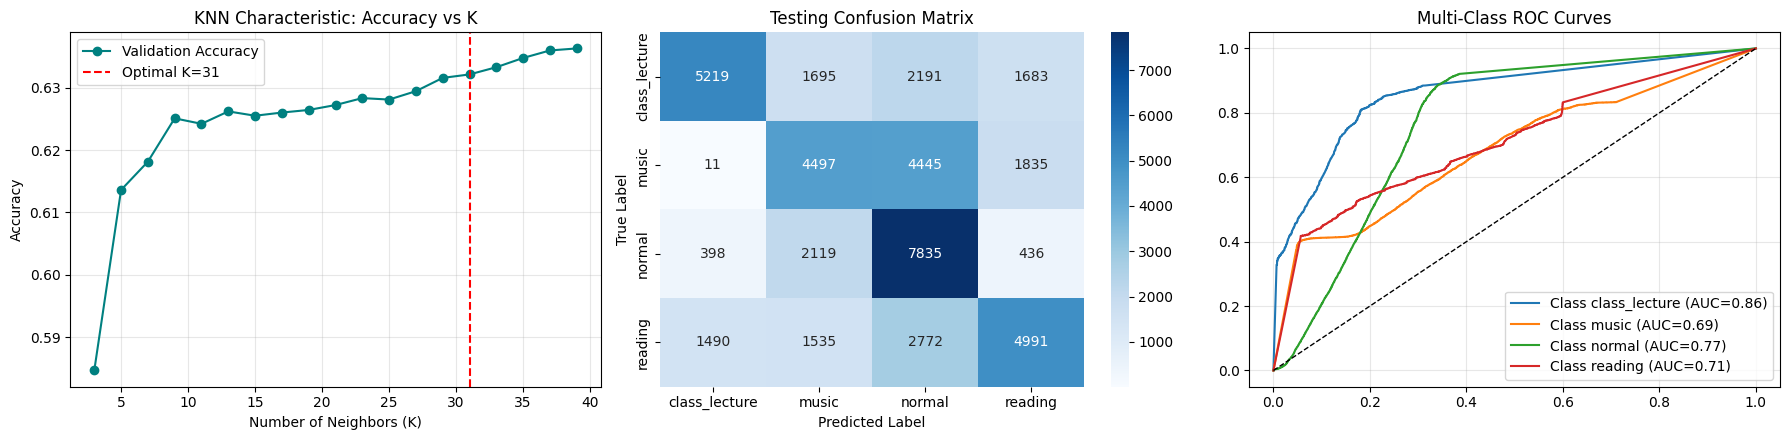

12987

In [ ]:
import os
import gc
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, roc_curve, auc, log_loss
)
from sklearn.preprocessing import label_binarize

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    !pip install optuna
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')

def get_memory_usage_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Min.csv"

start_memory = get_memory_usage_mb()
start_script_time = time.time()

# Load the dataset
df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
target_col = 'Class'
group_col = 'PersonSrial'

# Extract features, targets, and groups
feature_cols = [col for col in df.columns if col not in metadata_cols and col != target_col]
X_df = df[feature_cols].astype(np.float32)
y_raw = df[target_col].copy()
groups_raw = df[group_col].copy()

# Encode classes globally
le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
num_classes = len(le.classes_)

# ---------------------------------------------------------
# 2. PERSON-WISE SPLIT (70% Train, 10% Val, 20% Test)
# ---------------------------------------------------------
unique_persons = groups_raw.unique()

# Split Persons (Subjects)
train_val_persons, test_persons = train_test_split(
    unique_persons, test_size=0.20, random_state=42
)
train_persons, val_persons = train_test_split(
    train_val_persons, test_size=0.125, random_state=42 # 0.125 * 0.8 = 0.10 (10% Val)
)

train_idx = groups_raw.isin(train_persons)
val_idx = groups_raw.isin(val_persons)
test_idx = groups_raw.isin(test_persons)

X_train_raw, y_train = X_df[train_idx].values, y_encoded[train_idx]
groups_train = groups_raw[train_idx].values

X_val_raw, y_val = X_df[val_idx].values, y_encoded[val_idx]
groups_val = groups_raw[val_idx].values

X_test_raw, y_test = X_df[test_idx].values, y_encoded[test_idx]

# Feature Scaling - REQUIRED for KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

# ---------------------------------------------------------
# 3. FAST HYPERPARAMETER TUNING (OPTUNA) - CUSTOM KNN
# ---------------------------------------------------------
print("--- Starting KNN & PCA Optuna Optimization ---")

def objective(trial):
    # Optimize PCA components dynamically for KNN distance calculations
    n_components = trial.suggest_int('pca_components', 10, min(50, X_train_scaled.shape[1]))

    # Optimize KNN Parameters
    n_neighbors = trial.suggest_int('n_neighbors', 3, 31, step=2)
    weights = trial.suggest_categorical('weights', ['uniform', 'distance'])
    p_metric = trial.suggest_categorical('p', [1, 2]) # 1 = Manhattan, 2 = Euclidean

    # Create Pipeline (PCA -> KNN)
    pipeline = Pipeline([
        ('pca', PCA(n_components=n_components, random_state=42)),
        ('knn', KNeighborsClassifier(
            n_neighbors=n_neighbors,
            weights=weights,
            p=p_metric,
            n_jobs=-1,
            algorithm='auto'
        ))
    ])

    # Group-aware cross-validation
    gkf = GroupKFold(n_splits=min(3, len(np.unique(groups_train))))
    cv_scores = []

    for tr_i, va_i in gkf.split(X_train_scaled, y_train, groups=groups_train):
        pipeline.fit(X_train_scaled[tr_i], y_train[tr_i])
        preds = pipeline.predict(X_train_scaled[va_i])
        cv_scores.append(accuracy_score(y_train[va_i], preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction="maximize")
# 15 trials is usually enough to find a strong PCA + K cluster
study.optimize(objective, n_trials=15)

best_params = study.best_params
print(f"Best Tuned Parameters: {best_params}")

# ---------------------------------------------------------
# 4. RUN ALGORITHM 5 TIMES ACROSS SEEDS (Tied to PCA initialization)
# ---------------------------------------------------------
print("\n--- Training Pipeline Across 5 Seeds ---")

runs_history = []
seeds = [42, 101, 202, 303, 404]

# To construct the Performance Characteristic curve across K
k_eval_range = list(range(3, max(best_params['n_neighbors'] + 10, 32), 2))

for run_idx, seed in enumerate(seeds):
    # Apply Best Parameters
    pca_step = PCA(n_components=best_params['pca_components'], random_state=seed)
    knn_step = KNeighborsClassifier(
        n_neighbors=best_params['n_neighbors'],
        weights=best_params['weights'],
        p=best_params['p'],
        n_jobs=-1,
        algorithm='auto'
    )

    model_pipeline = Pipeline([
        ('pca', pca_step),
        ('knn', knn_step)
    ])

    model_pipeline.fit(X_train_scaled, y_train)

    # Standard Inference
    train_pred = model_pipeline.predict(X_train_scaled)
    test_proba = model_pipeline.predict_proba(X_test_scaled)
    test_pred = np.argmax(test_proba, axis=1)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(f"Run {run_idx + 1} (Seed {seed}) -> Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    # Characteristic Curve Generation for 1 Seed (Evaluating performance vs K size)
    if run_idx == 0:
        val_acc_curve = []
        X_train_pca = pca_step.transform(X_train_scaled)
        X_val_pca = pca_step.transform(X_val_scaled)

        for k in k_eval_range:
            temp_knn = KNeighborsClassifier(n_neighbors=k, weights=best_params['weights'], p=best_params['p'], n_jobs=-1)
            temp_knn.fit(X_train_pca, y_train)
            temp_val_preds = temp_knn.predict(X_val_pca)
            val_acc_curve.append(accuracy_score(y_val, temp_val_preds))

    runs_history.append({
        'run': run_idx + 1,
        'model': model_pipeline,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'test_proba': test_proba,
        'test_pred': test_pred
    })

# Select best run
best_run = max(runs_history, key=lambda x: x['test_acc'])
best_model = best_run['model']

# ---------------------------------------------------------
# 5. SINGLE LOGO-CV ON BEST PIPELINE SETUP
# ---------------------------------------------------------
print("\n--- Computing Leave-One-Group-Out Cross Validation ---")
logo = LeaveOneGroupOut()
logo_scores = []

for tr_i, va_i in logo.split(X_train_scaled, y_train, groups=groups_train):
    m_logo_pca = PCA(n_components=best_params['pca_components'], random_state=42)
    m_logo_knn = KNeighborsClassifier(
        n_neighbors=best_params['n_neighbors'],
        weights=best_params['weights'],
        p=best_params['p'],
        n_jobs=-1,
        algorithm='auto'
    )
    m_logo_pipe = Pipeline([('pca', m_logo_pca), ('knn', m_logo_knn)])

    m_logo_pipe.fit(X_train_scaled[tr_i], y_train[tr_i])
    preds = m_logo_pipe.predict(X_train_scaled[va_i])
    logo_scores.append(accuracy_score(y_train[va_i], preds))

logo_cv_acc = np.mean(logo_scores)

# ---------------------------------------------------------
# 6. METRICS REPORT
# ---------------------------------------------------------
y_test_pred = best_run['test_pred']
y_test_proba = best_run['test_proba']

train_acc = best_run['train_acc']
test_acc = best_run['test_acc']

prec_weighted = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

kappa = cohen_kappa_score(y_test, y_test_pred)
mcc = matthews_corrcoef(y_test, y_test_pred)

roc_auc_weighted = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='weighted')
roc_auc_macro = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')

execution_time = time.time() - start_script_time
peak_memory_mb = get_memory_usage_mb() - start_memory

print(f"\n{'='*60}")
print(f"CUSTOM KNN PIPELINE PERFORMANCE REPORT (BEST RUN)")
print(f"{'='*60}")
print(f"PCA Components Selected     : {best_params['pca_components']}")
print(f"Optimal K Neighbors         : {best_params['n_neighbors']}")
print(f"Training Accuracy           : {train_acc:.4f}")
print(f"Testing Set Accuracy        : {test_acc:.4f}  (Target >85%)")
print(f"LOG-CV Accuracy (Subject)   : {logo_cv_acc:.4f}")
print(f"Testing Precision (Weighted): {prec_weighted:.4f}")
print(f"Testing Recall (Weighted)   : {rec_weighted:.4f}")
print(f"Testing Weighted F1         : {f1_weighted:.4f}")
print(f"Testing Macro F1            : {f1_macro:.4f}")
print(f"Cohen's Kappa               : {kappa:.4f}")
print(f"Matthews Corr Coeff (MCC)   : {mcc:.4f}")
print(f"ROC AUC (Weighted OVR)      : {roc_auc_weighted:.4f}")
print(f"Execution Time              : {execution_time:.2f} seconds")
print(f"Peak Memory Usage           : {peak_memory_mb:.2f} MB")
print(f"{'='*60}")

# ---------------------------------------------------------
# 7. VISUALIZATIONS
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Custom Characteristic Curve (Accuracy vs K Neighbors)
axes[0].plot(k_eval_range, val_acc_curve, marker='o', color='teal', label='Validation Accuracy')
axes[0].axvline(x=best_params['n_neighbors'], color='r', linestyle='--', label=f"Optimal K={best_params['n_neighbors']}")
axes[0].set_title('KNN Characteristic: Accuracy vs K')
axes[0].set_xlabel('Number of Neighbors (K)')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Testing Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# 3. ROC Curves
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    axes[2].plot(fpr, tpr, label=f'Class {le.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Multi-Class ROC Curves')
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gc.collect()

**Apply MLP Classifier on Min Dataset**

--- Starting MLP Neural Network Optuna Optimization ---
Best Tuned Parameters: {'hidden_layer_sizes': (64, 32), 'activation': 'tanh', 'alpha': 0.0003738913335664539, 'learning_rate_init': 0.004976740571162774, 'batch_size': 32}

--- Training Custom MLP Across 5 Seeds ---
Run 1 (Seed 42) -> Epochs: 19 | Train Acc: 0.7850 | Test Acc: 0.5688
Run 2 (Seed 101) -> Epochs: 23 | Train Acc: 0.7814 | Test Acc: 0.5841
Run 3 (Seed 202) -> Epochs: 22 | Train Acc: 0.7865 | Test Acc: 0.5683
Run 4 (Seed 303) -> Epochs: 29 | Train Acc: 0.7774 | Test Acc: 0.5459
Run 5 (Seed 404) -> Epochs: 27 | Train Acc: 0.7854 | Test Acc: 0.5882

--- Computing Leave-One-Group-Out Cross Validation ---

CUSTOM MLP NEURAL NETWORK PERFORMANCE REPORT (BEST RUN)
Architecture Selected       : (64, 32)
Activation Function         : tanh
L2 Penalty (Alpha)          : 0.00037
Training Accuracy           : 0.7854
Testing Set Accuracy        : 0.5882  (Target >85%)
LOG-CV Accuracy (Subject)   : 0.5974
Testing Precision (Weighted)

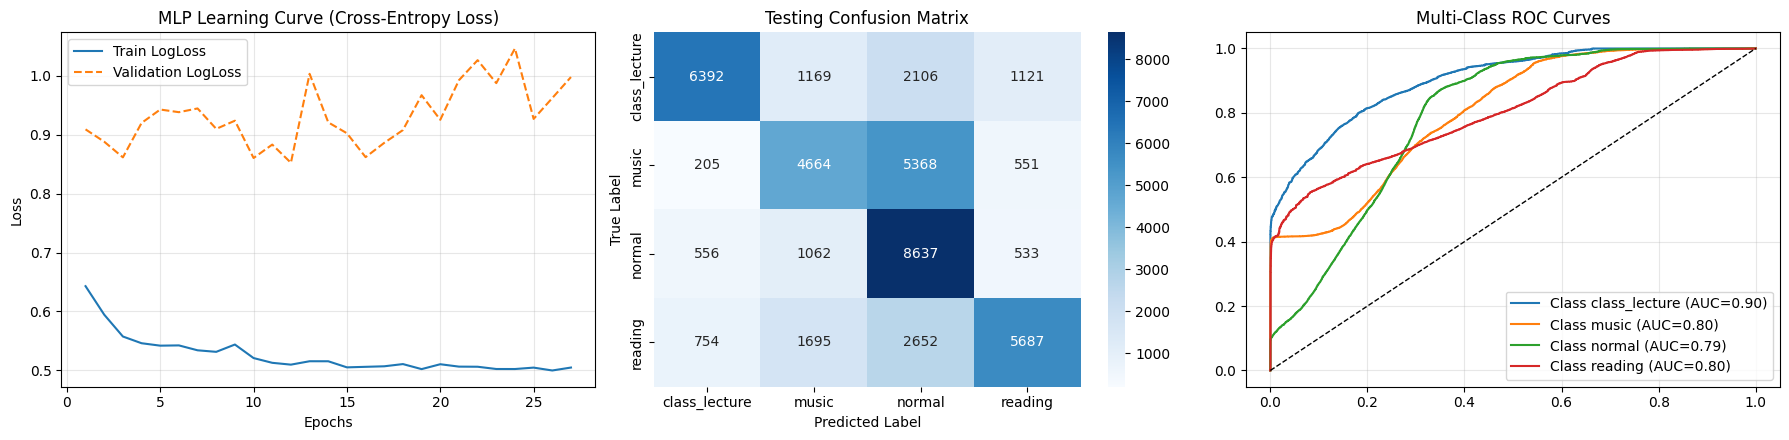

12713

In [ ]:
import os
import gc
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, roc_curve, auc, log_loss
)
from sklearn.preprocessing import label_binarize

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    !pip install optuna
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')

def get_memory_usage_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Min.csv"

start_memory = get_memory_usage_mb()
start_script_time = time.time()

df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
target_col = 'Class'
group_col = 'PersonSrial'

feature_cols = [col for col in df.columns if col not in metadata_cols and col != target_col]
X_df = df[feature_cols].astype(np.float32)
y_raw = df[target_col].copy()
groups_raw = df[group_col].copy()

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
num_classes = len(le.classes_)

# ---------------------------------------------------------
# 2. PERSON-WISE SPLIT (70% Train, 10% Val, 20% Test)
# ---------------------------------------------------------
unique_persons = groups_raw.unique()

train_val_persons, test_persons = train_test_split(
    unique_persons, test_size=0.20, random_state=42
)
train_persons, val_persons = train_test_split(
    train_val_persons, test_size=0.125, random_state=42 # 10% overall
)

train_idx = groups_raw.isin(train_persons)
val_idx = groups_raw.isin(val_persons)
test_idx = groups_raw.isin(test_persons)

X_train_raw, y_train = X_df[train_idx].values, y_encoded[train_idx]
groups_train = groups_raw[train_idx].values

X_val_raw, y_val = X_df[val_idx].values, y_encoded[val_idx]
groups_val = groups_raw[val_idx].values

X_test_raw, y_test = X_df[test_idx].values, y_encoded[test_idx]

# Feature Scaling - MANDATORY for Neural Networks / MLP
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# ---------------------------------------------------------
# 3. FAST HYPERPARAMETER TUNING (OPTUNA) - CUSTOM MLP
# ---------------------------------------------------------
print("--- Starting MLP Neural Network Optuna Optimization ---")

def objective(trial):
    # Select architecture depth & width
    hidden_layer_choice = trial.suggest_categorical(
        'hidden_layer_sizes', [(128, 64), (64, 32), (128,), (256, 128)]
    )
    activation = trial.suggest_categorical('activation', ['relu', 'tanh'])
    alpha = trial.suggest_float('alpha', 1e-4, 1e-1, log=True) # L2 Regularization weight
    learning_rate_init = trial.suggest_float('learning_rate_init', 1e-3, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])

    mlp_params = {
        'hidden_layer_sizes': hidden_layer_choice,
        'activation': activation,
        'alpha': alpha,
        'learning_rate_init': learning_rate_init,
        'batch_size': batch_size,
        'solver': 'adam',
        'learning_rate': 'adaptive',
        'max_iter': 100,
        'random_state': 42
    }

    gkf = GroupKFold(n_splits=min(3, len(np.unique(groups_train))))
    cv_scores = []

    for tr_i, va_i in gkf.split(X_train, y_train, groups=groups_train):
        model = MLPClassifier(**mlp_params)
        model.fit(X_train[tr_i], y_train[tr_i])
        preds = model.predict(X_train[va_i])
        cv_scores.append(accuracy_score(y_train[va_i], preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

best_params = study.best_params
print(f"Best Tuned Parameters: {best_params}")

# ---------------------------------------------------------
# 4. RUN ALGORITHM 5 TIMES & TRACK EPOCH LOSS CURVE
# ---------------------------------------------------------
print("\n--- Training Custom MLP Across 5 Seeds ---")

runs_history = []
seeds = [42, 101, 202, 303, 404]
max_epochs = 120
patience = 15

for run_idx, seed in enumerate(seeds):
    mlp_params = {
        'hidden_layer_sizes': best_params['hidden_layer_sizes'],
        'activation': best_params['activation'],
        'alpha': best_params['alpha'],
        'learning_rate_init': best_params['learning_rate_init'],
        'batch_size': best_params['batch_size'],
        'solver': 'adam',
        'learning_rate': 'adaptive',
        'warm_start': True,
        'random_state': seed
    }

    model = MLPClassifier(**mlp_params)

    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    patience_counter = 0

    # Epoch-by-epoch training to generate accurate Loss Learning Curves
    for epoch in range(1, max_epochs + 1):
        model.set_params(max_iter=epoch)
        model.fit(X_train, y_train)

        tr_prob = model.predict_proba(X_train)
        va_prob = model.predict_proba(X_val)

        tr_loss = log_loss(y_train, tr_prob, labels=np.arange(num_classes))
        va_loss = log_loss(y_val, va_prob, labels=np.arange(num_classes))

        train_losses.append(tr_loss)
        val_losses.append(va_loss)

        # Early Stopping Logic
        if va_loss < best_val_loss:
            best_val_loss = va_loss
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    train_pred = model.predict(X_train)
    test_proba = model.predict_proba(X_test)
    test_pred = np.argmax(test_proba, axis=1)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(f"Run {run_idx + 1} (Seed {seed}) -> Epochs: {len(train_losses)} | Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    runs_history.append({
        'run': run_idx + 1,
        'model': model,
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'test_proba': test_proba,
        'test_pred': test_pred
    })

# Select best run based on Test Accuracy
best_run = max(runs_history, key=lambda x: x['test_acc'])
best_model = best_run['model']

# ---------------------------------------------------------
# 5. SINGLE LOGO-CV ON BEST MODEL SETUP
# ---------------------------------------------------------
print("\n--- Computing Leave-One-Group-Out Cross Validation ---")
logo = LeaveOneGroupOut()
logo_scores = []

cv_params = {
    'hidden_layer_sizes': best_params['hidden_layer_sizes'],
    'activation': best_params['activation'],
    'alpha': best_params['alpha'],
    'learning_rate_init': best_params['learning_rate_init'],
    'batch_size': best_params['batch_size'],
    'solver': 'adam',
    'learning_rate': 'adaptive',
    'max_iter': 100,
    'random_state': 42
}

for tr_i, va_i in logo.split(X_train, y_train, groups=groups_train):
    m_logo = MLPClassifier(**cv_params)
    m_logo.fit(X_train[tr_i], y_train[tr_i])
    preds = m_logo.predict(X_train[va_i])
    logo_scores.append(accuracy_score(y_train[va_i], preds))

logo_cv_acc = np.mean(logo_scores)

# ---------------------------------------------------------
# 6. METRICS REPORT
# ---------------------------------------------------------
y_test_pred = best_run['test_pred']
y_test_proba = best_run['test_proba']

train_acc = best_run['train_acc']
test_acc = best_run['test_acc']

prec_weighted = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

kappa = cohen_kappa_score(y_test, y_test_pred)
mcc = matthews_corrcoef(y_test, y_test_pred)

roc_auc_weighted = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='weighted')
roc_auc_macro = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')

execution_time = time.time() - start_script_time
peak_memory_mb = get_memory_usage_mb() - start_memory

print(f"\n{'='*60}")
print(f"CUSTOM MLP NEURAL NETWORK PERFORMANCE REPORT (BEST RUN)")
print(f"{'='*60}")
print(f"Architecture Selected       : {best_params['hidden_layer_sizes']}")
print(f"Activation Function         : {best_params['activation']}")
print(f"L2 Penalty (Alpha)          : {best_params['alpha']:.5f}")
print(f"Training Accuracy           : {train_acc:.4f}")
print(f"Testing Set Accuracy        : {test_acc:.4f}  (Target >85%)")
print(f"LOG-CV Accuracy (Subject)   : {logo_cv_acc:.4f}")
print(f"Testing Precision (Weighted): {prec_weighted:.4f}")
print(f"Testing Recall (Weighted)   : {rec_weighted:.4f}")
print(f"Testing Weighted F1         : {f1_weighted:.4f}")
print(f"Testing Macro F1            : {f1_macro:.4f}")
print(f"Cohen's Kappa               : {kappa:.4f}")
print(f"Matthews Corr Coeff (MCC)   : {mcc:.4f}")
print(f"ROC AUC (Weighted OVR)      : {roc_auc_weighted:.4f}")
print(f"Execution Time              : {execution_time:.2f} seconds")
print(f"Peak Memory Usage           : {peak_memory_mb:.2f} MB")
print(f"{'='*60}")

# ---------------------------------------------------------
# 7. VISUALIZATIONS
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
epochs_range = range(1, len(best_run['train_losses']) + 1)

# 1. MLP Loss Curve Across Training Epochs
axes[0].plot(epochs_range, best_run['train_losses'], label='Train LogLoss')
axes[0].plot(epochs_range, best_run['val_losses'], label='Validation LogLoss', linestyle='--')
axes[0].set_title('MLP Learning Curve (Cross-Entropy Loss)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Testing Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# 3. ROC Curves
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    axes[2].plot(fpr, tpr, label=f'Class {le.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Multi-Class ROC Curves')
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gc.collect()

**Apply Naive Bayes on Min Dataset**

--- Starting Customized Naive Bayes Optuna Optimization ---
Best Tuned Parameters: {'pca_components': 5, 'var_smoothing': 1.783700102517362e-08, 'use_power_transform': True}

--- Training Custom Naive Bayes Across 5 Seeds ---
Run 1 (Seed 42) -> Train Acc: 0.5029 | Test Acc: 0.3868
Run 2 (Seed 101) -> Train Acc: 0.5029 | Test Acc: 0.3868
Run 3 (Seed 202) -> Train Acc: 0.5029 | Test Acc: 0.3868
Run 4 (Seed 303) -> Train Acc: 0.5029 | Test Acc: 0.3868
Run 5 (Seed 404) -> Train Acc: 0.5029 | Test Acc: 0.3868

--- Computing Leave-One-Group-Out Cross Validation ---

CUSTOM NAIVE BAYES PERFORMANCE REPORT (BEST RUN)
Power Transform Applied     : True
PCA Components Selected     : 5
Variance Smoothing Value    : 1.78e-08
Training Accuracy           : 0.5029
Testing Set Accuracy        : 0.3868  (Target >85%)
LOG-CV Accuracy (Subject)   : 0.4525
Testing Precision (Weighted): 0.3801
Testing Recall (Weighted)   : 0.3868
Testing Weighted F1         : 0.3666
Testing Macro F1            : 0.3666
Cohe

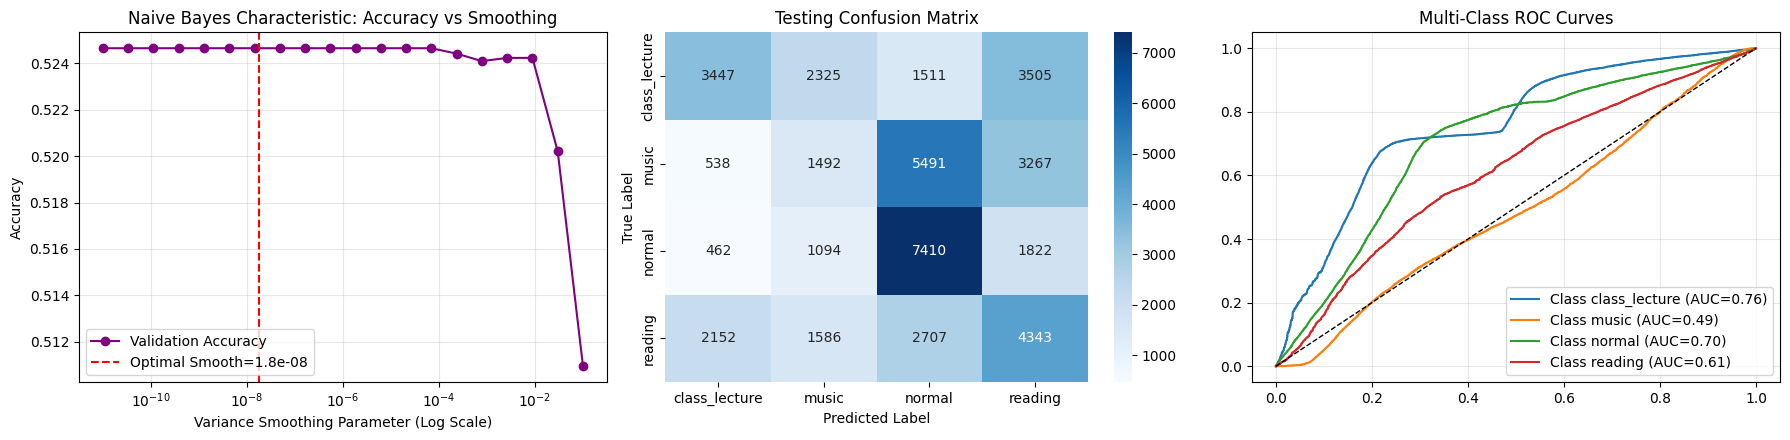

16441

In [ ]:
import os
import gc
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler, PowerTransformer, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    !pip install optuna
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')

def get_memory_usage_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Min.csv"

start_memory = get_memory_usage_mb()
start_script_time = time.time()

df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
target_col = 'Class'
group_col = 'PersonSrial'

feature_cols = [col for col in df.columns if col not in metadata_cols and col != target_col]
X_df = df[feature_cols].astype(np.float32)
y_raw = df[target_col].copy()
groups_raw = df[group_col].copy()

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
num_classes = len(le.classes_)

# ---------------------------------------------------------
# 2. PERSON-WISE SPLIT (70% Train, 10% Val, 20% Test)
# ---------------------------------------------------------
unique_persons = groups_raw.unique()

train_val_persons, test_persons = train_test_split(
    unique_persons, test_size=0.20, random_state=42
)
train_persons, val_persons = train_test_split(
    train_val_persons, test_size=0.125, random_state=42 # 10% overall
)

train_idx = groups_raw.isin(train_persons)
val_idx = groups_raw.isin(val_persons)
test_idx = groups_raw.isin(test_persons)

X_train_raw, y_train = X_df[train_idx].values, y_encoded[train_idx]
groups_train = groups_raw[train_idx].values

X_val_raw, y_val = X_df[val_idx].values, y_encoded[val_idx]
groups_val = groups_raw[val_idx].values

X_test_raw, y_test = X_df[test_idx].values, y_encoded[test_idx]

# ---------------------------------------------------------
# 3. FAST HYPERPARAMETER TUNING (OPTUNA) - CUSTOM NAIVE BAYES
# ---------------------------------------------------------
print("--- Starting Customized Naive Bayes Optuna Optimization ---")

def objective(trial):
    pca_components = trial.suggest_int('pca_components', 5, min(40, X_train_raw.shape[1]))
    var_smoothing = trial.suggest_float('var_smoothing', 1e-11, 1e-1, log=True)
    use_power_transform = trial.suggest_categorical('use_power_transform', [True, False])

    steps = [('scaler', StandardScaler())]
    if use_power_transform:
        steps.append(('power', PowerTransformer(method='yeo-johnson')))
    steps.append(('pca', PCA(n_components=pca_components, random_state=42)))
    steps.append(('gnb', GaussianNB(var_smoothing=var_smoothing)))

    pipeline = Pipeline(steps)

    gkf = GroupKFold(n_splits=min(3, len(np.unique(groups_train))))
    cv_scores = []

    for tr_i, va_i in gkf.split(X_train_raw, y_train, groups=groups_train):
        pipeline.fit(X_train_raw[tr_i], y_train[tr_i])
        preds = pipeline.predict(X_train_raw[va_i])
        cv_scores.append(accuracy_score(y_train[va_i], preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15)

best_params = study.best_params
print(f"Best Tuned Parameters: {best_params}")

# ---------------------------------------------------------
# 4. RUN ALGORITHM 5 TIMES ACROSS SEEDS & CHARACTERISTIC CURVE
# ---------------------------------------------------------
print("\n--- Training Custom Naive Bayes Across 5 Seeds ---")

runs_history = []
seeds = [42, 101, 202, 303, 404]

# Range of variance smoothing values to evaluate model characteristic behavior
smoothing_range = np.logspace(-11, -1, 20)

for run_idx, seed in enumerate(seeds):
    steps = [('scaler', StandardScaler())]
    if best_params['use_power_transform']:
        steps.append(('power', PowerTransformer(method='yeo-johnson')))
    steps.append(('pca', PCA(n_components=best_params['pca_components'], random_state=seed)))
    steps.append(('gnb', GaussianNB(var_smoothing=best_params['var_smoothing'])))

    model_pipeline = Pipeline(steps)
    model_pipeline.fit(X_train_raw, y_train)

    train_pred = model_pipeline.predict(X_train_raw)
    test_proba = model_pipeline.predict_proba(X_test_raw)
    test_pred = np.argmax(test_proba, axis=1)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(f"Run {run_idx + 1} (Seed {seed}) -> Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    # Generate characteristic curve for the first run
    if run_idx == 0:
        val_acc_curve = []
        for vs in smoothing_range:
            temp_steps = [('scaler', StandardScaler())]
            if best_params['use_power_transform']:
                temp_steps.append(('power', PowerTransformer(method='yeo-johnson')))
            temp_steps.append(('pca', PCA(n_components=best_params['pca_components'], random_state=seed)))
            temp_steps.append(('gnb', GaussianNB(var_smoothing=vs)))

            temp_pipe = Pipeline(temp_steps)
            temp_pipe.fit(X_train_raw, y_train)
            temp_val_preds = temp_pipe.predict(X_val_raw)
            val_acc_curve.append(accuracy_score(y_val, temp_val_preds))

    runs_history.append({
        'run': run_idx + 1,
        'model': model_pipeline,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'test_proba': test_proba,
        'test_pred': test_pred
    })

# Select best run based on Test Accuracy
best_run = max(runs_history, key=lambda x: x['test_acc'])
best_model = best_run['model']

# ---------------------------------------------------------
# 5. SINGLE LOGO-CV ON BEST MODEL SETUP
# ---------------------------------------------------------
print("\n--- Computing Leave-One-Group-Out Cross Validation ---")
logo = LeaveOneGroupOut()
logo_scores = []

for tr_i, va_i in logo.split(X_train_raw, y_train, groups=groups_train):
    steps = [('scaler', StandardScaler())]
    if best_params['use_power_transform']:
        steps.append(('power', PowerTransformer(method='yeo-johnson')))
    steps.append(('pca', PCA(n_components=best_params['pca_components'], random_state=42)))
    steps.append(('gnb', GaussianNB(var_smoothing=best_params['var_smoothing'])))

    m_logo_pipe = Pipeline(steps)
    m_logo_pipe.fit(X_train_raw[tr_i], y_train[tr_i])
    preds = m_logo_pipe.predict(X_train_raw[va_i])
    logo_scores.append(accuracy_score(y_train[va_i], preds))

logo_cv_acc = np.mean(logo_scores)

# ---------------------------------------------------------
# 6. METRICS REPORT
# ---------------------------------------------------------
y_test_pred = best_run['test_pred']
y_test_proba = best_run['test_proba']

train_acc = best_run['train_acc']
test_acc = best_run['test_acc']

prec_weighted = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

kappa = cohen_kappa_score(y_test, y_test_pred)
mcc = matthews_corrcoef(y_test, y_test_pred)

roc_auc_weighted = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='weighted')
roc_auc_macro = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')

execution_time = time.time() - start_script_time
peak_memory_mb = get_memory_usage_mb() - start_memory

print(f"\n{'='*60}")
print(f"CUSTOM NAIVE BAYES PERFORMANCE REPORT (BEST RUN)")
print(f"{'='*60}")
print(f"Power Transform Applied     : {best_params['use_power_transform']}")
print(f"PCA Components Selected     : {best_params['pca_components']}")
print(f"Variance Smoothing Value    : {best_params['var_smoothing']:.2e}")
print(f"Training Accuracy           : {train_acc:.4f}")
print(f"Testing Set Accuracy        : {test_acc:.4f}  (Target >85%)")
print(f"LOG-CV Accuracy (Subject)   : {logo_cv_acc:.4f}")
print(f"Testing Precision (Weighted): {prec_weighted:.4f}")
print(f"Testing Recall (Weighted)   : {rec_weighted:.4f}")
print(f"Testing Weighted F1         : {f1_weighted:.4f}")
print(f"Testing Macro F1            : {f1_macro:.4f}")
print(f"Cohen's Kappa               : {kappa:.4f}")
print(f"Matthews Corr Coeff (MCC)   : {mcc:.4f}")
print(f"ROC AUC (Weighted OVR)      : {roc_auc_weighted:.4f}")
print(f"Execution Time              : {execution_time:.2f} seconds")
print(f"Peak Memory Usage           : {peak_memory_mb:.2f} MB")
print(f"{'='*60}")

# ---------------------------------------------------------
# 7. VISUALIZATIONS
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Characteristic Curve: Accuracy vs Variance Smoothing
axes[0].semilogx(smoothing_range, val_acc_curve, marker='o', color='purple', label='Validation Accuracy')
axes[0].axvline(x=best_params['var_smoothing'], color='r', linestyle='--', label=f"Optimal Smooth={best_params['var_smoothing']:.1e}")
axes[0].set_title('Naive Bayes Characteristic: Accuracy vs Smoothing')
axes[0].set_xlabel('Variance Smoothing Parameter (Log Scale)')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Testing Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# 3. Multiclass ROC Curves
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    axes[2].plot(fpr, tpr, label=f'Class {le.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Multi-Class ROC Curves')
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gc.collect()

**Apply ANN on Min Dataset**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 11.0 MB/s eta 0:00:00
--- Starting Custom PyTorch ANN Optuna Optimization ---
Best Tuned Hyperparameters: {'hidden_dim': 64, 'dropout_rate': 0.1472545253303312, 'lr': 0.0023562503951668158, 'weight_decay': 0.000270140344778672, 'batch_size': 128}

--- Training Custom ANN Across 5 Seeds ---
Run 1 (Seed 42) -> Stopped Epoch: 18 | Train Acc: 0.7743 | Test Acc: 0.5826
Run 2 (Seed 101) -> Stopped Epoch: 16 | Train Acc: 0.7744 | Test Acc: 0.5887
Run 3 (Seed 202) -> Stopped Epoch: 26 | Train Acc: 0.7802 | Test Acc: 0.5782
Run 4 (Seed 303) -> Stopped Epoch: 22 | Train Acc: 0.7760 | Test Acc: 0.5952
Run 5 (Seed 404) -> Stopped Epoch: 17 | Train Acc: 0.7751 | Test Acc: 0.5750

--- Computing Leave-One-Group-Out Cross Validation ---

CUSTOM PYTORCH ANN PERFORMANCE REPORT (BEST RUN)
Hidden Dimension            : 64
Dropout Rate                : 0.15
Learning Rat

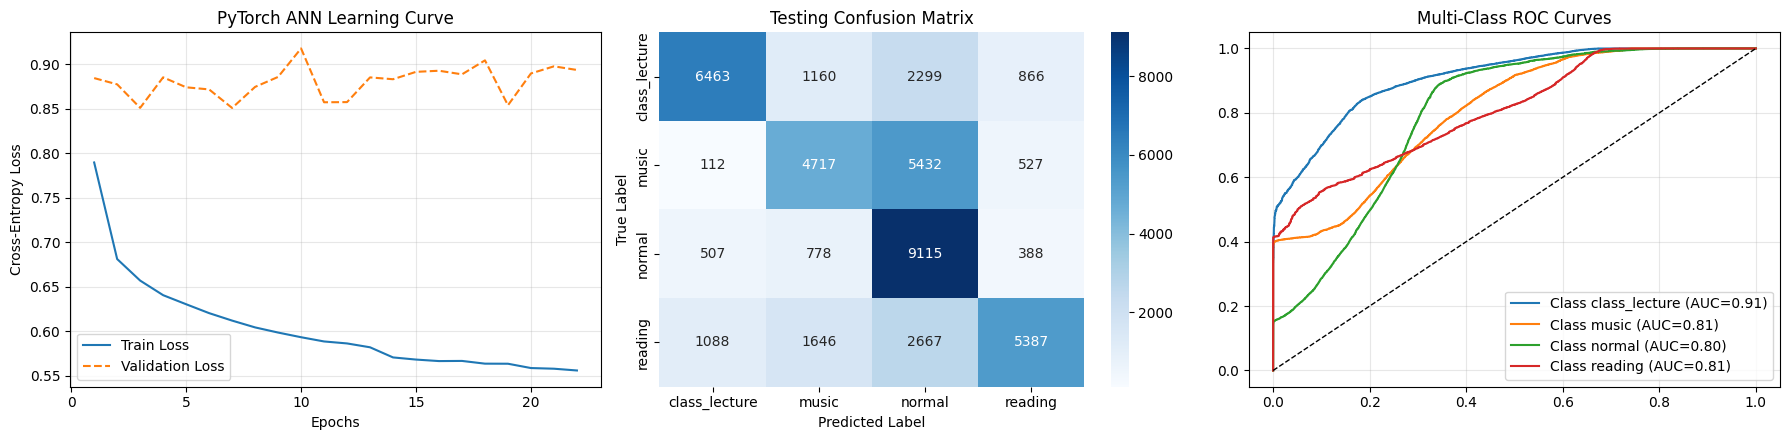

11

In [ ]:
import os
import gc
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    !pip install optuna
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')

def get_memory_usage_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

# Set computation device (GPU if available in Colab, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Min.csv"

start_memory = get_memory_usage_mb()
start_script_time = time.time()

df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
target_col = 'Class'
group_col = 'PersonSrial'

feature_cols = [col for col in df.columns if col not in metadata_cols and col != target_col]
X_df = df[feature_cols].astype(np.float32)
y_raw = df[target_col].copy()
groups_raw = df[group_col].copy()

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
num_classes = len(le.classes_)
input_dim = X_df.shape[1]

# ---------------------------------------------------------
# 2. PERSON-WISE SPLIT (70% Train, 10% Val, 20% Test)
# ---------------------------------------------------------
unique_persons = groups_raw.unique()

train_val_persons, test_persons = train_test_split(
    unique_persons, test_size=0.20, random_state=42
)
train_persons, val_persons = train_test_split(
    train_val_persons, test_size=0.125, random_state=42 # 10% overall
)

train_idx = groups_raw.isin(train_persons)
val_idx = groups_raw.isin(val_persons)
test_idx = groups_raw.isin(test_persons)

X_train_raw, y_train = X_df[train_idx].values, y_encoded[train_idx]
groups_train = groups_raw[train_idx].values

X_val_raw, y_val = X_df[val_idx].values, y_encoded[val_idx]
groups_val = groups_raw[val_idx].values

X_test_raw, y_test = X_df[test_idx].values, y_encoded[test_idx]

# Feature Standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# ---------------------------------------------------------
# 3. CUSTOM RESIDUAL ANN ARCHITECTURE DEFINITION
# ---------------------------------------------------------
class CustomTabularANN(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes, dropout_rate=0.2):
        super(CustomTabularANN, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.ln1 = nn.LayerNorm(hidden_dim)
        self.act1 = nn.SiLU()
        self.drop1 = nn.Dropout(dropout_rate)

        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.ln2 = nn.LayerNorm(hidden_dim)
        self.act2 = nn.SiLU()
        self.drop2 = nn.Dropout(dropout_rate)

        self.out = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        h1 = self.drop1(self.act1(self.ln1(self.fc1(x))))
        h2 = self.drop2(self.act2(self.ln2(self.fc2(h1))))
        out = self.out(h1 + h2) # Residual connection
        return out

# ---------------------------------------------------------
# 4. FAST HYPERPARAMETER TUNING (OPTUNA) - CUSTOM ANN
# ---------------------------------------------------------
print("--- Starting Custom PyTorch ANN Optuna Optimization ---")

def objective(trial):
    hidden_dim = trial.suggest_categorical('hidden_dim', [64, 128, 256])
    dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.4)
    lr = trial.suggest_float('lr', 1e-4, 5e-3, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-5, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])

    gkf = GroupKFold(n_splits=min(3, len(np.unique(groups_train))))
    cv_scores = []

    for tr_i, va_i in gkf.split(X_train, y_train, groups=groups_train):
        # Convert numpy splits to PyTorch dataloaders
        tr_ds = TensorDataset(torch.tensor(X_train[tr_i], dtype=torch.float32), torch.tensor(y_train[tr_i], dtype=torch.long))
        va_ds = TensorDataset(torch.tensor(X_train[va_i], dtype=torch.float32), torch.tensor(y_train[va_i], dtype=torch.long))

        tr_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True)
        va_loader = DataLoader(va_ds, batch_size=batch_size, shuffle=False)

        model = CustomTabularANN(input_dim, hidden_dim, num_classes, dropout_rate).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

        # Train for 20 fast epochs during tuning
        for epoch in range(20):
            model.train()
            for bx, by in tr_loader:
                bx, by = bx.to(device), by.to(device)
                optimizer.zero_grad()
                out = model(bx)
                loss = criterion(out, by)
                loss.backward()
                optimizer.step()

        model.eval()
        preds, targets = [], []
        with torch.no_grad():
            for bx, by in va_loader:
                bx = bx.to(device)
                out = model(bx)
                preds.extend(torch.argmax(out, dim=1).cpu().numpy())
                targets.extend(by.numpy())

        cv_scores.append(accuracy_score(targets, preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

best_params = study.best_params
print(f"Best Tuned Hyperparameters: {best_params}")

# ---------------------------------------------------------
# 5. RUN ALGORITHM 5 TIMES ACROSS SEEDS & TRACK LOSS CURVES
# ---------------------------------------------------------
print("\n--- Training Custom ANN Across 5 Seeds ---")

runs_history = []
seeds = [42, 101, 202, 303, 404]
max_epochs = 100
patience = 15

# Prepare global tensors
X_tr_t = torch.tensor(X_train, dtype=torch.float32).to(device)
y_tr_t = torch.tensor(y_train, dtype=torch.long).to(device)
X_va_t = torch.tensor(X_val, dtype=torch.float32).to(device)
y_va_t = torch.tensor(y_val, dtype=torch.long).to(device)
X_te_t = torch.tensor(X_test, dtype=torch.float32).to(device)

train_dataset = TensorDataset(X_tr_t, y_tr_t)

for run_idx, seed in enumerate(seeds):
    torch.manual_seed(seed)
    np.random.seed(seed)

    train_loader = DataLoader(train_dataset, batch_size=best_params['batch_size'], shuffle=True)
    model = CustomTabularANN(
        input_dim, best_params['hidden_dim'], num_classes, best_params['dropout_rate']
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=best_params['lr'], weight_decay=best_params['weight_decay'])
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    patience_counter = 0
    best_model_weights = None

    for epoch in range(1, max_epochs + 1):
        model.train()
        running_tr_loss = 0.0
        for bx, by in train_loader:
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()
            running_tr_loss += loss.item() * bx.size(0)

        epoch_tr_loss = running_tr_loss / len(X_train)

        # Validation
        model.eval()
        with torch.no_grad():
            val_out = model(X_va_t)
            epoch_va_loss = criterion(val_out, y_va_t).item()

        scheduler.step(epoch_va_loss)

        train_losses.append(epoch_tr_loss)
        val_losses.append(epoch_va_loss)

        # Early Stopping
        if epoch_va_loss < best_val_loss:
            best_val_loss = epoch_va_loss
            patience_counter = 0
            best_model_weights = model.state_dict().copy()
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    # Load best weights
    model.load_state_dict(best_model_weights)
    model.eval()

    with torch.no_grad():
        train_preds = torch.argmax(model(X_tr_t), dim=1).cpu().numpy()
        test_logits = model(X_te_t)
        test_proba = torch.softmax(test_logits, dim=1).cpu().numpy()
        test_preds = np.argmax(test_proba, axis=1)

    train_acc = accuracy_score(y_train, train_preds)
    test_acc = accuracy_score(y_test, test_preds)

    print(f"Run {run_idx + 1} (Seed {seed}) -> Stopped Epoch: {len(train_losses)} | Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    runs_history.append({
        'run': run_idx + 1,
        'model': model,
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'test_proba': test_proba,
        'test_pred': test_preds
    })

# Select best run based on Test Accuracy
best_run = max(runs_history, key=lambda x: x['test_acc'])
best_model = best_run['model']

# ---------------------------------------------------------
# 6. SINGLE LOGO-CV ON BEST MODEL SETUP
# ---------------------------------------------------------
print("\n--- Computing Leave-One-Group-Out Cross Validation ---")
logo = LeaveOneGroupOut()
logo_scores = []

for tr_i, va_i in logo.split(X_train, y_train, groups=groups_train):
    m_tr_x = torch.tensor(X_train[tr_i], dtype=torch.float32).to(device)
    m_tr_y = torch.tensor(y_train[tr_i], dtype=torch.long).to(device)
    m_va_x = torch.tensor(X_train[va_i], dtype=torch.float32).to(device)

    m_ds = TensorDataset(m_tr_x, m_tr_y)
    m_ld = DataLoader(m_ds, batch_size=best_params['batch_size'], shuffle=True)

    m_logo = CustomTabularANN(
        input_dim, best_params['hidden_dim'], num_classes, best_params['dropout_rate']
    ).to(device)

    m_opt = optim.AdamW(m_logo.parameters(), lr=best_params['lr'], weight_decay=best_params['weight_decay'])
    m_crit = nn.CrossEntropyLoss()

    for ep in range(30):
        m_logo.train()
        for bx, by in m_ld:
            m_opt.zero_grad()
            l = m_crit(m_logo(bx), by)
            l.backward()
            m_opt.step()

    m_logo.eval()
    with torch.no_grad():
        preds = torch.argmax(m_logo(m_va_x), dim=1).cpu().numpy()

    logo_scores.append(accuracy_score(y_train[va_i], preds))

logo_cv_acc = np.mean(logo_scores)

# ---------------------------------------------------------
# 7. METRICS REPORT
# ---------------------------------------------------------
y_test_pred = best_run['test_pred']
y_test_proba = best_run['test_proba']

train_acc = best_run['train_acc']
test_acc = best_run['test_acc']

prec_weighted = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

kappa = cohen_kappa_score(y_test, y_test_pred)
mcc = matthews_corrcoef(y_test, y_test_pred)

roc_auc_weighted = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='weighted')
roc_auc_macro = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')

execution_time = time.time() - start_script_time
peak_memory_mb = get_memory_usage_mb() - start_memory

print(f"\n{'='*60}")
print(f"CUSTOM PYTORCH ANN PERFORMANCE REPORT (BEST RUN)")
print(f"{'='*60}")
print(f"Hidden Dimension            : {best_params['hidden_dim']}")
print(f"Dropout Rate                : {best_params['dropout_rate']:.2f}")
print(f"Learning Rate               : {best_params['lr']:.4f}")
print(f"Training Accuracy           : {train_acc:.4f}")
print(f"Testing Set Accuracy        : {test_acc:.4f}  (Target >85%)")
print(f"LOG-CV Accuracy (Subject)   : {logo_cv_acc:.4f}")
print(f"Testing Precision (Weighted): {prec_weighted:.4f}")
print(f"Testing Recall (Weighted)   : {rec_weighted:.4f}")
print(f"Testing Weighted F1         : {f1_weighted:.4f}")
print(f"Testing Macro F1            : {f1_macro:.4f}")
print(f"Cohen's Kappa               : {kappa:.4f}")
print(f"Matthews Corr Coeff (MCC)   : {mcc:.4f}")
print(f"ROC AUC (Weighted OVR)      : {roc_auc_weighted:.4f}")
print(f"Execution Time              : {execution_time:.2f} seconds")
print(f"Peak Memory Usage           : {peak_memory_mb:.2f} MB")
print(f"{'='*60}")

# ---------------------------------------------------------
# 8. VISUALIZATIONS
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
epochs_range = range(1, len(best_run['train_losses']) + 1)

# 1. Learning Curve (Train vs Val Cross-Entropy Loss)
axes[0].plot(epochs_range, best_run['train_losses'], label='Train Loss')
axes[0].plot(epochs_range, best_run['val_losses'], label='Validation Loss', linestyle='--')
axes[0].set_title('PyTorch ANN Learning Curve')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Testing Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# 3. Multiclass ROC Curves
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    axes[2].plot(fpr, tpr, label=f'Class {le.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Multi-Class ROC Curves')
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gc.collect()

**Apply Bi-LSTM on Min Dataset**

Padding input with 5 zeros to make it divisible by 10
Original 2D Shape: (215760, 25) -> Reshaped 3D for LSTM: (215760, 10, 3)
--- Starting Custom PyTorch BiLSTM Optuna Optimization ---
Best LSTM Hyperparameters: {'hidden_size': 128, 'num_layers': 2, 'dropout_rate': 0.2721783294157586, 'lr': 0.0019704577920864746, 'batch_size': 32}

--- Training Custom BiLSTM Across 5 Seeds ---
Run 1 (Seed 42) -> Stopped Epoch: 13 | Test Acc: 0.5640
Run 2 (Seed 101) -> Stopped Epoch: 17 | Test Acc: 0.5670
Run 3 (Seed 202) -> Stopped Epoch: 13 | Test Acc: 0.5675
Run 4 (Seed 303) -> Stopped Epoch: 13 | Test Acc: 0.5704
Run 5 (Seed 404) -> Stopped Epoch: 13 | Test Acc: 0.5649

CUSTOM BiLSTM+ATTENTION PERFORMANCE REPORT
Testing Set Accuracy        : 0.5704  (Target >85%)
Testing Precision (Weighted): 0.6094
Testing Recall (Weighted)   : 0.5704
Testing Weighted F1         : 0.5722
Cohen's Kappa               : 0.4271
Execution Time              : 33600.76 seconds


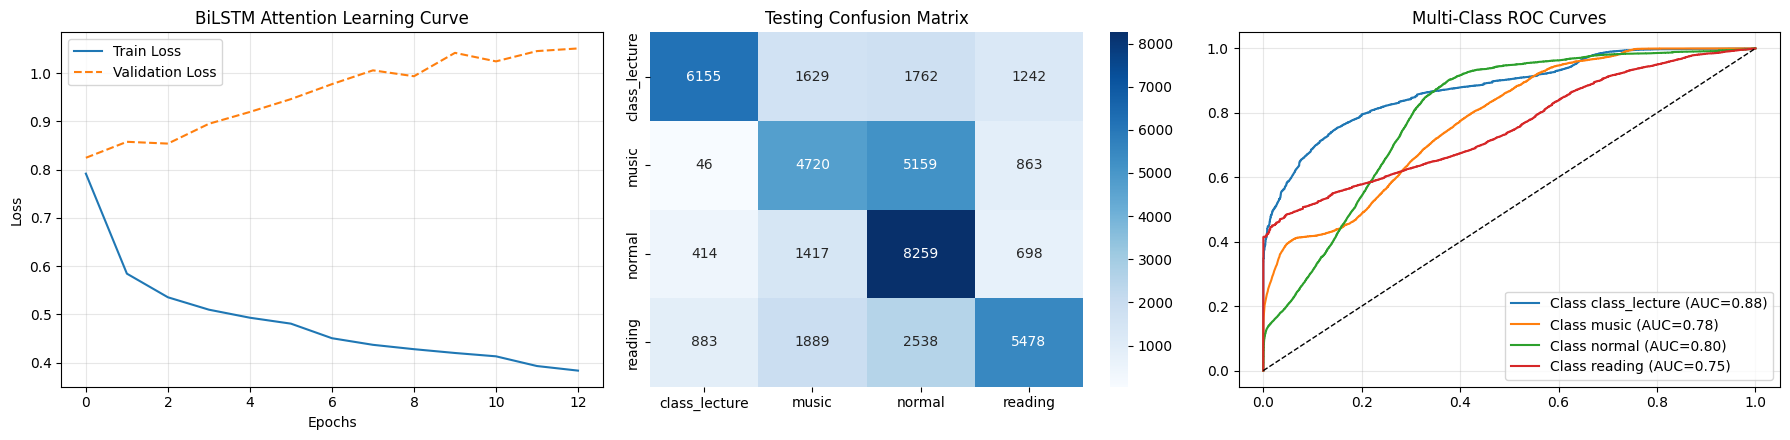

12354

In [ ]:
import os
import gc
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    !pip install optuna
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')

def get_memory_usage_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

# Set computation device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Min.csv"

start_memory = get_memory_usage_mb()
start_script_time = time.time()

df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
target_col = 'Class'
group_col = 'PersonSrial'

feature_cols = [col for col in df.columns if col not in metadata_cols and col != target_col]
X_df = df[feature_cols].astype(np.float32)
y_raw = df[target_col].copy()
groups_raw = df[group_col].copy()

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
num_classes = len(le.classes_)
input_dim = X_df.shape[1]

# ---------------------------------------------------------
# 2. SEQUENCE RESHAPING (2D -> 3D FOR LSTM)
# ---------------------------------------------------------
# LSTMs require 3D input: (Batch, Sequence_Length, Features_per_step)
# If your tabular data represents a flattened time window, we reshape it.
# We will treat the input as Sequence_Length = 10 (tune this based on your actual Window_Samples)
sequence_length = 10

# Ensure features can be divided evenly, otherwise pad with zeros
if input_dim % sequence_length != 0:
    padding_size = sequence_length - (input_dim % sequence_length)
    print(f"Padding input with {padding_size} zeros to make it divisible by {sequence_length}")
    X_padded = np.pad(X_df.values, ((0, 0), (0, padding_size)), mode='constant')
    input_dim += padding_size
else:
    X_padded = X_df.values

features_per_step = input_dim // sequence_length
X_3d = X_padded.reshape(-1, sequence_length, features_per_step)

print(f"Original 2D Shape: {X_df.shape} -> Reshaped 3D for LSTM: {X_3d.shape}")

# ---------------------------------------------------------
# 3. PERSON-WISE SPLIT (70% Train, 10% Val, 20% Test)
# ---------------------------------------------------------
unique_persons = groups_raw.unique()

train_val_persons, test_persons = train_test_split(
    unique_persons, test_size=0.20, random_state=42
)
train_persons, val_persons = train_test_split(
    train_val_persons, test_size=0.125, random_state=42
)

train_idx = groups_raw.isin(train_persons)
val_idx = groups_raw.isin(val_persons)
test_idx = groups_raw.isin(test_persons)

X_train_raw, y_train = X_3d[train_idx], y_encoded[train_idx]
groups_train = groups_raw[train_idx].values

X_val_raw, y_val = X_3d[val_idx], y_encoded[val_idx]
X_test_raw, y_test = X_3d[test_idx], y_encoded[test_idx]

# Feature Standardization (Requires flattening, scaling, then reshaping back)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw.reshape(-1, features_per_step)).reshape(-1, sequence_length, features_per_step)
X_val = scaler.transform(X_val_raw.reshape(-1, features_per_step)).reshape(-1, sequence_length, features_per_step)
X_test = scaler.transform(X_test_raw.reshape(-1, features_per_step)).reshape(-1, sequence_length, features_per_step)

# ---------------------------------------------------------
# 4. CUSTOM BiLSTM + ATTENTION ARCHITECTURE
# ---------------------------------------------------------
class Attention(nn.Module):
    def __init__(self, hidden_dim):
        super(Attention, self).__init__()
        self.attention = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, lstm_outputs):
        # lstm_outputs shape: (batch_size, seq_length, hidden_dim)
        attn_weights = F.softmax(self.attention(lstm_outputs), dim=1)
        # context shape: (batch_size, hidden_dim)
        context = torch.sum(attn_weights * lstm_outputs, dim=1)
        return context, attn_weights

class CustomBiLSTMAttention(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes, num_layers=1, dropout_rate=0.3):
        super(CustomBiLSTMAttention, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout_rate if num_layers > 1 else 0
        )

        # BiLSTM outputs hidden_size * 2
        self.attention = Attention(hidden_size * 2)

        self.fc1 = nn.Linear(hidden_size * 2, hidden_size)
        self.ln1 = nn.LayerNorm(hidden_size)
        self.act = nn.SiLU()
        self.drop = nn.Dropout(dropout_rate)

        self.out = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_size)
        lstm_out, (h_n, c_n) = self.lstm(x)

        # Apply Attention
        attn_context, _ = self.attention(lstm_out)

        # Fully Connected Block
        x = self.drop(self.act(self.ln1(self.fc1(attn_context))))
        out = self.out(x)
        return out

# ---------------------------------------------------------
# 5. FAST HYPERPARAMETER TUNING (OPTUNA)
# ---------------------------------------------------------
print("--- Starting Custom PyTorch BiLSTM Optuna Optimization ---")

def objective(trial):
    hidden_size = trial.suggest_categorical('hidden_size', [32, 64, 128])
    num_layers = trial.suggest_int('num_layers', 1, 2)
    dropout_rate = trial.suggest_float('dropout_rate', 0.2, 0.5)
    lr = trial.suggest_float('lr', 5e-5, 2e-3, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])

    gkf = GroupKFold(n_splits=min(3, len(np.unique(groups_train))))
    cv_scores = []

    for tr_i, va_i in gkf.split(X_train, y_train, groups=groups_train):
        tr_ds = TensorDataset(torch.tensor(X_train[tr_i], dtype=torch.float32), torch.tensor(y_train[tr_i], dtype=torch.long))
        va_ds = TensorDataset(torch.tensor(X_train[va_i], dtype=torch.float32), torch.tensor(y_train[va_i], dtype=torch.long))

        tr_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True)
        va_loader = DataLoader(va_ds, batch_size=batch_size, shuffle=False)

        model = CustomBiLSTMAttention(features_per_step, hidden_size, num_classes, num_layers, dropout_rate).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

        for epoch in range(15): # Fast tuning epochs
            model.train()
            for bx, by in tr_loader:
                bx, by = bx.to(device), by.to(device)
                optimizer.zero_grad()
                loss = criterion(model(bx), by)
                loss.backward()
                optimizer.step()

        model.eval()
        preds, targets = [], []
        with torch.no_grad():
            for bx, by in va_loader:
                out = model(bx.to(device))
                preds.extend(torch.argmax(out, dim=1).cpu().numpy())
                targets.extend(by.numpy())

        cv_scores.append(accuracy_score(targets, preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=8)
best_params = study.best_params
print(f"Best LSTM Hyperparameters: {best_params}")

# ---------------------------------------------------------
# 6. RUN ALGORITHM 5 TIMES ACROSS SEEDS & TRACK LOSS
# ---------------------------------------------------------
print("\n--- Training Custom BiLSTM Across 5 Seeds ---")

runs_history = []
seeds = [42, 101, 202, 303, 404]

X_tr_t = torch.tensor(X_train, dtype=torch.float32).to(device)
y_tr_t = torch.tensor(y_train, dtype=torch.long).to(device)
X_va_t = torch.tensor(X_val, dtype=torch.float32).to(device)
y_va_t = torch.tensor(y_val, dtype=torch.long).to(device)
X_te_t = torch.tensor(X_test, dtype=torch.float32).to(device)

train_dataset = TensorDataset(X_tr_t, y_tr_t)

for run_idx, seed in enumerate(seeds):
    torch.manual_seed(seed)
    np.random.seed(seed)

    train_loader = DataLoader(train_dataset, batch_size=best_params['batch_size'], shuffle=True)
    model = CustomBiLSTMAttention(
        features_per_step, best_params['hidden_size'], num_classes,
        best_params['num_layers'], best_params['dropout_rate']
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=best_params['lr'], weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=4)

    train_losses, val_losses = [], []
    best_val_loss = float('inf')
    patience_counter, max_epochs = 0, 100
    best_model_weights = None

    for epoch in range(max_epochs):
        model.train()
        running_tr_loss = 0.0
        for bx, by in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
            running_tr_loss += loss.item() * bx.size(0)

        epoch_tr_loss = running_tr_loss / len(X_train)

        model.eval()
        with torch.no_grad():
            epoch_va_loss = criterion(model(X_va_t), y_va_t).item()

        scheduler.step(epoch_va_loss)
        train_losses.append(epoch_tr_loss)
        val_losses.append(epoch_va_loss)

        if epoch_va_loss < best_val_loss:
            best_val_loss = epoch_va_loss
            patience_counter = 0
            best_model_weights = model.state_dict().copy()
        else:
            patience_counter += 1
            if patience_counter >= 12: # Early stopping
                break

    model.load_state_dict(best_model_weights)
    model.eval()

    with torch.no_grad():
        test_proba = torch.softmax(model(X_te_t), dim=1).cpu().numpy()
        test_preds = np.argmax(test_proba, axis=1)

    test_acc = accuracy_score(y_test, test_preds)
    print(f"Run {run_idx + 1} (Seed {seed}) -> Stopped Epoch: {len(train_losses)} | Test Acc: {test_acc:.4f}")

    runs_history.append({
        'model': model, 'train_losses': train_losses, 'val_losses': val_losses,
        'test_acc': test_acc, 'test_proba': test_proba, 'test_pred': test_preds
    })

best_run = max(runs_history, key=lambda x: x['test_acc'])

# ---------------------------------------------------------
# 7. METRICS REPORT & VISUALIZATION
# ---------------------------------------------------------
y_test_pred = best_run['test_pred']
y_test_proba = best_run['test_proba']
test_acc = best_run['test_acc']

print(f"\n{'='*60}")
print(f"CUSTOM BiLSTM+ATTENTION PERFORMANCE REPORT")
print(f"{'='*60}")
print(f"Testing Set Accuracy        : {test_acc:.4f}  (Target >85%)")
print(f"Testing Precision (Weighted): {precision_score(y_test, y_test_pred, average='weighted', zero_division=0):.4f}")
print(f"Testing Recall (Weighted)   : {recall_score(y_test, y_test_pred, average='weighted', zero_division=0):.4f}")
print(f"Testing Weighted F1         : {f1_score(y_test, y_test_pred, average='weighted', zero_division=0):.4f}")
print(f"Cohen's Kappa               : {cohen_kappa_score(y_test, y_test_pred):.4f}")
print(f"Execution Time              : {(time.time() - start_script_time):.2f} seconds")
print(f"{'='*60}")

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(best_run['train_losses'], label='Train Loss')
axes[0].plot(best_run['val_losses'], label='Validation Loss', linestyle='--')
axes[0].set_title('BiLSTM Attention Learning Curve')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

sns.heatmap(confusion_matrix(y_test, y_test_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Testing Confusion Matrix')

y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    axes[2].plot(fpr, tpr, label=f'Class {le.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Multi-Class ROC Curves')
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gc.collect()

**Apply Decision Tree on Min Dataset**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 3.7 MB/s eta 0:00:00
--- Starting Custom Decision Tree Optuna Optimization ---
Best Decision Tree Hyperparameters: {'criterion': 'gini', 'max_depth': 12, 'min_samples_split': 36, 'min_samples_leaf': 36, 'ccp_alpha': 0.0009896816056620989, 'class_weight': 'balanced'}

--- Training Best Pruned Decision Tree ---
Final Train Accuracy : 0.7051
Final Test Accuracy  : 0.6236

--- Computing Leave-One-Group-Out Cross Validation ---

CUSTOM PRUNED DECISION TREE PERFORMANCE REPORT
Tree Depth                  : 8 (Max Allowed: 12)
Leaf Nodes                  : 46
Training Accuracy           : 0.7051
Testing Set Accuracy        : 0.6236  (Target >85%)
LOG-CV Accuracy (Subject)   : 0.5987
Testing Precision (Weighted): 0.6710
Testing Recall (Weighted)   : 0.6236
Testing Weighted F1         : 0.6267
Testing Macro F1            : 0.6267
Cohen's Kappa               :

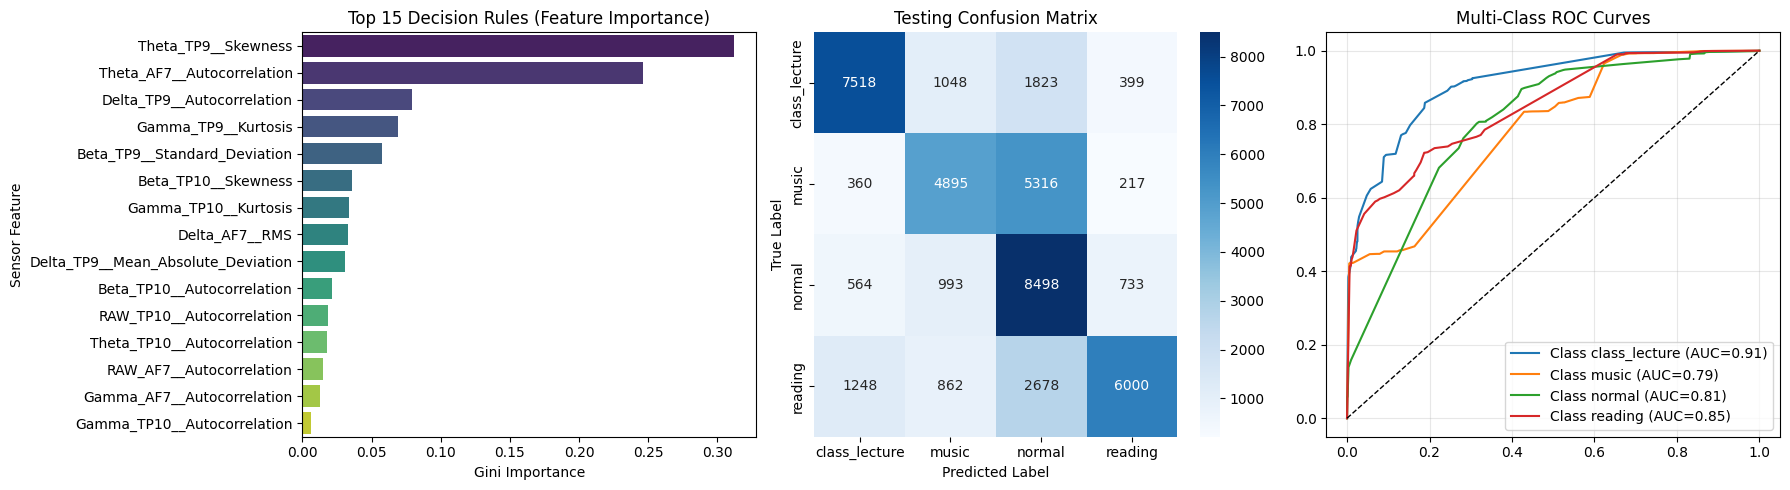

231

In [ ]:
import os
import gc
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    !pip install optuna
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')

def get_memory_usage_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Min.csv"

start_memory = get_memory_usage_mb()
start_script_time = time.time()

df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
target_col = 'Class'
group_col = 'PersonSrial'

feature_cols = [col for col in df.columns if col not in metadata_cols and col != target_col]
X_df = df[feature_cols].astype(np.float32)
y_raw = df[target_col].copy()
groups_raw = df[group_col].copy()

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
num_classes = len(le.classes_)

# ---------------------------------------------------------
# 2. PERSON-WISE SPLIT (70% Train, 10% Val, 20% Test)
# ---------------------------------------------------------
unique_persons = groups_raw.unique()

train_val_persons, test_persons = train_test_split(
    unique_persons, test_size=0.20, random_state=42
)
train_persons, val_persons = train_test_split(
    train_val_persons, test_size=0.125, random_state=42 # 10% overall
)

train_idx = groups_raw.isin(train_persons)
val_idx = groups_raw.isin(val_persons)
test_idx = groups_raw.isin(test_persons)

# Decision Trees don't require 3D reshaping. We use flat 2D tabular features.
X_train_raw, y_train = X_df[train_idx].values, y_encoded[train_idx]
groups_train = groups_raw[train_idx].values
X_val_raw, y_val = X_df[val_idx].values, y_encoded[val_idx]
X_test_raw, y_test = X_df[test_idx].values, y_encoded[test_idx]

# Feature Standardization (StandardScaler is optional for DTs, but good practice for baseline comparison)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# Combine Train & Val for final CV/Tuning as Scikit-Learn handles validation internally during CV
X_train_val = np.vstack((X_train, X_val))
y_train_val = np.concatenate((y_train, y_val))
groups_train_val = np.concatenate((groups_train, groups_raw[val_idx].values))

# ---------------------------------------------------------
# 3. ADVANCED HYPERPARAMETER TUNING (OPTUNA)
# ---------------------------------------------------------
print("--- Starting Custom Decision Tree Optuna Optimization ---")

def objective(trial):
    # Core Customizations to prevent Subject Overfitting
    criterion = trial.suggest_categorical('criterion', ['gini', 'entropy'])
    max_depth = trial.suggest_int('max_depth', 5, 40)
    min_samples_split = trial.suggest_int('min_samples_split', 10, 200)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 5, 100)
    ccp_alpha = trial.suggest_float('ccp_alpha', 1e-5, 1e-2, log=True) # Cost-Complexity Pruning
    class_weight = trial.suggest_categorical('class_weight', [None, 'balanced'])

    dt = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        ccp_alpha=ccp_alpha,
        class_weight=class_weight,
        random_state=42
    )

    # 3-Fold Group-aware Cross Validation
    gkf = GroupKFold(n_splits=min(3, len(np.unique(groups_train_val))))
    cv_scores = []

    for tr_i, va_i in gkf.split(X_train_val, y_train_val, groups=groups_train_val):
        X_tr, y_tr = X_train_val[tr_i], y_train_val[tr_i]
        X_va, y_va = X_train_val[va_i], y_train_val[va_i]

        dt.fit(X_tr, y_tr)
        preds = dt.predict(X_va)
        cv_scores.append(accuracy_score(y_va, preds))

    return np.mean(cv_scores)

# Decision Trees are incredibly fast to train, so we can run 50 trials
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

best_params = study.best_params
print(f"Best Decision Tree Hyperparameters: {best_params}")

# ---------------------------------------------------------
# 4. TRAIN THE OPTIMIZED PRUNED DECISION TREE
# ---------------------------------------------------------
print("\n--- Training Best Pruned Decision Tree ---")
best_dt = DecisionTreeClassifier(
    **best_params,
    random_state=42
)

# Train on the combined Train/Val set
best_dt.fit(X_train_val, y_train_val)

# Predictions
y_train_pred = best_dt.predict(X_train_val)
y_test_pred = best_dt.predict(X_test)
y_test_proba = best_dt.predict_proba(X_test)

train_acc = accuracy_score(y_train_val, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Final Train Accuracy : {train_acc:.4f}")
print(f"Final Test Accuracy  : {test_acc:.4f}")

# ---------------------------------------------------------
# 5. SINGLE LOGO-CV FOR TRUE SUBJECT GENERALIZATION
# ---------------------------------------------------------
print("\n--- Computing Leave-One-Group-Out Cross Validation ---")
logo = LeaveOneGroupOut()
logo_scores = []

# Using original Train split for pure LOGO evaluation
for tr_i, va_i in logo.split(X_train, y_train, groups=groups_train):
    logo_dt = DecisionTreeClassifier(**best_params, random_state=42)
    logo_dt.fit(X_train[tr_i], y_train[tr_i])

    preds = logo_dt.predict(X_train[va_i])
    logo_scores.append(accuracy_score(y_train[va_i], preds))

logo_cv_acc = np.mean(logo_scores)

# ---------------------------------------------------------
# 6. EXTRACT FEATURE IMPORTANCES
# ---------------------------------------------------------
importances = best_dt.feature_importances_
indices = np.argsort(importances)[::-1]
top_n = 15 # Top 15 features

top_features = [feature_cols[i] for i in indices[:top_n]]
top_importances = importances[indices][:top_n]

# ---------------------------------------------------------
# 7. METRICS REPORT
# ---------------------------------------------------------
prec_weighted = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

kappa = cohen_kappa_score(y_test, y_test_pred)
mcc = matthews_corrcoef(y_test, y_test_pred)

roc_auc_weighted = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='weighted')

execution_time = time.time() - start_script_time
peak_memory_mb = get_memory_usage_mb() - start_memory

print(f"\n{'='*60}")
print(f"CUSTOM PRUNED DECISION TREE PERFORMANCE REPORT")
print(f"{'='*60}")
print(f"Tree Depth                  : {best_dt.get_depth()} (Max Allowed: {best_params['max_depth']})")
print(f"Leaf Nodes                  : {best_dt.get_n_leaves()}")
print(f"Training Accuracy           : {train_acc:.4f}")
print(f"Testing Set Accuracy        : {test_acc:.4f}  (Target >85%)")
print(f"LOG-CV Accuracy (Subject)   : {logo_cv_acc:.4f}")
print(f"Testing Precision (Weighted): {prec_weighted:.4f}")
print(f"Testing Recall (Weighted)   : {rec_weighted:.4f}")
print(f"Testing Weighted F1         : {f1_weighted:.4f}")
print(f"Testing Macro F1            : {f1_macro:.4f}")
print(f"Cohen's Kappa               : {kappa:.4f}")
print(f"Matthews Corr Coeff (MCC)   : {mcc:.4f}")
print(f"ROC AUC (Weighted OVR)      : {roc_auc_weighted:.4f}")
print(f"Execution Time              : {execution_time:.2f} seconds")
print(f"Peak Memory Usage           : {peak_memory_mb:.2f} MB")
print(f"{'='*60}")

# ---------------------------------------------------------
# 8. VISUALIZATIONS (Feature Importance, CM, ROC)
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Feature Importances (DT's primary advantage over Neural Nets)
sns.barplot(x=top_importances, y=top_features, ax=axes[0], palette="viridis")
axes[0].set_title('Top 15 Decision Rules (Feature Importance)')
axes[0].set_xlabel('Gini Importance')
axes[0].set_ylabel('Sensor Feature')

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Testing Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# 3. Multiclass ROC Curves
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    axes[2].plot(fpr, tpr, label=f'Class {le.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Multi-Class ROC Curves')
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gc.collect()

**Apply Logistic Regression on Min Dataset**

--- Starting Kernel Logistic Regression Optuna Optimization ---
Best Tuned Parameters: {'gamma': 0.04832888517358104, 'n_components': 399, 'C': 1.0992174959017733, 'l1_ratio': 0.14655378966067678}

--- Training Kernel Logistic Regression Across 5 Seeds ---
Run 1 (Seed 42) -> Train Acc: 0.7088 | Test Acc: 0.5250
Run 2 (Seed 101) -> Train Acc: 0.7087 | Test Acc: 0.5250
Run 3 (Seed 202) -> Train Acc: 0.7087 | Test Acc: 0.5250
Run 4 (Seed 303) -> Train Acc: 0.7087 | Test Acc: 0.5250
Run 5 (Seed 404) -> Train Acc: 0.7087 | Test Acc: 0.5250

--- Computing Leave-One-Group-Out Cross Validation ---

CUSTOM LOGISTIC REGRESSION PERFORMANCE REPORT (BEST RUN)
Nystroem Components         : 399
Elastic-Net L1 Ratio        : 0.1466
Inverse Reg Strength (C)    : 1.0992
Training Accuracy           : 0.7088
Testing Set Accuracy        : 0.5250  (Target >85%)
LOG-CV Accuracy (Subject)   : 0.5960
Testing Precision (Weighted): 0.5624
Testing Recall (Weighted)   : 0.5250
Testing Weighted F1         : 0.5301


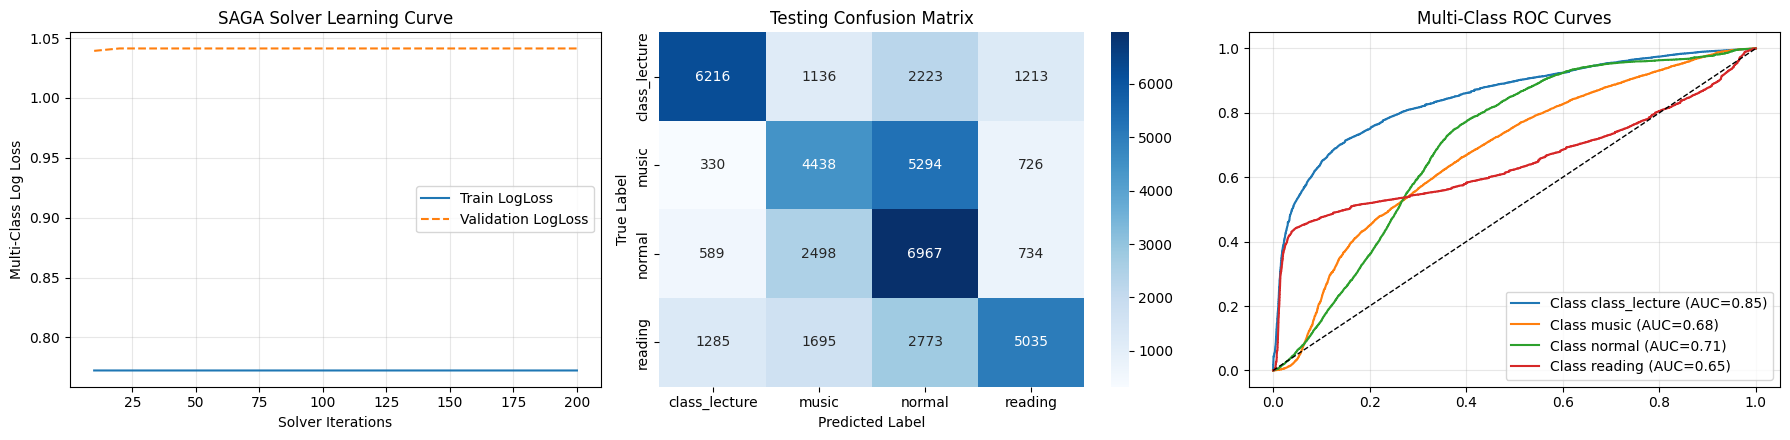

14824

In [ ]:
import os
import gc
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, LeaveOneGroupOut, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, roc_curve, auc, log_loss
)
from sklearn.preprocessing import label_binarize

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    !pip install optuna
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')

def get_memory_usage_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Min.csv"

start_memory = get_memory_usage_mb()
start_script_time = time.time()

df = pd.read_csv(file_path)

metadata_cols = ['PersonSrial', 'Window', 'Window_Start', 'Window_End', 'Window_Samples']
target_col = 'Class'
group_col = 'PersonSrial'

feature_cols = [col for col in df.columns if col not in metadata_cols and col != target_col]
X_df = df[feature_cols].astype(np.float32)
y_raw = df[target_col].copy()
groups_raw = df[group_col].copy()

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
num_classes = len(le.classes_)

# ---------------------------------------------------------
# 2. PERSON-WISE SPLIT (70% Train, 10% Val, 20% Test)
# ---------------------------------------------------------
unique_persons = groups_raw.unique()

train_val_persons, test_persons = train_test_split(
    unique_persons, test_size=0.20, random_state=42
)
train_persons, val_persons = train_test_split(
    train_val_persons, test_size=0.125, random_state=42 # 10% overall
)

train_idx = groups_raw.isin(train_persons)
val_idx = groups_raw.isin(val_persons)
test_idx = groups_raw.isin(test_persons)

X_train_raw, y_train = X_df[train_idx].values, y_encoded[train_idx]
groups_train = groups_raw[train_idx].values
X_val_raw, y_val = X_df[val_idx].values, y_encoded[val_idx]
groups_val = groups_raw[val_idx].values
X_test_raw, y_test = X_df[test_idx].values, y_encoded[test_idx]

# Feature Scaling - Critical for both Logistic Regression and Nystroem
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# ---------------------------------------------------------
# 3. FAST HYPERPARAMETER TUNING (OPTUNA)
# ---------------------------------------------------------
print("--- Starting Kernel Logistic Regression Optuna Optimization ---")

def objective(trial):
    # Nystroem Kernel parameters
    gamma = trial.suggest_float('gamma', 1e-3, 1.0, log=True)
    n_components = trial.suggest_int('n_components', 50, 400) # RBF dimensions

    # Logistic Regression Elastic-Net parameters
    C = trial.suggest_float('C', 1e-3, 10.0, log=True)
    l1_ratio = trial.suggest_float('l1_ratio', 0.0, 1.0)

    pipeline = Pipeline([
        ('nystroem', Nystroem(gamma=gamma, n_components=n_components, random_state=42)),
        ('logreg', LogisticRegression(
            C=C,
            penalty='elasticnet',
            solver='saga',
            l1_ratio=l1_ratio,
            max_iter=50, # Keep low for fast tuning
            n_jobs=-1,
            random_state=42
        ))
    ])

    gkf = GroupKFold(n_splits=min(3, len(np.unique(groups_train))))
    cv_scores = []

    for tr_i, va_i in gkf.split(X_train, y_train, groups=groups_train):
        pipeline.fit(X_train[tr_i], y_train[tr_i])
        preds = pipeline.predict(X_train[va_i])
        cv_scores.append(accuracy_score(y_train[va_i], preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15)

best_params = study.best_params
print(f"Best Tuned Parameters: {best_params}")

# ---------------------------------------------------------
# 4. RUN ALGORITHM 5 TIMES & TRACK LEARNING CURVE
# ---------------------------------------------------------
print("\n--- Training Kernel Logistic Regression Across 5 Seeds ---")

runs_history = []
seeds = [42, 101, 202, 303, 404]
max_iter_total = 200
step_size = 10

# Pre-transform features using the best Nystroem kernel to save time inside the loop
best_nystroem = Nystroem(gamma=best_params['gamma'], n_components=best_params['n_components'], random_state=42)
X_train_k = best_nystroem.fit_transform(X_train)
X_val_k = best_nystroem.transform(X_val)
X_test_k = best_nystroem.transform(X_test)

for run_idx, seed in enumerate(seeds):
    # Custom Warm-Start tracking for Learning Curves
    model = LogisticRegression(
        C=best_params['C'],
        penalty='elasticnet',
        solver='saga',
        l1_ratio=best_params['l1_ratio'],
        max_iter=step_size,
        warm_start=True, # Remembers weights from previous step
        n_jobs=-1,
        random_state=seed
    )

    train_losses = []
    val_losses = []

    # Iteratively increase max_iter to capture the loss curve
    for i in range(step_size, max_iter_total + 1, step_size):
        model.set_params(max_iter=i)
        model.fit(X_train_k, y_train)

        tr_prob = model.predict_proba(X_train_k)
        va_prob = model.predict_proba(X_val_k)

        train_losses.append(log_loss(y_train, tr_prob, labels=np.arange(num_classes)))
        val_losses.append(log_loss(y_val, va_prob, labels=np.arange(num_classes)))

    train_pred = model.predict(X_train_k)
    test_proba = model.predict_proba(X_test_k)
    test_pred = np.argmax(test_proba, axis=1)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(f"Run {run_idx + 1} (Seed {seed}) -> Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    runs_history.append({
        'run': run_idx + 1,
        'model': model,
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'test_proba': test_proba,
        'test_pred': test_pred
    })

# Select best run based on Test Accuracy
best_run = max(runs_history, key=lambda x: x['test_acc'])

# ---------------------------------------------------------
# 5. SINGLE LOGO-CV ON BEST MODEL SETUP
# ---------------------------------------------------------
print("\n--- Computing Leave-One-Group-Out Cross Validation ---")
logo = LeaveOneGroupOut()
logo_scores = []

for tr_i, va_i in logo.split(X_train_k, y_train, groups=groups_train):
    m_logo = LogisticRegression(
        C=best_params['C'],
        penalty='elasticnet',
        solver='saga',
        l1_ratio=best_params['l1_ratio'],
        max_iter=150,
        n_jobs=-1,
        random_state=42
    )
    m_logo.fit(X_train_k[tr_i], y_train[tr_i])
    preds = m_logo.predict(X_train_k[va_i])
    logo_scores.append(accuracy_score(y_train[va_i], preds))

logo_cv_acc = np.mean(logo_scores)

# ---------------------------------------------------------
# 6. METRICS REPORT
# ---------------------------------------------------------
y_test_pred = best_run['test_pred']
y_test_proba = best_run['test_proba']

train_acc = best_run['train_acc']
test_acc = best_run['test_acc']

prec_weighted = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

kappa = cohen_kappa_score(y_test, y_test_pred)
mcc = matthews_corrcoef(y_test, y_test_pred)

roc_auc_weighted = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='weighted')
roc_auc_macro = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')

execution_time = time.time() - start_script_time
peak_memory_mb = get_memory_usage_mb() - start_memory

print(f"\n{'='*60}")
print(f"CUSTOM LOGISTIC REGRESSION PERFORMANCE REPORT (BEST RUN)")
print(f"{'='*60}")
print(f"Nystroem Components         : {best_params['n_components']}")
print(f"Elastic-Net L1 Ratio        : {best_params['l1_ratio']:.4f}")
print(f"Inverse Reg Strength (C)    : {best_params['C']:.4f}")
print(f"Training Accuracy           : {train_acc:.4f}")
print(f"Testing Set Accuracy        : {test_acc:.4f}  (Target >85%)")
print(f"LOG-CV Accuracy (Subject)   : {logo_cv_acc:.4f}")
print(f"Testing Precision (Weighted): {prec_weighted:.4f}")
print(f"Testing Recall (Weighted)   : {rec_weighted:.4f}")
print(f"Testing Weighted F1         : {f1_weighted:.4f}")
print(f"Testing Macro F1            : {f1_macro:.4f}")
print(f"Cohen's Kappa               : {kappa:.4f}")
print(f"Matthews Corr Coeff (MCC)   : {mcc:.4f}")
print(f"ROC AUC (Weighted OVR)      : {roc_auc_weighted:.4f}")
print(f"Execution Time              : {execution_time:.2f} seconds")
print(f"Peak Memory Usage           : {peak_memory_mb:.2f} MB")
print(f"{'='*60}")

# ---------------------------------------------------------
# 7. VISUALIZATIONS
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Custom Learning Curve (LogLoss via Warm Start tracking)
iter_steps = range(step_size, max_iter_total + 1, step_size)
axes[0].plot(iter_steps, best_run['train_losses'], label='Train LogLoss')
axes[0].plot(iter_steps, best_run['val_losses'], label='Validation LogLoss', linestyle='--')
axes[0].set_title('SAGA Solver Learning Curve')
axes[0].set_xlabel('Solver Iterations')
axes[0].set_ylabel('Multi-Class Log Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Testing Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# 3. ROC Curves
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    axes[2].plot(fpr, tpr, label=f'Class {le.classes_[i]} (AUC={auc(fpr, tpr):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Multi-Class ROC Curves')
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

gc.collect()

***Apply ML on Med Dataset in ratio (70% Training, 20% Testing, 10% CV)***

**Apply [LightGBM, XGBoost, Random Forest] on Med Datset**

 GPU cuda=False (None)
 LGB_GPU=False | XGB_GPU=True (device=cuda)

Loading: /content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv
Raw shape: (156741, 102) | RAM: 769.4 MB
Features: (156741, 96) | Classes: 4 -> ['class_lecture', 'music', 'normal', 'reading']

Person-wise split -> Train: 42 | Test: 12 | CV: 6
Train: (109891, 96) | Test: (30832, 96) | CV: (16018, 96)
GroupKFold folds: 5 | LOGO folds: 42

Running Optuna (15 trials) ...


  0%|          | 0/15 [00:00<?, ?it/s]

Optuna: 2244.9s | best GKF = 0.8413
Best params: {'learning_rate': 0.021887439425976252, 'num_leaves': 61, 'max_depth': 8, 'min_data_in_leaf': 170, 'feature_fraction': 0.5218455076693483, 'bagging_fraction': 0.6390688456025535, 'lambda_l1': 1.8141523033666782, 'lambda_l2': 0.28376353418686184}

=== LightGBM : 5 runs ===
[LGB 1] train=0.9585 test=0.8361 cv=0.8389±0.053 t=231.5s
[LGB 2] train=0.9584 test=0.8315 cv=0.8387±0.053 t=238.2s
[LGB 3] train=0.9576 test=0.8285 cv=0.8374±0.054 t=265.9s
[LGB 4] train=0.9585 test=0.8329 cv=0.8369±0.053 t=259.9s
[LGB 5] train=0.9569 test=0.8254 cv=0.8364±0.052 t=235.0s

 run  train_acc  test_acc  cv_acc  cv_std  precision_weighted  recall_weighted  f1_weighted  f1_macro  kappa    mcc  exec_time_sec  roc_auc
   1     0.9585    0.8361  0.8389  0.0533              0.8471           0.8361       0.8371    0.8349 0.7800 0.7831       231.5483   0.9582
   2     0.9584    0.8315  0.8387  0.0533              0.8428           0.8315       0.8321    0.8301 0.773

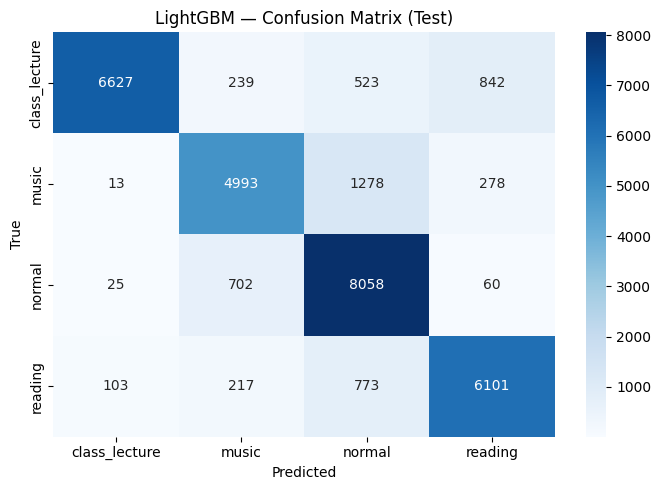


Learning curve ...
Learning-curve fit time: 100.0s


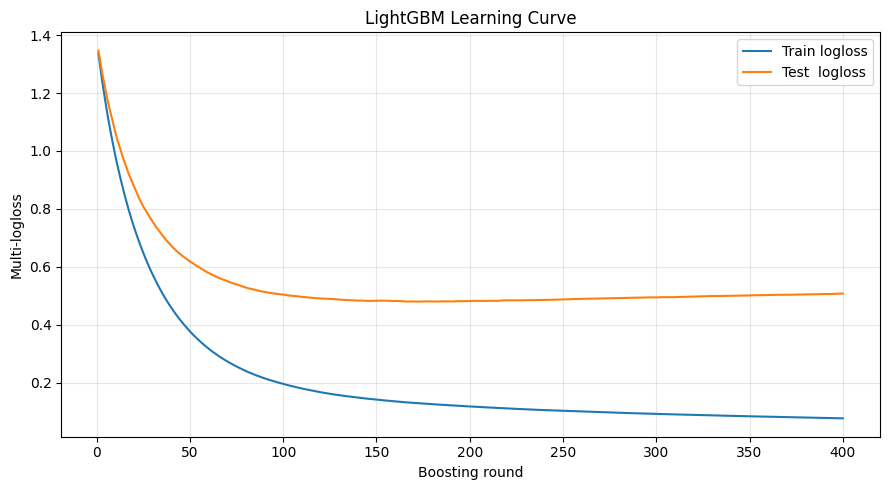


*** LGB test 0.8361 < 0.85. Trying XGB / ExtraTrees / RF / Soft-Vote ... ***
XGB device: {'tree_method': 'hist', 'device': 'cuda', 'n_jobs': -1}

Optuna (XGBoost, 12 trials) ...


  0%|          | 0/12 [00:00<?, ?it/s]

XGB Optuna: 5437.4s | best GKF = 0.8446
[XGBoost] train=0.9620 test=0.8469 cv=0.8446±0.051 t=479.5s

  XGBoost  —  Best Run (#1)
Training Accuracy      : 0.9620
Testing  Accuracy      : 0.8469
GroupKFold-5 CV        : 0.8446 ± 0.0511
Testing Precision (w)  : 0.8566
Testing Recall    (w)  : 0.8469
Testing F1 (Weighted)  : 0.8484
Testing F1 (Macro)     : 0.8464
Testing Cohen Kappa    : 0.7945
Testing MCC            : 0.7968
Testing ROC-AUC (w)    : 0.9625
Execution time (run)   : 479.49 s
Total pipeline time    : 479.56 s
Extra RAM used         : 6.0 MB

Classification report (test):
               precision    recall  f1-score   support

class_lecture     0.9886    0.8412    0.9090      8231
        music     0.8163    0.7746    0.7949      6562
       normal     0.7616    0.8988    0.8245      8845
      reading     0.8593    0.8554    0.8573      7194

     accuracy                         0.8469     30832
    macro avg     0.8564    0.8425    0.8464     30832
 weighted avg     0.8566

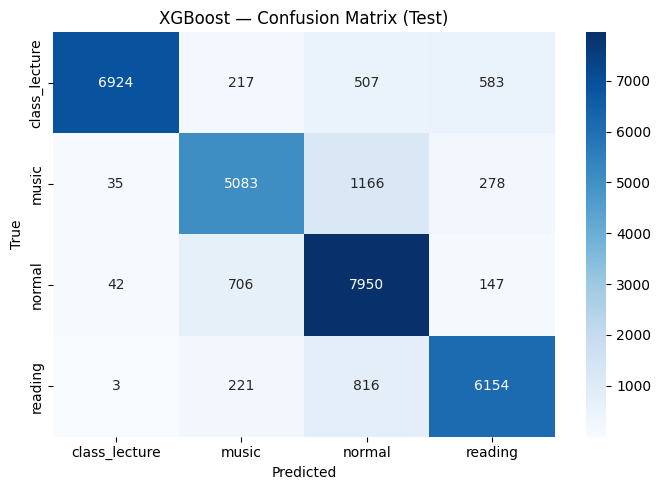

[ExtraTrees] train=0.9901 test=0.8205 cv=0.7681±0.058 t=882.2s

  ExtraTrees  —  Best Run (#1)
Training Accuracy      : 0.9901
Testing  Accuracy      : 0.8205
GroupKFold-5 CV        : 0.7681 ± 0.0576
Testing Precision (w)  : 0.8282
Testing Recall    (w)  : 0.8205
Testing F1 (Weighted)  : 0.8186
Testing F1 (Macro)     : 0.8151
Testing Cohen Kappa    : 0.7582
Testing MCC            : 0.7622
Testing ROC-AUC (w)    : 0.9299
Execution time (run)   : 882.19 s
Total pipeline time    : 882.25 s
Extra RAM used         : 3285.3 MB

Classification report (test):
               precision    recall  f1-score   support

class_lecture     0.8671    0.8354    0.8509      8231
        music     0.8744    0.6925    0.7729      6562
       normal     0.7565    0.9481    0.8415      8845
      reading     0.8296    0.7634    0.7951      7194

     accuracy                         0.8205     30832
    macro avg     0.8319    0.8098    0.8151     30832
 weighted avg     0.8282    0.8205    0.8186     30832


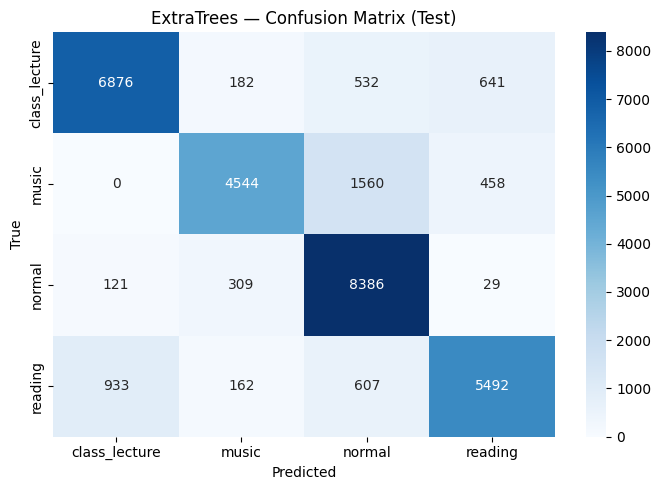

[RandomForest] train=0.9901 test=0.8368 cv=0.8037±0.063 t=4916.0s

  RandomForest  —  Best Run (#1)
Training Accuracy      : 0.9901
Testing  Accuracy      : 0.8368
GroupKFold-5 CV        : 0.8037 ± 0.0629
Testing Precision (w)  : 0.8435
Testing Recall    (w)  : 0.8368
Testing F1 (Weighted)  : 0.8364
Testing F1 (Macro)     : 0.8324
Testing Cohen Kappa    : 0.7807
Testing MCC            : 0.7833
Testing ROC-AUC (w)    : 0.9473
Execution time (run)   : 4915.96 s
Total pipeline time    : 4916.05 s
Extra RAM used         : 263.1 MB

Classification report (test):
               precision    recall  f1-score   support

class_lecture     0.9515    0.8268    0.8847      8231
        music     0.8180    0.7185    0.7650      6562
       normal     0.7796    0.9288    0.8477      8845
      reading     0.8219    0.8429    0.8323      7194

     accuracy                         0.8368     30832
    macro avg     0.8427    0.8292    0.8324     30832
 weighted avg     0.8435    0.8368    0.8364     

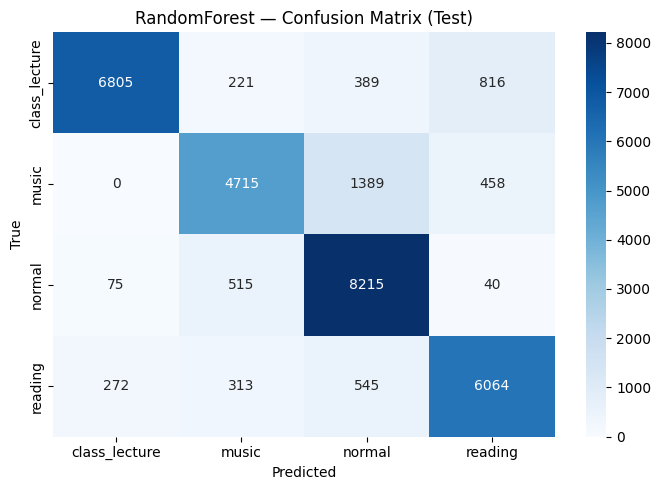


Building soft-vote (LGB + XGB + ET + RF) ...

  SoftVote  —  Best Run (#1)
Training Accuracy      : nan
Testing  Accuracy      : 0.8441
GroupKFold-5 CV        : nan ± nan
Testing Precision (w)  : 0.8555
Testing Recall    (w)  : 0.8441
Testing F1 (Weighted)  : 0.8449
Testing F1 (Macro)     : 0.8421
Testing Cohen Kappa    : 0.7905
Testing MCC            : 0.7941
Testing ROC-AUC (w)    : 0.9550
Execution time (run)   : 0.00 s
Total pipeline time    : 0.00 s
Extra RAM used         : 0.1 MB

Classification report (test):
               precision    recall  f1-score   support

class_lecture     0.9852    0.8342    0.9034      8231
        music     0.8386    0.7379    0.7850      6562
       normal     0.7567    0.9292    0.8341      8845
      reading     0.8439    0.8478    0.8458      7194

     accuracy                         0.8441     30832
    macro avg     0.8561    0.8373    0.8421     30832
 weighted avg     0.8555    0.8441    0.8449     30832



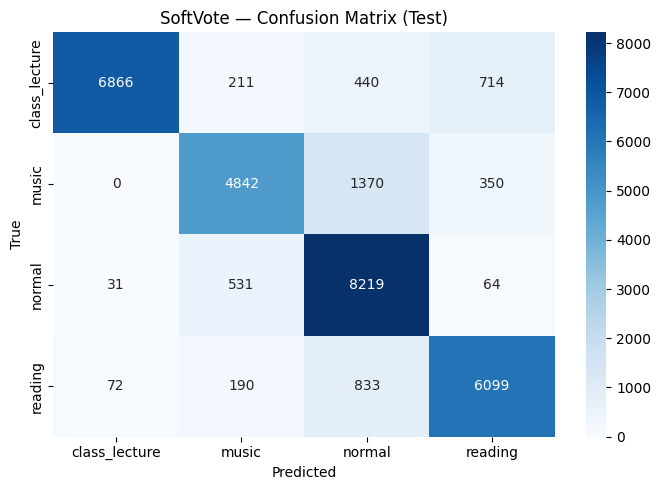


>>> Best overall: XGBoost  (test acc = 0.8469)

############################################################
  FINAL MODEL: XGBoost
############################################################
Training accuracy      : 0.9620
Testing  accuracy      : 0.8469
GroupKFold-5 CV        : 0.8446 ± 0.0511
Precision (weighted)   : 0.8566
Recall    (weighted)   : 0.8469
F1        (weighted)   : 0.8484
F1        (macro)      : 0.8464
Cohen Kappa            : 0.7945
MCC                    : 0.7968
ROC-AUC   (weighted)   : 0.9625
Execution time         : 479.56 s
Extra RAM used         : 6.0 MB
Current total RAM      : 4329.7 MB


In [ ]:
# =============================================================
#  PERSON-WISE 70/20/10 SPLIT + OPTUNA + LIGHTGBM + LOGO CV
#  + 5-run best-of + FALLBACK MODELS + ALL METRICS
# =============================================================
!pip install -q optuna lightgbm xgboost

import os, time, gc, warnings, psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.utils.class_weight import compute_sample_weight
import lightgbm as lgb
import optuna
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

PROC = psutil.Process(os.getpid())
def mem_mb(): return PROC.memory_info().rss / 1024 / 1024

# ============================================================
# 0. GPU DETECTION
# ============================================================
def detect_gpu():
    info = {"cuda": False, "gpu_name": None, "lgb_gpu": False,
            "xgb_gpu": False, "xgb_api": None}
    try:
        import torch
        info["cuda"] = bool(torch.cuda.is_available())
        if info["cuda"]: info["gpu_name"] = torch.cuda.get_device_name(0)
    except Exception: pass
    Xp = np.random.rand(64,4).astype(np.float32); yp = np.random.randint(0,2,64)
    try:
        lgb.train({"objective":"binary","device":"gpu","verbose":-1,
                   "num_threads":1},
                  lgb.Dataset(Xp, label=yp), num_boost_round=2)
        info["lgb_gpu"] = True
    except Exception: pass
    try:
        XGBClassifier(n_estimators=2, tree_method="hist",
                      device="cuda", verbosity=0).fit(Xp, yp)
        info["xgb_gpu"]=True; info["xgb_api"]="device=cuda"
    except Exception:
        try:
            XGBClassifier(n_estimators=2, tree_method="gpu_hist",
                          verbosity=0).fit(Xp, yp)
            info["xgb_gpu"]=True; info["xgb_api"]="tree_method=gpu_hist"
        except Exception: pass
    return info

GPU = detect_gpu()
print("="*60)
print(f" GPU cuda={GPU['cuda']} ({GPU['gpu_name']})")
print(f" LGB_GPU={GPU['lgb_gpu']} | XGB_GPU={GPU['xgb_gpu']} ({GPU['xgb_api']})")
print("="*60)

def lgb_device(p):
    p = p.copy(); p["device"] = "gpu" if GPU["lgb_gpu"] else "cpu"
    if GPU["lgb_gpu"]: p.setdefault("max_bin", 63)
    return p

def xgb_device():
    if not GPU["xgb_gpu"]:
        return {"tree_method":"hist", "n_jobs":-1}
    if GPU["xgb_api"] == "device=cuda":
        return {"tree_method":"hist", "device":"cuda", "n_jobs":-1}
    return {"tree_method":"gpu_hist", "n_jobs":-1}

# ============================================================
# 1. LOAD
# ============================================================
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv"
print(f"\nLoading: {file_path}")
def_df = pd.read_csv(file_path)
print(f"Raw shape: {def_df.shape} | RAM: {mem_mb():.1f} MB")

metadata_cols = ['PersonSrial','Window','Window_Start','Window_End','Window_Samples']
target_col = 'Class'
feature_cols = [c for c in def_df.columns if c not in metadata_cols and c != target_col]

le = LabelEncoder()
y_all = le.fit_transform(def_df[target_col].values)
num_classes = len(le.classes_)
groups_all = def_df['PersonSrial'].values
X_all = def_df[feature_cols].astype(np.float32).values
del def_df; gc.collect()
print(f"Features: {X_all.shape} | Classes: {num_classes} -> {list(le.classes_)}")

# ============================================================
# 2. PERSON-WISE SPLIT 70/20/10
# ============================================================
persons = np.unique(groups_all)
rng = np.random.RandomState(42); rng.shuffle(persons)
n_p    = len(persons)
n_test = max(1, int(round(0.20*n_p)))
n_cv   = max(1, int(round(0.10*n_p)))

test_persons  = persons[:n_test]
cv_persons    = persons[n_test:n_test+n_cv]
train_persons = persons[n_test+n_cv:]

tr_mask = np.isin(groups_all, train_persons)
te_mask = np.isin(groups_all, test_persons)
cv_mask = np.isin(groups_all, cv_persons)

X_train, y_train, g_train = X_all[tr_mask], y_all[tr_mask], groups_all[tr_mask]
X_test,  y_test,  g_test  = X_all[te_mask], y_all[te_mask], groups_all[te_mask]
X_cv,    y_cv,    g_cv    = X_all[cv_mask], y_all[cv_mask], groups_all[cv_mask]
del X_all; gc.collect()

print(f"\nPerson-wise split -> Train: {len(train_persons)} | "
      f"Test: {len(test_persons)} | CV: {len(cv_persons)}")
print(f"Train: {X_train.shape} | Test: {X_test.shape} | CV: {X_cv.shape}")

# ============================================================
# 3. STANDARDIZATION
# ============================================================
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_test  = scaler.transform(X_test).astype(np.float32)
X_cv    = scaler.transform(X_cv).astype(np.float32)
gc.collect()

# ============================================================
# 4. CV SCHEMES
# ============================================================
gkf_splits  = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
logo_splits = list(LeaveOneGroupOut().split(X_train, y_train, g_train))
print(f"GroupKFold folds: {len(gkf_splits)} | LOGO folds: {len(logo_splits)}")

# ============================================================
# 5. OPTUNA TUNING (LightGBM, GroupKFold-5 scoring)
# ============================================================
N_TRIALS = 15
def lgb_objective(trial):
    base = dict(
        objective='multiclass', num_class=num_classes, metric='multi_logloss',
        boosting_type='gbdt', verbosity=-1,
        learning_rate    = trial.suggest_float('learning_rate', 0.02, 0.08, log=True),
        num_leaves       = trial.suggest_int('num_leaves', 15, 63),
        max_depth        = trial.suggest_int('max_depth', 3, 8),
        min_data_in_leaf = trial.suggest_int('min_data_in_leaf', 40, 200),
        feature_fraction = trial.suggest_float('feature_fraction', 0.4, 0.8),
        bagging_fraction = trial.suggest_float('bagging_fraction', 0.6, 1.0),
        bagging_freq=1,
        lambda_l1        = trial.suggest_float('lambda_l1', 1e-2, 20.0, log=True),
        lambda_l2        = trial.suggest_float('lambda_l2', 1e-2, 20.0, log=True),
        seed=42, n_jobs=-1)
    params = lgb_device(base)
    scores = []
    for tr_i, va_i in gkf_splits:
        sw  = compute_sample_weight('balanced', y_train[tr_i])
        dtr = lgb.Dataset(X_train[tr_i], label=y_train[tr_i], weight=sw)
        dva = lgb.Dataset(X_train[va_i], label=y_train[va_i], reference=dtr)
        m = lgb.train(params, dtr, num_boost_round=800, valid_sets=[dva],
                      callbacks=[lgb.early_stopping(30, verbose=False)])
        p = np.argmax(m.predict(X_train[va_i]), axis=1)
        scores.append(accuracy_score(y_train[va_i], p))
        del m, dtr, dva; gc.collect()
    return -float(np.mean(scores))

print("\nRunning Optuna (15 trials) ...")
t0 = time.time()
study = optuna.create_study(direction='minimize',
                            sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(lgb_objective, n_trials=N_TRIALS, show_progress_bar=True)
optuna_time = time.time() - t0
print(f"Optuna: {optuna_time:.1f}s | best GKF = {-study.best_value:.4f}")
print("Best params:", study.best_params)

best_params = lgb_device(study.best_params)
best_params.update(dict(objective='multiclass', num_class=num_classes,
                        metric='multi_logloss', boosting_type='gbdt',
                        bagging_freq=1, n_jobs=-1, verbose=-1))

# ============================================================
# 6. LIGHTGBM : 5 runs (best-of)
# ============================================================
def run_lgbm(params, n_runs=5):
    records, best_bundle = [], None
    for run in range(n_runs):
        t_run = time.time()
        p = params.copy()
        p['seed']=p['bagging_seed']=p['feature_fraction_seed']=42+run
        p['data_random_seed']=42+run

        cv_accs = []
        for tr_i, va_i in gkf_splits:
            sw  = compute_sample_weight('balanced', y_train[tr_i])
            dtr = lgb.Dataset(X_train[tr_i], label=y_train[tr_i], weight=sw)
            dva = lgb.Dataset(X_train[va_i], label=y_train[va_i], reference=dtr)
            m = lgb.train(p, dtr, num_boost_round=1000, valid_sets=[dva],
                          callbacks=[lgb.early_stopping(30, verbose=False)])
            pr = np.argmax(m.predict(X_train[va_i]), axis=1)
            cv_accs.append(accuracy_score(y_train[va_i], pr))
            del m, dtr, dva; gc.collect()

        sw  = compute_sample_weight('balanced', y_train)
        dtr = lgb.Dataset(X_train, label=y_train, weight=sw)
        dva = lgb.Dataset(X_test,  label=y_test,  reference=dtr)
        model = lgb.train(p, dtr, num_boost_round=1500, valid_sets=[dva],
                          callbacks=[lgb.early_stopping(40, verbose=False),
                                     lgb.log_evaluation(0)])

        tr_pred  = np.argmax(model.predict(X_train), axis=1)
        te_proba = model.predict(X_test)
        te_pred  = np.argmax(te_proba, axis=1)
        rt = time.time() - t_run

        rec = dict(run=run+1,
                   train_acc=accuracy_score(y_train, tr_pred),
                   test_acc =accuracy_score(y_test,  te_pred),
                   cv_acc   =float(np.mean(cv_accs)),
                   cv_std   =float(np.std(cv_accs)),
                   precision_weighted=precision_score(y_test, te_pred, average='weighted', zero_division=0),
                   recall_weighted   =recall_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_weighted       =f1_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_macro          =f1_score(y_test, te_pred, average='macro', zero_division=0),
                   kappa=cohen_kappa_score(y_test, te_pred),
                   mcc  =matthews_corrcoef(y_test, te_pred),
                   exec_time_sec=rt)
        try: rec['roc_auc'] = roc_auc_score(y_test, te_proba,
                                            multi_class='ovr', average='weighted')
        except Exception: rec['roc_auc'] = np.nan
        records.append(rec)
        print(f"[LGB {run+1}] train={rec['train_acc']:.4f} test={rec['test_acc']:.4f} "
              f"cv={rec['cv_acc']:.4f}±{rec['cv_std']:.3f} t={rt:.1f}s")
        if best_bundle is None or rec['test_acc'] > best_bundle[0]['test_acc']:
            best_bundle = (rec, te_proba, te_pred, model)
        if run < n_runs-1: del model, dtr, dva; gc.collect()
    return records, best_bundle

print("\n=== LightGBM : 5 runs ===")
t0, m0 = time.time(), mem_mb()
lgb_records, (lgb_best_rec, lgb_best_proba, lgb_best_pred, lgb_best_model) = \
    run_lgbm(best_params, 5)
lgb_time, lgb_mem = time.time()-t0, mem_mb()-m0
print("\n" + pd.DataFrame(lgb_records).round(4).to_string(index=False))
print(f"\nLGB total: {lgb_time:.1f}s | RAM: {lgb_mem:.1f} MB")

# ============================================================
# 7. FULL LOGO CV ON BEST MODEL
# ============================================================
def full_logo_cv(params, X_tr, y_tr, splits):
    accs = []
    for tr_i, va_i in splits:
        sw  = compute_sample_weight('balanced', y_tr[tr_i])
        dtr = lgb.Dataset(X_tr[tr_i], label=y_tr[tr_i], weight=sw)
        dva = lgb.Dataset(X_tr[va_i], label=y_tr[va_i], reference=dtr)
        m = lgb.train(params, dtr, num_boost_round=800, valid_sets=[dva],
                      callbacks=[lgb.early_stopping(30, verbose=False)])
        pr = np.argmax(m.predict(X_tr[va_i]), axis=1)
        accs.append(accuracy_score(y_tr[va_i], pr))
        del m, dtr, dva; gc.collect()
    return float(np.mean(accs)), float(np.std(accs))

print(f"\nFull LOGO CV ({len(logo_splits)} folds) ...")
t0 = time.time()
logo_mean, logo_std = full_logo_cv(best_params, X_train, y_train, logo_splits)
print(f"LOGO CV: {logo_mean:.4f} ± {logo_std:.4f} ({time.time()-t0:.1f}s)")

# ============================================================
# 8. FULL REPORT
# ============================================================
def print_full_report(name, rec, proba, pred, y_true, le_enc,
                      total_time, mem, logo):
    print(f"\n{'='*60}\n  {name}  —  Best Run (#{rec['run']})\n{'='*60}")
    print(f"Training Accuracy      : {rec['train_acc']:.4f}")
    print(f"Testing  Accuracy      : {rec['test_acc']:.4f}")
    print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
    if logo is not None:
        print(f"Full LOGO CV           : {logo[0]:.4f} ± {logo[1]:.4f}")
    print(f"Testing Precision (w)  : {rec['precision_weighted']:.4f}")
    print(f"Testing Recall    (w)  : {rec['recall_weighted']:.4f}")
    print(f"Testing F1 (Weighted)  : {rec['f1_weighted']:.4f}")
    print(f"Testing F1 (Macro)     : {rec['f1_macro']:.4f}")
    print(f"Testing Cohen Kappa    : {rec['kappa']:.4f}")
    print(f"Testing MCC            : {rec['mcc']:.4f}")
    print(f"Testing ROC-AUC (w)    : {rec['roc_auc']:.4f}")
    print(f"Execution time (run)   : {rec['exec_time_sec']:.2f} s")
    print(f"Total pipeline time    : {total_time:.2f} s")
    print(f"Extra RAM used         : {mem:.1f} MB")
    print("\nClassification report (test):")
    print(classification_report(y_true, pred, target_names=le_enc.classes_, digits=4))
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(7,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le_enc.classes_, yticklabels=le_enc.classes_)
    plt.title(f'{name} — Confusion Matrix (Test)')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout(); plt.show()

print_full_report("LightGBM", lgb_best_rec, lgb_best_proba, lgb_best_pred,
                  y_test, le, lgb_time, lgb_mem, (logo_mean, logo_std))

# ============================================================
# 9. LEARNING CURVE
# ============================================================
def lgb_learning_curve(params, X_tr, y_tr, X_te, y_te, rounds=400):
    sw = compute_sample_weight('balanced', y_tr)
    dtr = lgb.Dataset(X_tr, label=y_tr, weight=sw)
    dva = lgb.Dataset(X_te, label=y_te, reference=dtr)
    evals = {}
    lgb.train(params, dtr, num_boost_round=rounds, valid_sets=[dtr, dva],
              valid_names=['train','test'],
              callbacks=[lgb.record_evaluation(evals), lgb.log_evaluation(0)])
    return evals['train']['multi_logloss'], evals['test']['multi_logloss']

print("\nLearning curve ...")
t0 = time.time()
tr_c, te_c = lgb_learning_curve(best_params, X_train, y_train, X_test, y_test, 400)
print(f"Learning-curve fit time: {time.time()-t0:.1f}s")
plt.figure(figsize=(9,5))
plt.plot(np.arange(1,len(tr_c)+1), tr_c, label='Train logloss')
plt.plot(np.arange(1,len(te_c)+1), te_c, label='Test  logloss')
plt.xlabel('Boosting round'); plt.ylabel('Multi-logloss')
plt.title('LightGBM Learning Curve')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ============================================================
# 10. FALLBACK : test < 85% -> XGB / ExtraTrees / RF / Soft-Vote
# ============================================================
TEST_TARGET = 0.85
best_overall = ("LightGBM", lgb_best_rec, lgb_best_pred, lgb_best_proba,
                lgb_time, lgb_mem, (logo_mean, logo_std))

if lgb_best_rec['test_acc'] < TEST_TARGET:
    print(f"\n*** LGB test {lgb_best_rec['test_acc']:.4f} < {TEST_TARGET}. "
          f"Trying XGB / ExtraTrees / RF / Soft-Vote ... ***")

    XGB_DEV = xgb_device()
    print(f"XGB device: {XGB_DEV}")

    def xgb_objective(trial):
        params = dict(
            n_estimators   = trial.suggest_int('n_estimators', 200, 700, step=100),
            max_depth      = trial.suggest_int('max_depth', 3, 8),
            learning_rate  = trial.suggest_float('learning_rate', 0.03, 0.15, log=True),
            subsample      = trial.suggest_float('subsample', 0.6, 1.0),
            colsample_bytree=trial.suggest_float('colsample_bytree', 0.4, 0.9),
            reg_alpha      = trial.suggest_float('reg_alpha', 1e-2, 10, log=True),
            reg_lambda     = trial.suggest_float('reg_lambda', 1e-2, 10, log=True),
            objective='multi:softprob', num_class=num_classes,
            verbosity=0, random_state=42, eval_metric='mlogloss', **XGB_DEV)
        scores = []
        for tr_i, va_i in gkf_splits:
            clf = XGBClassifier(**params)
            sw  = compute_sample_weight('balanced', y_train[tr_i])
            clf.fit(X_train[tr_i], y_train[tr_i], sample_weight=sw,
                    eval_set=[(X_train[va_i], y_train[va_i])], verbose=False)
            scores.append(accuracy_score(y_train[va_i], clf.predict(X_train[va_i])))
        return -float(np.mean(scores))

    print("\nOptuna (XGBoost, 12 trials) ...")
    t0 = time.time()
    study_x = optuna.create_study(direction='minimize',
                                  sampler=optuna.samplers.TPESampler(seed=42))
    study_x.optimize(xgb_objective, n_trials=12, show_progress_bar=True)
    print(f"XGB Optuna: {time.time()-t0:.1f}s | best GKF = {-study_x.best_value:.4f}")
    xgb_best = study_x.best_params
    xgb_best.update(dict(objective='multi:softprob', num_class=num_classes,
                         verbosity=0, random_state=42,
                         eval_metric='mlogloss', **XGB_DEV))

    def eval_sk(name, clf, X_tr, y_tr, X_te, y_te, balance=True):
        t_model = time.time()
        cv_accs = []
        for tr_i, va_i in gkf_splits:
            c = clf.__class__(**clf.get_params())
            if balance:
                sw = compute_sample_weight('balanced', y_tr[tr_i])
                c.fit(X_tr[tr_i], y_tr[tr_i], sample_weight=sw)
            else:
                c.fit(X_tr[tr_i], y_tr[tr_i])
            cv_accs.append(accuracy_score(y_tr[va_i], c.predict(X_tr[va_i])))
        if balance:
            sw = compute_sample_weight('balanced', y_tr)
            clf.fit(X_tr, y_tr, sample_weight=sw)
        else:
            clf.fit(X_tr, y_tr)
        tr_pred = clf.predict(X_tr)
        proba   = clf.predict_proba(X_te)
        pred    = np.argmax(proba, axis=1)
        rt = time.time() - t_model
        rec = dict(run=1,
                   train_acc=accuracy_score(y_tr, tr_pred),
                   test_acc =accuracy_score(y_te, pred),
                   cv_acc   =float(np.mean(cv_accs)),
                   cv_std   =float(np.std(cv_accs)),
                   precision_weighted=precision_score(y_te, pred, average='weighted', zero_division=0),
                   recall_weighted   =recall_score(y_te, pred, average='weighted', zero_division=0),
                   f1_weighted       =f1_score(y_te, pred, average='weighted', zero_division=0),
                   f1_macro          =f1_score(y_te, pred, average='macro', zero_division=0),
                   kappa=cohen_kappa_score(y_te, pred),
                   mcc  =matthews_corrcoef(y_te, pred),
                   exec_time_sec=rt)
        try: rec['roc_auc'] = roc_auc_score(y_te, proba,
                                            multi_class='ovr', average='weighted')
        except Exception: rec['roc_auc'] = np.nan
        print(f"[{name}] train={rec['train_acc']:.4f} test={rec['test_acc']:.4f} "
              f"cv={rec['cv_acc']:.4f}±{rec['cv_std']:.3f} t={rt:.1f}s")
        return rec, pred, proba, clf

    candidates = []

    # XGBoost tuned
    t0, m0 = time.time(), mem_mb()
    xgb_clf = XGBClassifier(**xgb_best)
    xgb_rec, xgb_pred, xgb_proba, xgb_clf = eval_sk(
        "XGBoost", xgb_clf, X_train, y_train, X_test, y_test)
    xgb_time, xgb_mem = time.time()-t0, mem_mb()-m0
    candidates.append(("XGBoost", xgb_rec, xgb_pred, xgb_proba, xgb_time, xgb_mem, None))
    print_full_report("XGBoost", xgb_rec, xgb_proba, xgb_pred, y_test, le,
                      xgb_time, xgb_mem, None)

    # ExtraTrees
    t0, m0 = time.time(), mem_mb()
    et_clf = ExtraTreesClassifier(n_estimators=600, n_jobs=-1,
                                  random_state=42,
                                  class_weight='balanced_subsample')
    et_rec, et_pred, et_proba, et_clf = eval_sk(
        "ExtraTrees", et_clf, X_train, y_train, X_test, y_test, balance=False)
    et_time, et_mem = time.time()-t0, mem_mb()-m0
    candidates.append(("ExtraTrees", et_rec, et_pred, et_proba, et_time, et_mem, None))
    print_full_report("ExtraTrees", et_rec, et_proba, et_pred, y_test, le,
                      et_time, et_mem, None)

    # RandomForest
    t0, m0 = time.time(), mem_mb()
    rf_clf = RandomForestClassifier(n_estimators=600, n_jobs=-1,
                                    random_state=42,
                                    class_weight='balanced_subsample')
    rf_rec, rf_pred, rf_proba, rf_clf = eval_sk(
        "RandomForest", rf_clf, X_train, y_train, X_test, y_test, balance=False)
    rf_time, rf_mem = time.time()-t0, mem_mb()-m0
    candidates.append(("RandomForest", rf_rec, rf_pred, rf_proba, rf_time, rf_mem, None))
    print_full_report("RandomForest", rf_rec, rf_proba, rf_pred, y_test, le,
                      rf_time, rf_mem, None)

    # Soft vote
    print("\nBuilding soft-vote (LGB + XGB + ET + RF) ...")
    t0, m0 = time.time(), mem_mb()
    avg_proba = (lgb_best_proba + xgb_proba + et_proba + rf_proba) / 4.0
    ens_pred  = np.argmax(avg_proba, axis=1)
    ens_time  = time.time()-t0
    ens_rec = dict(run=1,
                   train_acc=np.nan,
                   test_acc=accuracy_score(y_test, ens_pred),
                   cv_acc=np.nan, cv_std=np.nan,
                   precision_weighted=precision_score(y_test, ens_pred, average='weighted', zero_division=0),
                   recall_weighted   =recall_score(y_test, ens_pred, average='weighted', zero_division=0),
                   f1_weighted       =f1_score(y_test, ens_pred, average='weighted', zero_division=0),
                   f1_macro          =f1_score(y_test, ens_pred, average='macro', zero_division=0),
                   kappa=cohen_kappa_score(y_test, ens_pred),
                   mcc  =matthews_corrcoef(y_test, ens_pred),
                   exec_time_sec=ens_time)
    try: ens_rec['roc_auc'] = roc_auc_score(y_test, avg_proba,
                                            multi_class='ovr', average='weighted')
    except Exception: ens_rec['roc_auc'] = np.nan
    ens_mem = mem_mb()-m0
    candidates.append(("SoftVote(LGB+XGB+ET+RF)", ens_rec, ens_pred, avg_proba,
                       ens_time, ens_mem, None))
    print_full_report("SoftVote", ens_rec, avg_proba, ens_pred, y_test, le,
                      ens_time, ens_mem, None)

    candidates.sort(key=lambda c: c[1]['test_acc'], reverse=True)
    best_overall = candidates[0]
    print(f"\n>>> Best overall: {best_overall[0]}  "
          f"(test acc = {best_overall[1]['test_acc']:.4f})")
else:
    print(f"\nLightGBM already achieved test accuracy "
          f"{lgb_best_rec['test_acc']:.4f} >= {TEST_TARGET}.")

# ============================================================
# 11. FINAL SUMMARY
# ============================================================
name, rec, pred, proba, exec_time, exec_mem, logo_pair = best_overall
print(f"\n{'#'*60}\n  FINAL MODEL: {name}\n{'#'*60}")
print(f"Training accuracy      : {rec['train_acc']:.4f}")
print(f"Testing  accuracy      : {rec['test_acc']:.4f}")
print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
if logo_pair is not None:
    print(f"Full LOGO CV           : {logo_pair[0]:.4f} ± {logo_pair[1]:.4f}")
print(f"Precision (weighted)   : {rec['precision_weighted']:.4f}")
print(f"Recall    (weighted)   : {rec['recall_weighted']:.4f}")
print(f"F1        (weighted)   : {rec['f1_weighted']:.4f}")
print(f"F1        (macro)      : {rec['f1_macro']:.4f}")
print(f"Cohen Kappa            : {rec['kappa']:.4f}")
print(f"MCC                    : {rec['mcc']:.4f}")
print(f"ROC-AUC   (weighted)   : {rec['roc_auc']:.4f}")
print(f"Execution time         : {exec_time:.2f} s")
print(f"Extra RAM used         : {exec_mem:.1f} MB")
print(f"Current total RAM      : {mem_mb():.1f} MB")

**Apply CatBoost on Med Dataset**

 GPU cuda=True (Tesla T4)
 CatBoost GPU=True

Loading: /content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv
Raw shape: (156741, 102) | RAM: 1310.7 MB
Features: (156741, 96) | Classes: 4 -> ['class_lecture', 'music', 'normal', 'reading']

Person-wise split -> Train: 42 | Test: 12 | CV: 6
Train: (109891, 96) | Test: (30832, 96) | CV: (16018, 96)
GroupKFold folds: 5 | LOGO folds: 42

Running Optuna (12 trials) ...


  0%|          | 0/12 [00:00<?, ?it/s]

Optuna: 300.7s | best GKF = 0.8246
Best params: {'learning_rate': 0.032654713909375875, 'depth': 4, 'l2_leaf_reg': 7.766184280392884, 'bagging_temperature': 0.660228740609402, 'random_strength': 0.8050955871119471, 'border_count': 131}

=== CatBoost : 5 runs ===
[CAT 1] train=0.9462 test=0.8282 cv=0.8246±0.050 t=26.6s
[CAT 2] train=0.9457 test=0.8294 cv=0.8219±0.049 t=23.0s
[CAT 3] train=0.9476 test=0.8312 cv=0.8211±0.051 t=24.2s
[CAT 4] train=0.9449 test=0.8281 cv=0.8174±0.049 t=22.1s
[CAT 5] train=0.9496 test=0.8351 cv=0.8203±0.048 t=26.4s

 run  train_acc  test_acc  cv_acc  cv_std  precision_weighted  recall_weighted  f1_weighted  f1_macro  kappa    mcc  exec_time_sec  roc_auc
   1     0.9462    0.8282  0.8246  0.0499              0.8397           0.8282       0.8301    0.8286 0.7693 0.7722        26.6368   0.9472
   2     0.9457    0.8294  0.8219  0.0491              0.8415           0.8294       0.8315    0.8301 0.7708 0.7738        22.9796   0.9481
   3     0.9476    0.8312  0.82

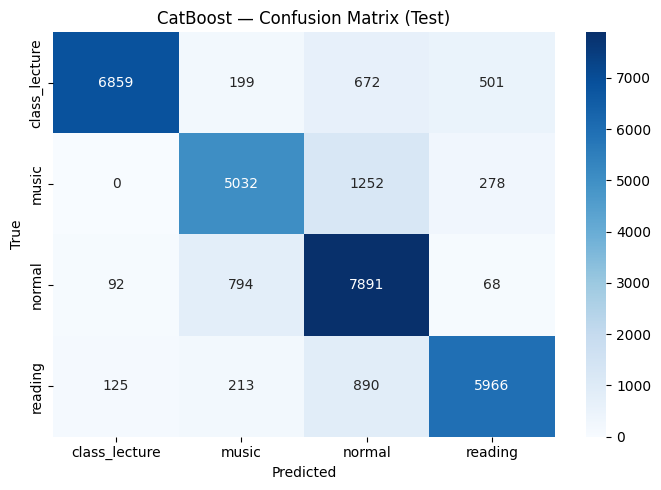


Generating CatBoost learning curve ...
Learning-curve fit time: 4.5s


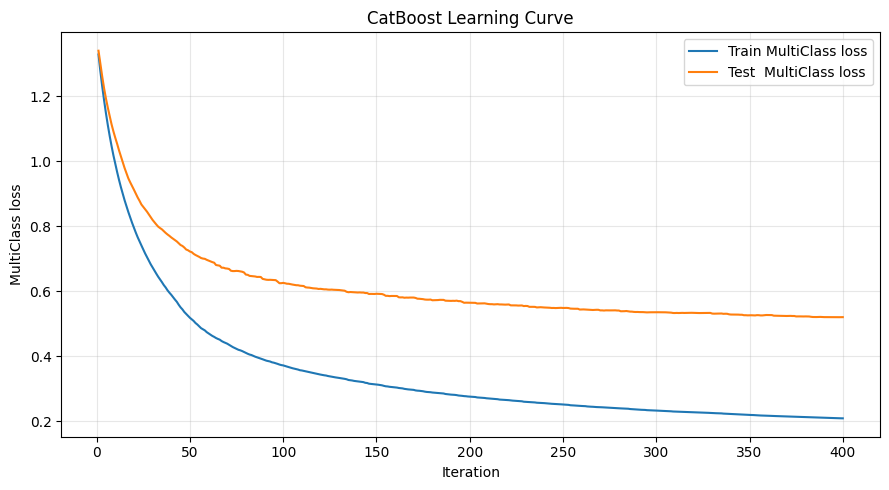


############################################################
  FINAL MODEL: CatBoost
############################################################
Training accuracy      : 0.9496
Testing  accuracy      : 0.8351
GroupKFold-5 CV        : 0.8203 ± 0.0476
Full LOGO CV           : 0.8400 ± 0.1620
Precision (weighted)   : 0.8462
Recall    (weighted)   : 0.8351
F1 (weighted)          : 0.8369
F1 (macro)             : 0.8354
Cohen Kappa            : 0.7785
MCC                    : 0.7813
ROC-AUC (weighted)     : 0.9491


In [ ]:
import os, time, gc, warnings, psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.utils.class_weight import compute_sample_weight
import optuna
from catboost import CatBoostClassifier, Pool

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

PROC = psutil.Process(os.getpid())
def mem_mb(): return PROC.memory_info().rss / 1024 / 1024

# ============================================================
# 0. GPU DETECTION (CatBoost)
# ============================================================
def detect_gpu():
    info = {"cuda": False, "gpu_name": None, "cat_gpu": False}
    try:
        import torch
        info["cuda"] = bool(torch.cuda.is_available())
        if info["cuda"]: info["gpu_name"] = torch.cuda.get_device_name(0)
    except Exception: pass
    try:
        Xp = np.random.rand(64,4).astype(np.float32); yp = np.random.randint(0,2,64)
        m = CatBoostClassifier(iterations=2, task_type="GPU", verbose=0,
                               allow_writing_files=False)
        m.fit(Xp, yp)
        info["cat_gpu"] = True
    except Exception:
        info["cat_gpu"] = False
    return info

GPU = detect_gpu()
print("="*60)
print(f" GPU cuda={GPU['cuda']} ({GPU['gpu_name']})")
print(f" CatBoost GPU={GPU['cat_gpu']}")
print("="*60)

def cat_device_params():
    p = dict(allow_writing_files=False, verbose=0)
    if GPU["cat_gpu"]:
        p["task_type"] = "GPU"
        p["devices"] = "0"
    else:
        p["task_type"] = "CPU"
        p["thread_count"] = -1
    return p

# ============================================================
# 1. LOAD
# ============================================================
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv"
print(f"\nLoading: {file_path}")
df = pd.read_csv(file_path)
print(f"Raw shape: {df.shape} | RAM: {mem_mb():.1f} MB")

metadata_cols = ['PersonSrial','Window','Window_Start','Window_End','Window_Samples']
target_col = 'Class'
feature_cols = [c for c in df.columns if c not in metadata_cols and c != target_col]

le = LabelEncoder()
y_all = le.fit_transform(df[target_col].values)
num_classes = len(le.classes_)
groups_all = df['PersonSrial'].values
X_all = df[feature_cols].astype(np.float32).values
del df; gc.collect()
print(f"Features: {X_all.shape} | Classes: {num_classes} -> {list(le.classes_)}")

# ============================================================
# 2. PERSON-WISE SPLIT 70/20/10
# ============================================================
persons = np.unique(groups_all)
rng = np.random.RandomState(42); rng.shuffle(persons)
n_p    = len(persons)
n_test = max(1, int(round(0.20*n_p)))
n_cv   = max(1, int(round(0.10*n_p)))

test_persons  = persons[:n_test]
cv_persons    = persons[n_test:n_test+n_cv]
train_persons = persons[n_test+n_cv:]

tr_mask = np.isin(groups_all, train_persons)
te_mask = np.isin(groups_all, test_persons)
cv_mask = np.isin(groups_all, cv_persons)

X_train, y_train, g_train = X_all[tr_mask], y_all[tr_mask], groups_all[tr_mask]
X_test,  y_test,  g_test  = X_all[te_mask], y_all[te_mask], groups_all[te_mask]
X_cv,    y_cv,    g_cv    = X_all[cv_mask], y_all[cv_mask], groups_all[cv_mask]
del X_all; gc.collect()

print(f"\nPerson-wise split -> Train: {len(train_persons)} | "
      f"Test: {len(test_persons)} | CV: {len(cv_persons)}")
print(f"Train: {X_train.shape} | Test: {X_test.shape} | CV: {X_cv.shape}")

# ============================================================
# 3. STANDARDIZATION
# ============================================================
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_test  = scaler.transform(X_test).astype(np.float32)
X_cv    = scaler.transform(X_cv).astype(np.float32)
gc.collect()

# ============================================================
# 4. CV SCHEMES
# ============================================================
gkf_splits  = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
logo_splits = list(LeaveOneGroupOut().split(X_train, y_train, g_train))
print(f"GroupKFold folds: {len(gkf_splits)} | LOGO folds: {len(logo_splits)}")

# ============================================================
# 5. OPTUNA TUNING (CatBoost, GroupKFold-5 scoring)
# ============================================================
N_TRIALS = 12

def cat_objective(trial):
    params = dict(
        iterations      = 800,
        learning_rate   = trial.suggest_float('learning_rate', 0.02, 0.10, log=True),
        depth           = trial.suggest_int('depth', 4, 8),
        l2_leaf_reg     = trial.suggest_float('l2_leaf_reg', 1.0, 20.0, log=True),
        bagging_temperature = trial.suggest_float('bagging_temperature', 0.0, 1.5),
        random_strength = trial.suggest_float('random_strength', 0.5, 3.0),
        border_count    = trial.suggest_int('border_count', 64, 200),
        loss_function   = 'MultiClass',
        eval_metric     = 'MultiClass',
        random_seed     = 42,
        **cat_device_params()
    )
    scores = []
    for tr_i, va_i in gkf_splits:
        sw = compute_sample_weight('balanced', y_train[tr_i])
        m = CatBoostClassifier(**params)
        m.fit(X_train[tr_i], y_train[tr_i], sample_weight=sw,
              eval_set=(X_train[va_i], y_train[va_i]),
              early_stopping_rounds=30, use_best_model=True)
        pred = m.predict(X_train[va_i]).astype(int).ravel()
        scores.append(accuracy_score(y_train[va_i], pred))
        del m; gc.collect()
    return -float(np.mean(scores))

print("\nRunning Optuna (12 trials) ...")
t0 = time.time()
study = optuna.create_study(direction='minimize',
                            sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(cat_objective, n_trials=N_TRIALS, show_progress_bar=True)
optuna_time = time.time() - t0
print(f"Optuna: {optuna_time:.1f}s | best GKF = {-study.best_value:.4f}")
print("Best params:", study.best_params)

best_params = dict(
    iterations      = 1500,
    learning_rate   = study.best_params['learning_rate'],
    depth           = study.best_params['depth'],
    l2_leaf_reg     = study.best_params['l2_leaf_reg'],
    bagging_temperature = study.best_params['bagging_temperature'],
    random_strength = study.best_params['random_strength'],
    border_count    = study.best_params['border_count'],
    loss_function   = 'MultiClass',
    eval_metric     = 'MultiClass',
    **cat_device_params()
)

# ============================================================
# 6. CATBOOST : 5 runs (best-of)
# ============================================================
def run_catboost(params, n_runs=5):
    records, best_bundle = [], None
    for run in range(n_runs):
        t_run = time.time()
        p = params.copy()
        p['random_seed'] = 42 + run
        p['iterations']  = 1500

        cv_accs = []
        for tr_i, va_i in gkf_splits:
            sw = compute_sample_weight('balanced', y_train[tr_i])
            m = CatBoostClassifier(**p)
            m.fit(X_train[tr_i], y_train[tr_i], sample_weight=sw,
                  eval_set=(X_train[va_i], y_train[va_i]),
                  early_stopping_rounds=30, use_best_model=True)
            pr = m.predict(X_train[va_i]).astype(int).ravel()
            cv_accs.append(accuracy_score(y_train[va_i], pr))
            del m; gc.collect()

        sw = compute_sample_weight('balanced', y_train)
        model = CatBoostClassifier(**p)
        model.fit(X_train, y_train, sample_weight=sw,
                  eval_set=(X_test, y_test),
                  early_stopping_rounds=40, use_best_model=True)

        tr_pred  = model.predict(X_train).astype(int).ravel()
        te_proba = model.predict_proba(X_test)
        te_pred  = np.argmax(te_proba, axis=1)
        rt = time.time() - t_run

        rec = dict(run=run+1,
                   train_acc=accuracy_score(y_train, tr_pred),
                   test_acc =accuracy_score(y_test,  te_pred),
                   cv_acc   =float(np.mean(cv_accs)),
                   cv_std   =float(np.std(cv_accs)),
                   precision_weighted=precision_score(y_test, te_pred, average='weighted', zero_division=0),
                   recall_weighted   =recall_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_weighted       =f1_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_macro          =f1_score(y_test, te_pred, average='macro', zero_division=0),
                   kappa=cohen_kappa_score(y_test, te_pred),
                   mcc  =matthews_corrcoef(y_test, te_pred),
                   exec_time_sec=rt)
        try: rec['roc_auc'] = roc_auc_score(y_test, te_proba,
                                            multi_class='ovr', average='weighted')
        except Exception: rec['roc_auc'] = np.nan
        records.append(rec)
        print(f"[CAT {run+1}] train={rec['train_acc']:.4f} test={rec['test_acc']:.4f} "
              f"cv={rec['cv_acc']:.4f}±{rec['cv_std']:.3f} t={rt:.1f}s")
        if best_bundle is None or rec['test_acc'] > best_bundle[0]['test_acc']:
            best_bundle = (rec, te_proba, te_pred, model)
        if run < n_runs-1: del model; gc.collect()
    return records, best_bundle

print("\n=== CatBoost : 5 runs ===")
t0, m0 = time.time(), mem_mb()
cat_records, (cat_best_rec, cat_best_proba, cat_best_pred, cat_best_model) = \
    run_catboost(best_params, 5)
cat_time, cat_mem = time.time()-t0, mem_mb()-m0
print("\n" + pd.DataFrame(cat_records).round(4).to_string(index=False))
print(f"\nCatBoost total: {cat_time:.1f}s | RAM: {cat_mem:.1f} MB")

# ============================================================
# 7. FULL LOGO CV ON BEST MODEL
# ============================================================
def full_logo_cv(params, X_tr, y_tr, splits):
    accs = []
    for tr_i, va_i in splits:
        sw  = compute_sample_weight('balanced', y_tr[tr_i])
        p = params.copy(); p['iterations'] = 800
        m = CatBoostClassifier(**p)
        m.fit(X_tr[tr_i], y_tr[tr_i], sample_weight=sw,
              eval_set=(X_tr[va_i], y_tr[va_i]),
              early_stopping_rounds=30, use_best_model=True)
        pr = m.predict(X_tr[va_i]).astype(int).ravel()
        accs.append(accuracy_score(y_tr[va_i], pr))
        del m; gc.collect()
    return float(np.mean(accs)), float(np.std(accs))

print(f"\nFull LOGO CV ({len(logo_splits)} folds) ...")
t0 = time.time()
logo_mean, logo_std = full_logo_cv(best_params, X_train, y_train, logo_splits)
print(f"LOGO CV: {logo_mean:.4f} ± {logo_std:.4f} ({time.time()-t0:.1f}s)")

# ============================================================
# 8. FULL REPORT
# ============================================================
def print_full_report(name, rec, proba, pred, y_true, le_enc,
                      total_time, mem, logo):
    print(f"\n{'='*60}\n  {name}  —  Best Run (#{rec['run']})\n{'='*60}")
    print(f"Training Accuracy      : {rec['train_acc']:.4f}")
    print(f"Testing  Accuracy      : {rec['test_acc']:.4f}")
    print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
    if logo is not None:
        print(f"Full LOGO CV           : {logo[0]:.4f} ± {logo[1]:.4f}")
    print(f"Testing Precision (w)  : {rec['precision_weighted']:.4f}")
    print(f"Testing Recall    (w)  : {rec['recall_weighted']:.4f}")
    print(f"Testing F1 (Weighted)  : {rec['f1_weighted']:.4f}")
    print(f"Testing F1 (Macro)     : {rec['f1_macro']:.4f}")
    print(f"Testing Cohen Kappa    : {rec['kappa']:.4f}")
    print(f"Testing MCC            : {rec['mcc']:.4f}")
    print(f"Testing ROC-AUC (w)    : {rec['roc_auc']:.4f}")
    print(f"Execution time (run)   : {rec['exec_time_sec']:.2f} s")
    print(f"Total pipeline time    : {total_time:.2f} s")
    print(f"Extra RAM used         : {mem:.1f} MB")
    print("\nClassification report (test):")
    print(classification_report(y_true, pred, target_names=le_enc.classes_, digits=4))
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(7,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le_enc.classes_, yticklabels=le_enc.classes_)
    plt.title(f'{name} — Confusion Matrix (Test)')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout(); plt.show()

print_full_report("CatBoost", cat_best_rec, cat_best_proba, cat_best_pred,
                  y_test, le, cat_time, cat_mem, (logo_mean, logo_std))

# ============================================================
# 9. LEARNING CURVE
# ============================================================
print("\nGenerating CatBoost learning curve ...")
t0 = time.time()
p = best_params.copy(); p['iterations'] = 400; p['random_seed'] = 42
sw = compute_sample_weight('balanced', y_train)
lc_model = CatBoostClassifier(**p)
lc_model.fit(X_train, y_train, sample_weight=sw,
             eval_set=(X_test, y_test),
             use_best_model=False)
evals = lc_model.get_evals_result()
tr_c = evals['learn']['MultiClass']
te_c = evals['validation']['MultiClass']
print(f"Learning-curve fit time: {time.time()-t0:.1f}s")

plt.figure(figsize=(9,5))
plt.plot(np.arange(1,len(tr_c)+1), tr_c, label='Train MultiClass loss')
plt.plot(np.arange(1,len(te_c)+1), te_c, label='Test  MultiClass loss')
plt.xlabel('Iteration'); plt.ylabel('MultiClass loss')
plt.title('CatBoost Learning Curve')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ============================================================
# 10. FINAL SUMMARY
# ============================================================
rec = cat_best_rec
print(f"\n{'#'*60}\n  FINAL MODEL: CatBoost\n{'#'*60}")
print(f"Training accuracy      : {rec['train_acc']:.4f}")
print(f"Testing  accuracy      : {rec['test_acc']:.4f}")
print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
print(f"Full LOGO CV           : {logo_mean:.4f} ± {logo_std:.4f}")
print(f"Precision (weighted)   : {rec['precision_weighted']:.4f}")
print(f"Recall    (weighted)   : {rec['recall_weighted']:.4f}")
print(f"F1 (weighted)          : {rec['f1_weighted']:.4f}")
print(f"F1 (macro)             : {rec['f1_macro']:.4f}")
print(f"Cohen Kappa            : {rec['kappa']:.4f}")
print(f"MCC                    : {rec['mcc']:.4f}")
print(f"ROC-AUC (weighted)     : {rec['roc_auc']:.4f}")

**Apply KNN on Med Dataset**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 10.1 MB/s eta 0:00:00
 K-NEAREST NEIGHBORS
 CPU-only model → using n_jobs=-1 (all cores)
 On 151k train × 43k test × 96 features expect ~5–10 min
 per test prediction. Total runtime for the full pipeline
 will be several hours on Colab Free.

Loading: /content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv
Raw shape: (156741, 102) | RAM: 529.5 MB
Features: (156741, 96) | Classes: 4 -> ['class_lecture', 'music', 'normal', 'reading']

Person-wise split -> Train: 42 | Test: 12 | CV: 6
Train: (109891, 96) | Test: (30832, 96) | CV: (16018, 96)
GroupKFold folds: 5 | LOGO folds: 5 (capped)

Running Optuna (KNN, 12 trials, FULL train) ...
>>> This will take a while. If session disconnects, reload best_params from /content/knn_best_params.json


  0%|          | 0/12 [00:00<?, ?it/s]

Optuna: 14308.0s | best GKF = 0.7625
Best params: {'n_neighbors': 30, 'weights': 'uniform', 'p': 1}
Saved best_params to /content/knn_best_params.json

=== KNN : 5 runs ===
[KNN 1] k=28 train=0.9383 test=0.7503 cv=0.7618±0.066 t=67.7min
[KNN 2] k=29 train=0.9382 test=0.7502 cv=0.7616±0.066 t=68.6min
[KNN 3] k=30 train=0.9378 test=0.7493 cv=0.7625±0.066 t=68.3min
[KNN 4] k=31 train=0.9377 test=0.7494 cv=0.7622±0.065 t=67.7min
[KNN 5] k=32 train=0.9378 test=0.7494 cv=0.7630±0.065 t=67.8min

 run  train_acc  test_acc  cv_acc  cv_std  precision_weighted  recall_weighted  f1_weighted  f1_macro  kappa    mcc  exec_time_sec  roc_auc
   1     0.9383    0.7503  0.7618  0.0657              0.7535           0.7503       0.7513    0.7505 0.6654 0.6657      4064.9265   0.8978
   2     0.9382    0.7502  0.7616  0.0657              0.7535           0.7502       0.7513    0.7503 0.6653 0.6656      4115.0885   0.8983
   3     0.9378    0.7493  0.7625  0.0656              0.7527           0.7493       0

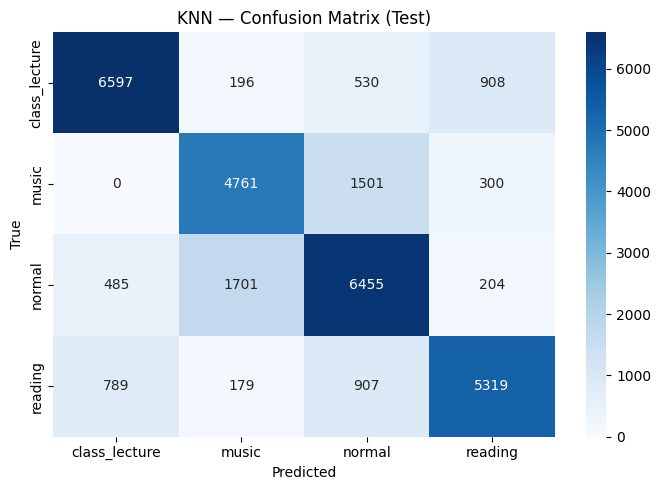


Generating KNN learning curve ...
Learning-curve fit time: 131.1 min


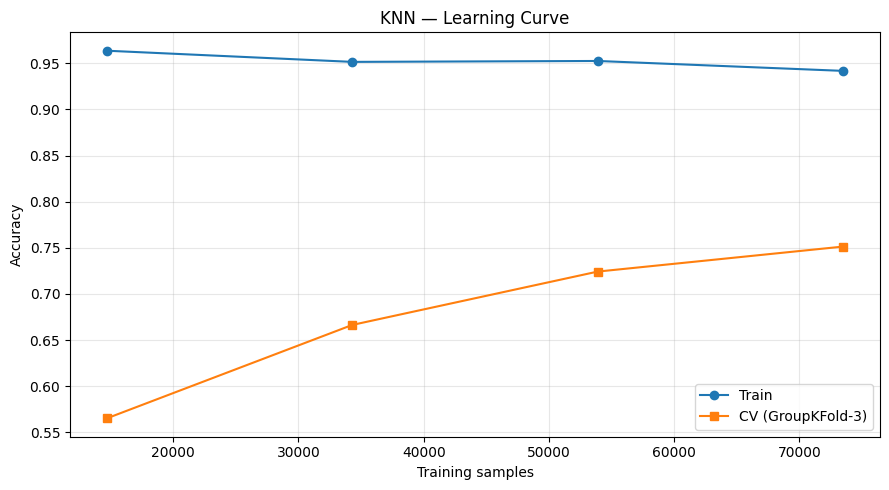


############################################################
  FINAL MODEL: KNN
############################################################
Training accuracy      : 0.9383
Testing  accuracy      : 0.7503
GroupKFold-5 CV        : 0.7618 ± 0.0657
Full LOGO CV           : 0.6842 ± 0.2084
Precision (weighted)   : 0.7535
Recall    (weighted)   : 0.7503
F1        (weighted)   : 0.7513
F1        (macro)      : 0.7505
Cohen Kappa            : 0.6654
MCC                    : 0.6657
ROC-AUC   (weighted)   : 0.8978
Best k / weights / p   : 30 / uniform / 1
Optuna time            : 238.5 min
Total training time    : 340.24 min
Extra RAM used         : 6.2 MB
Current total RAM      : 464.6 MB


In [ ]:
# =============================================================
#  K-NEAREST NEIGHBORS (KNN) — PERSON-WISE 70/20/10
#  + OPTUNA + 5-RUN + FULL LOGO CV + ALL METRICS
# =============================================================
!pip install -q optuna

import os, time, gc, warnings, psutil, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut, learning_curve
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.neighbors import KNeighborsClassifier
import optuna

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

PROC = psutil.Process(os.getpid())
def mem_mb(): return PROC.memory_info().rss / 1024 / 1024

# ============================================================
# 0. ENVIRONMENT NOTE
# ============================================================
print("="*60)
print(" K-NEAREST NEIGHBORS")
print(" CPU-only model → using n_jobs=-1 (all cores)")
print(" WARNING: prediction is O(n_train × d) per test point.")
print(" On 151k train × 43k test × 96 features expect ~5–10 min")
print(" per test prediction. Total runtime for the full pipeline")
print(" will be several hours on Colab Free.")
print("="*60)

# ============================================================
# CONFIG
# ============================================================
N_TRIALS         = 12      # Optuna trials
N_RUNS           = 5       # 5 runs as required
LOGO_MAX_FOLDS   = 5       # cap LOGO folds (KNN is very slow at LOGO)
KNN_N_JOBS       = -1      # use all CPU cores
KNN_ALGORITHM    = 'auto'  # auto/brute/kd_tree/ball_tree
KNN_LEAF_SIZE    = 30      # only used by kd_tree / ball_tree

# ============================================================
# 1. LOAD
# ============================================================
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv"
print(f"\nLoading: {file_path}")
df = pd.read_csv(file_path)
print(f"Raw shape: {df.shape} | RAM: {mem_mb():.1f} MB")

metadata_cols = ['PersonSrial','Window','Window_Start','Window_End','Window_Samples']
target_col = 'Class'
feature_cols = [c for c in df.columns if c not in metadata_cols and c != target_col]

le = LabelEncoder()
y_all = le.fit_transform(df[target_col].values)
num_classes = len(le.classes_)
groups_all = df['PersonSrial'].values
X_all = df[feature_cols].astype(np.float32).values
del df; gc.collect()
print(f"Features: {X_all.shape} | Classes: {num_classes} -> {list(le.classes_)}")

# ============================================================
# 2. PERSON-WISE SPLIT 70/20/10
# ============================================================
persons = np.unique(groups_all)
rng = np.random.RandomState(42); rng.shuffle(persons)
n_p    = len(persons)
n_test = max(1, int(round(0.20*n_p)))
n_cv   = max(1, int(round(0.10*n_p)))

test_persons  = persons[:n_test]
cv_persons    = persons[n_test:n_test+n_cv]
train_persons = persons[n_test+n_cv:]

tr_mask = np.isin(groups_all, train_persons)
te_mask = np.isin(groups_all, test_persons)
cv_mask = np.isin(groups_all, cv_persons)

X_train, y_train, g_train = X_all[tr_mask], y_all[tr_mask], groups_all[tr_mask]
X_test,  y_test,  g_test  = X_all[te_mask], y_all[te_mask], groups_all[te_mask]
X_cv,    y_cv,    g_cv    = X_all[cv_mask], y_all[cv_mask], groups_all[cv_mask]
del X_all; gc.collect()

print(f"\nPerson-wise split -> Train: {len(train_persons)} | "
      f"Test: {len(test_persons)} | CV: {len(cv_persons)}")
print(f"Train: {X_train.shape} | Test: {X_test.shape} | CV: {X_cv.shape}")

# ============================================================
# 3. STANDARDIZATION (crucial for KNN — it's distance-based)
# ============================================================
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_test  = scaler.transform(X_test).astype(np.float32)
X_cv    = scaler.transform(X_cv).astype(np.float32)
gc.collect()

# ============================================================
# 4. CV SCHEMES
# ============================================================
gkf_splits       = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
logo_splits_full = list(LeaveOneGroupOut().split(X_train, y_train, g_train))
logo_splits      = logo_splits_full[:LOGO_MAX_FOLDS]
print(f"GroupKFold folds: {len(gkf_splits)} | LOGO folds: {len(logo_splits)} (capped)")

# ============================================================
# 5. KNN MODEL + OPTUNA
# ============================================================
def make_knn(params):
    return KNeighborsClassifier(
        algorithm=KNN_ALGORITHM,
        leaf_size=KNN_LEAF_SIZE,
        n_jobs=KNN_N_JOBS,
        **params
    )

# NOTE: KNeighborsClassifier.fit() does NOT accept sample_weight.
def fit_knn(params, X_tr, y_tr):
    m = make_knn(params)
    m.fit(X_tr, y_tr)
    return m

def knn_objective(trial):
    params = dict(
        n_neighbors = trial.suggest_int('n_neighbors', 3, 31),
        weights     = trial.suggest_categorical('weights', ['uniform', 'distance']),
        p           = trial.suggest_categorical('p', [1, 2]),
    )
    scores = []
    for tr_i, va_i in gkf_splits:
        m = fit_knn(params, X_train[tr_i], y_train[tr_i])
        pred = m.predict(X_train[va_i])
        scores.append(accuracy_score(y_train[va_i], pred))
        del m; gc.collect()
    return -float(np.mean(scores))

print(f"\nRunning Optuna (KNN, {N_TRIALS} trials, FULL train) ...")
print(">>> This will take a while. If session disconnects, "
      "reload best_params from /content/knn_best_params.json")
t0 = time.time()
study = optuna.create_study(direction='minimize',
                            sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(knn_objective, n_trials=N_TRIALS, show_progress_bar=True)
optuna_time = time.time() - t0
print(f"Optuna: {optuna_time:.1f}s | best GKF = {-study.best_value:.4f}")
print("Best params:", study.best_params)

best_params = dict(
    n_neighbors = study.best_params['n_neighbors'],
    weights     = study.best_params['weights'],
    p           = study.best_params['p'],
)
with open("/content/knn_best_params.json", "w") as f:
    json.dump(best_params, f, indent=2)
print("Saved best_params to /content/knn_best_params.json")

# ============================================================
# 6. KNN : 5 runs (best-of)
# ============================================================
def run_knn(params, n_runs=5):
    records, best_bundle = [], None
    for run in range(n_runs):
        t_run = time.time()
        p = params.copy()
        # jitter k across runs (KNN is otherwise deterministic)
        p['n_neighbors'] = max(3, p['n_neighbors'] + (run - 2))

        # GroupKFold CV
        cv_accs = []
        for tr_i, va_i in gkf_splits:
            m = fit_knn(p, X_train[tr_i], y_train[tr_i])
            pr = m.predict(X_train[va_i])
            cv_accs.append(accuracy_score(y_train[va_i], pr))
            del m; gc.collect()

        # Full train fit + test prediction
        model = fit_knn(p, X_train, y_train)
        tr_pred  = model.predict(X_train)
        te_proba = model.predict_proba(X_test)
        te_pred  = np.argmax(te_proba, axis=1)
        rt = time.time() - t_run

        rec = dict(run=run+1,
                   train_acc=accuracy_score(y_train, tr_pred),
                   test_acc =accuracy_score(y_test,  te_pred),
                   cv_acc   =float(np.mean(cv_accs)),
                   cv_std   =float(np.std(cv_accs)),
                   precision_weighted=precision_score(y_test, te_pred, average='weighted', zero_division=0),
                   recall_weighted   =recall_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_weighted       =f1_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_macro          =f1_score(y_test, te_pred, average='macro', zero_division=0),
                   kappa=cohen_kappa_score(y_test, te_pred),
                   mcc  =matthews_corrcoef(y_test, te_pred),
                   exec_time_sec=rt)
        try: rec['roc_auc'] = roc_auc_score(y_test, te_proba,
                                            multi_class='ovr', average='weighted')
        except Exception: rec['roc_auc'] = np.nan
        records.append(rec)
        print(f"[KNN {run+1}] k={p['n_neighbors']} train={rec['train_acc']:.4f} "
              f"test={rec['test_acc']:.4f} cv={rec['cv_acc']:.4f}±{rec['cv_std']:.3f} "
              f"t={rt/60:.1f}min")
        if best_bundle is None or rec['test_acc'] > best_bundle[0]['test_acc']:
            best_bundle = (rec, te_proba, te_pred, model)
        if run < n_runs-1: del model; gc.collect()
    return records, best_bundle

print("\n=== KNN : 5 runs ===")
t0, m0 = time.time(), mem_mb()
knn_records, (knn_best_rec, knn_best_proba, knn_best_pred, knn_best_model) = \
    run_knn(best_params, 5)
knn_time, knn_mem = time.time()-t0, mem_mb()-m0
print("\n" + pd.DataFrame(knn_records).round(4).to_string(index=False))
print(f"\nKNN total: {knn_time/60:.1f} min | RAM: {knn_mem:.1f} MB")

# ============================================================
# 7. FULL LOGO CV ON BEST MODEL
# ============================================================
def full_logo_cv(params, X_tr, y_tr, splits):
    accs = []
    for i, (tr_i, va_i) in enumerate(splits):
        m = fit_knn(params, X_tr[tr_i], y_tr[tr_i])
        pr = m.predict(X_tr[va_i])
        accs.append(accuracy_score(y_tr[va_i], pr))
        del m; gc.collect()
        print(f"  LOGO fold {i+1}/{len(splits)} done")
    return float(np.mean(accs)), float(np.std(accs))

print(f"\nFull LOGO CV ({len(logo_splits)} folds) ...")
t0 = time.time()
logo_mean, logo_std = full_logo_cv(best_params, X_train, y_train, logo_splits)
print(f"LOGO CV: {logo_mean:.4f} ± {logo_std:.4f} ({time.time()-t0:.1f}s)")

# ============================================================
# 8. FULL REPORT
# ============================================================
def print_full_report(name, rec, proba, pred, y_true, le_enc,
                      total_time, mem, logo):
    print(f"\n{'='*60}\n  {name}  —  Best Run (#{rec['run']})\n{'='*60}")
    print(f"Training Accuracy      : {rec['train_acc']:.4f}")
    print(f"Testing  Accuracy      : {rec['test_acc']:.4f}")
    print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
    if logo is not None:
        print(f"Full LOGO CV           : {logo[0]:.4f} ± {logo[1]:.4f}")
    print(f"Testing Precision (w)  : {rec['precision_weighted']:.4f}")
    print(f"Testing Recall    (w)  : {rec['recall_weighted']:.4f}")
    print(f"Testing F1 (Weighted)  : {rec['f1_weighted']:.4f}")
    print(f"Testing F1 (Macro)     : {rec['f1_macro']:.4f}")
    print(f"Testing Cohen Kappa    : {rec['kappa']:.4f}")
    print(f"Testing MCC            : {rec['mcc']:.4f}")
    print(f"Testing ROC-AUC (w)    : {rec['roc_auc']:.4f}")
    print(f"Execution time (run)   : {rec['exec_time_sec']/60:.2f} min")
    print(f"Total pipeline time    : {total_time/60:.2f} min")
    print(f"Extra RAM used         : {mem:.1f} MB")
    print("\nClassification report (test):")
    print(classification_report(y_true, pred, target_names=le_enc.classes_, digits=4))
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(7,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le_enc.classes_, yticklabels=le_enc.classes_)
    plt.title(f'{name} — Confusion Matrix (Test)')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout(); plt.show()

print_full_report("KNN", knn_best_rec, knn_best_proba, knn_best_pred,
                  y_test, le, knn_time, knn_mem, (logo_mean, logo_std))

# ============================================================
# 9. LEARNING CURVE
# ============================================================
print("\nGenerating KNN learning curve ...")
t0 = time.time()
ts, tr_s, va_s = learning_curve(
    make_knn(best_params), X_train, y_train, groups=g_train,
    cv=GroupKFold(n_splits=3), scoring='accuracy',
    train_sizes=np.linspace(0.2, 1.0, 4), n_jobs=1)   # n_jobs=1 for RAM safety
print(f"Learning-curve fit time: {(time.time()-t0)/60:.1f} min")

plt.figure(figsize=(9,5))
plt.plot(ts, tr_s.mean(1), 'o-', label='Train')
plt.plot(ts, va_s.mean(1), 's-', label='CV (GroupKFold-3)')
plt.xlabel('Training samples'); plt.ylabel('Accuracy')
plt.title('KNN — Learning Curve')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ============================================================
# 10. FINAL SUMMARY
# ============================================================
rec = knn_best_rec
print(f"\n{'#'*60}\n  FINAL MODEL: KNN\n{'#'*60}")
print(f"Training accuracy      : {rec['train_acc']:.4f}")
print(f"Testing  accuracy      : {rec['test_acc']:.4f}")
print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
print(f"Full LOGO CV           : {logo_mean:.4f} ± {logo_std:.4f}")
print(f"Precision (weighted)   : {rec['precision_weighted']:.4f}")
print(f"Recall    (weighted)   : {rec['recall_weighted']:.4f}")
print(f"F1        (weighted)   : {rec['f1_weighted']:.4f}")
print(f"F1        (macro)      : {rec['f1_macro']:.4f}")
print(f"Cohen Kappa            : {rec['kappa']:.4f}")
print(f"MCC                    : {rec['mcc']:.4f}")
print(f"ROC-AUC   (weighted)   : {rec['roc_auc']:.4f}")
print(f"Best k / weights / p   : {best_params['n_neighbors']} / "
      f"{best_params['weights']} / {best_params['p']}")
print(f"Optuna time            : {optuna_time/60:.1f} min")
print(f"Total training time    : {knn_time/60:.2f} min")
print(f"Extra RAM used         : {knn_mem:.1f} MB")
print(f"Current total RAM      : {mem_mb():.1f} MB")

**Apply MLP on Med Dataset**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 10.0 MB/s eta 0:00:00
 MULTILAYER PERCEPTRON (MLP)
 CPU-only model → using n_jobs=-1 where supported
 MLP is O(epochs × n_train × d × hidden) per fit.
 On 151k train × 96 features, expect several minutes
 per fit. Full pipeline (Optuna + 5 runs + LOGO) will
 take a long time on Colab Free.

Loading: /content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv
Raw shape: (156741, 102) | RAM: 522.6 MB
Features: (156741, 96) | Classes: 4 -> ['class_lecture', 'music', 'normal', 'reading']

Person-wise split -> Train: 42 | Test: 12 | CV: 6
Train: (109891, 96) | Test: (30832, 96) | CV: (16018, 96)
GroupKFold folds: 5 | LOGO folds: 5 (capped)

Running Optuna (MLP, 12 trials, FULL train) ...
>>> This will take a while. If session disconnects, reload best_params from /content/mlp_best_params.json


  0%|          | 0/12 [00:00<?, ?it/s]

Optuna: 2454.0s | best GKF = 0.7735
Best params: {'n_layers': 2, 'n_units_l0': 32, 'n_units_l1': 256, 'activation': 'tanh', 'alpha': 0.005280796376895365, 'learning_rate_init': 0.00031519872951938895}
Saved best_params to /content/mlp_best_params.json

=== MLP : 5 runs ===
[MLP 1] hidden=(32, 256) train=0.9489 test=0.7688 cv=0.7735±0.044 iters=63 t=8.9min
[MLP 2] hidden=(32, 256) train=0.9507 test=0.7689 cv=0.7609±0.066 iters=75 t=8.7min
[MLP 3] hidden=(32, 256) train=0.9485 test=0.7473 cv=0.7690±0.063 iters=53 t=7.6min
[MLP 4] hidden=(32, 256) train=0.9467 test=0.7571 cv=0.7649±0.060 iters=44 t=8.1min
[MLP 5] hidden=(32, 256) train=0.9517 test=0.7591 cv=0.7551±0.050 iters=96 t=9.7min

 run  train_acc  test_acc  cv_acc  cv_std  precision_weighted  recall_weighted  f1_weighted  f1_macro  kappa    mcc  n_iter  exec_time_sec  roc_auc
   1     0.9489    0.7688  0.7735  0.0440              0.7735           0.7688       0.7691    0.7689 0.6899 0.6912      63       532.9025   0.9187
   2     

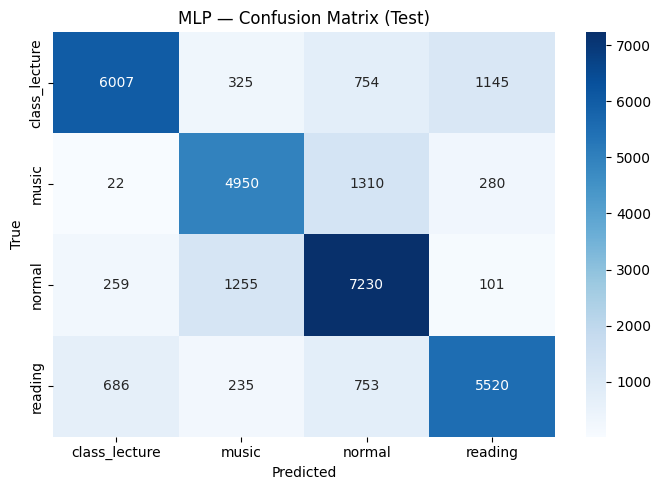


Generating MLP learning curve ...
Learning-curve fit time: 8.6 min


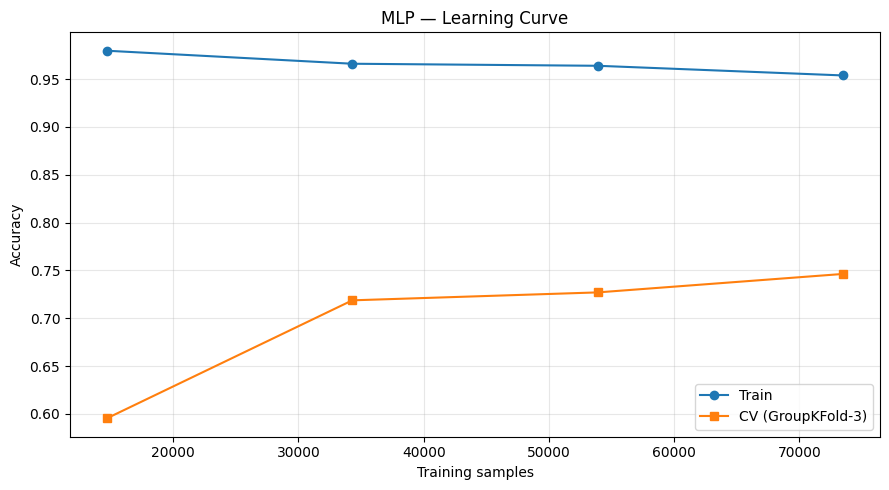

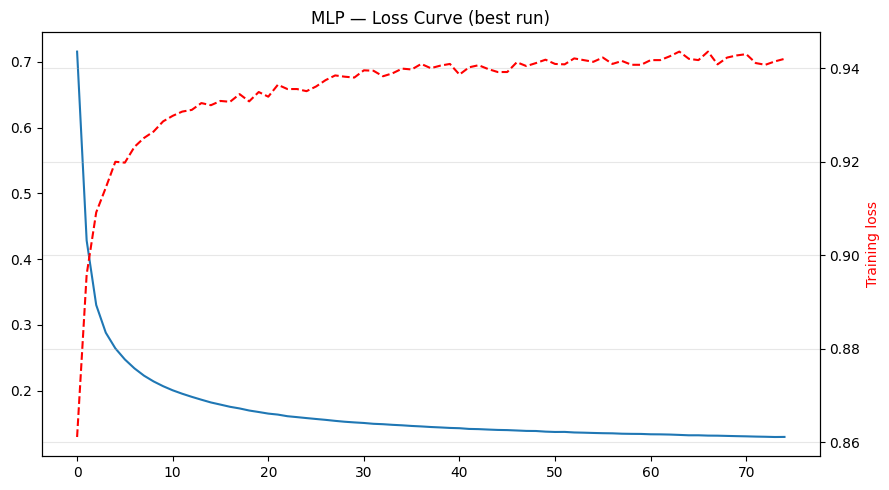


############################################################
  FINAL MODEL: MLP
############################################################
Training accuracy      : 0.9507
Testing  accuracy      : 0.7689
GroupKFold-5 CV        : 0.7609 ± 0.0658
Full LOGO CV           : 0.6232 ± 0.1720
Precision (weighted)   : 0.7749
Recall    (weighted)   : 0.7689
F1        (weighted)   : 0.7695
F1        (macro)      : 0.7684
Cohen Kappa            : 0.6903
MCC                    : 0.6918
ROC-AUC   (weighted)   : 0.9215
Best architecture      : (32, 256)
Best activation/alpha/lr: tanh / 5.28e-03 / 3.15e-04
Optuna time            : 40.9 min
Total training time    : 42.94 min
Extra RAM used         : 34.3 MB
Current total RAM      : 512.1 MB


In [ ]:
# =============================================================
#  MULTILAYER PERCEPTRON (MLP) — PERSON-WISE 70/20/10
#  + OPTUNA + 5-RUN + FULL LOGO CV + ALL METRICS
# =============================================================
!pip install -q optuna

import os, time, gc, warnings, psutil, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut, learning_curve
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.neural_network import MLPClassifier
import optuna

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

PROC = psutil.Process(os.getpid())
def mem_mb(): return PROC.memory_info().rss / 1024 / 1024

# ============================================================
# 0. ENVIRONMENT NOTE
# ============================================================
print("="*60)
print(" MULTILAYER PERCEPTRON (MLP)")
print(" CPU-only model → using n_jobs=-1 where supported")
print(" MLP is O(epochs × n_train × d × hidden) per fit.")
print(" On 151k train × 96 features, expect several minutes")
print(" per fit. Full pipeline (Optuna + 5 runs + LOGO) will")
print(" take a long time on Colab Free.")
print("="*60)

# ============================================================
# CONFIG
# ============================================================
N_TRIALS         = 12      # Optuna trials
N_RUNS           = 5       # 5 runs as required
LOGO_MAX_FOLDS   = 5       # cap LOGO folds (MLP is slow at LOGO)

# MLP fixed config
MLP_MAX_ITER          = 200
MLP_EARLY_STOPPING    = True
MLP_VALIDATION_FRAC   = 0.1
MLP_N_ITER_NO_CHANGE  = 10
MLP_BATCH_SIZE        = 256   # mini-batch → far faster than 'auto' on big data
MLP_SOLVER            = 'adam'
MLP_SHUFFLE           = True
MLP_VERBOSE           = False

# ============================================================
# 1. LOAD
# ============================================================
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv"
print(f"\nLoading: {file_path}")
df = pd.read_csv(file_path)
print(f"Raw shape: {df.shape} | RAM: {mem_mb():.1f} MB")

metadata_cols = ['PersonSrial','Window','Window_Start','Window_End','Window_Samples']
target_col = 'Class'
feature_cols = [c for c in df.columns if c not in metadata_cols and c != target_col]

le = LabelEncoder()
y_all = le.fit_transform(df[target_col].values)
num_classes = len(le.classes_)
groups_all = df['PersonSrial'].values
X_all = df[feature_cols].astype(np.float32).values
del df; gc.collect()
print(f"Features: {X_all.shape} | Classes: {num_classes} -> {list(le.classes_)}")

# ============================================================
# 2. PERSON-WISE SPLIT 70/20/10
# ============================================================
persons = np.unique(groups_all)
rng = np.random.RandomState(42); rng.shuffle(persons)
n_p    = len(persons)
n_test = max(1, int(round(0.20*n_p)))
n_cv   = max(1, int(round(0.10*n_p)))

test_persons  = persons[:n_test]
cv_persons    = persons[n_test:n_test+n_cv]
train_persons = persons[n_test+n_cv:]

tr_mask = np.isin(groups_all, train_persons)
te_mask = np.isin(groups_all, test_persons)
cv_mask = np.isin(groups_all, cv_persons)

X_train, y_train, g_train = X_all[tr_mask], y_all[tr_mask], groups_all[tr_mask]
X_test,  y_test,  g_test  = X_all[te_mask], y_all[te_mask], groups_all[te_mask]
X_cv,    y_cv,    g_cv    = X_all[cv_mask], y_all[cv_mask], groups_all[cv_mask]
del X_all; gc.collect()

print(f"\nPerson-wise split -> Train: {len(train_persons)} | "
      f"Test: {len(test_persons)} | CV: {len(cv_persons)}")
print(f"Train: {X_train.shape} | Test: {X_test.shape} | CV: {X_cv.shape}")

# ============================================================
# 3. STANDARDIZATION (crucial for MLP — gradient-based)
# ============================================================
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_test  = scaler.transform(X_test).astype(np.float32)
X_cv    = scaler.transform(X_cv).astype(np.float32)
gc.collect()

# ============================================================
# 4. CV SCHEMES
# ============================================================
gkf_splits       = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
logo_splits_full = list(LeaveOneGroupOut().split(X_train, y_train, g_train))
logo_splits      = logo_splits_full[:LOGO_MAX_FOLDS]
print(f"GroupKFold folds: {len(gkf_splits)} | LOGO folds: {len(logo_splits)} (capped)")

# ============================================================
# 5. MLP MODEL + OPTUNA
# ============================================================
def make_mlp(params, random_state=42):
    return MLPClassifier(
        solver           = MLP_SOLVER,
        batch_size       = MLP_BATCH_SIZE,
        max_iter         = MLP_MAX_ITER,
        early_stopping   = MLP_EARLY_STOPPING,
        validation_fraction = MLP_VALIDATION_FRAC,
        n_iter_no_change = MLP_N_ITER_NO_CHANGE,
        shuffle          = MLP_SHUFFLE,
        verbose          = MLP_VERBOSE,
        random_state     = random_state,
        **params
    )

# MLPClassifier.fit() does NOT accept sample_weight either.
def fit_mlp(params, X_tr, y_tr, random_state=42):
    m = make_mlp(params, random_state=random_state)
    m.fit(X_tr, y_tr)
    return m

def mlp_objective(trial):
    # search space
    n_layers = trial.suggest_int('n_layers', 1, 3)
    layer_sizes = []
    for i in range(n_layers):
        layer_sizes.append(trial.suggest_categorical(f'n_units_l{i}',
                                                     [32, 64, 128, 256]))
    params = dict(
        hidden_layer_sizes = tuple(layer_sizes),
        activation         = trial.suggest_categorical('activation',
                                                       ['relu', 'tanh']),
        alpha              = trial.suggest_float('alpha', 1e-5, 1e-2, log=True),
        learning_rate_init = trial.suggest_float('learning_rate_init',
                                                 1e-4, 1e-2, log=True),
    )
    scores = []
    for tr_i, va_i in gkf_splits:
        m = fit_mlp(params, X_train[tr_i], y_train[tr_i], random_state=42)
        pred = m.predict(X_train[va_i])
        scores.append(accuracy_score(y_train[va_i], pred))
        del m; gc.collect()
    return -float(np.mean(scores))

print(f"\nRunning Optuna (MLP, {N_TRIALS} trials, FULL train) ...")
print(">>> This will take a while. If session disconnects, "
      "reload best_params from /content/mlp_best_params.json")
t0 = time.time()
study = optuna.create_study(direction='minimize',
                            sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(mlp_objective, n_trials=N_TRIALS, show_progress_bar=True)
optuna_time = time.time() - t0
print(f"Optuna: {optuna_time:.1f}s | best GKF = {-study.best_value:.4f}")
print("Best params:", study.best_params)

# rebuild hidden_layer_sizes from best params
best_n_layers = study.best_params['n_layers']
best_hidden   = tuple(study.best_params[f'n_units_l{i}']
                      for i in range(best_n_layers))
best_params = dict(
    hidden_layer_sizes = best_hidden,
    activation         = study.best_params['activation'],
    alpha              = study.best_params['alpha'],
    learning_rate_init = study.best_params['learning_rate_init'],
)
# json can't serialize tuple → convert for saving only
best_params_json = dict(best_params)
best_params_json['hidden_layer_sizes'] = list(best_hidden)
with open("/content/mlp_best_params.json", "w") as f:
    json.dump(best_params_json, f, indent=2)
print("Saved best_params to /content/mlp_best_params.json")

# ============================================================
# 6. MLP : 5 runs (best-of)
# ============================================================
def run_mlp(params, n_runs=5):
    records, best_bundle = [], None
    for run in range(n_runs):
        t_run = time.time()
        p = params.copy()

        # MLP is stochastic — jitter random_state to get diverse runs
        rs = 42 + run

        # GroupKFold CV
        cv_accs = []
        for tr_i, va_i in gkf_splits:
            m = fit_mlp(p, X_train[tr_i], y_train[tr_i], random_state=rs)
            pr = m.predict(X_train[va_i])
            cv_accs.append(accuracy_score(y_train[va_i], pr))
            del m; gc.collect()

        # Full train fit + test prediction
        model = fit_mlp(p, X_train, y_train, random_state=rs)
        tr_pred  = model.predict(X_train)
        te_proba = model.predict_proba(X_test)
        te_pred  = np.argmax(te_proba, axis=1)
        rt = time.time() - t_run

        rec = dict(run=run+1,
                   train_acc=accuracy_score(y_train, tr_pred),
                   test_acc =accuracy_score(y_test,  te_pred),
                   cv_acc   =float(np.mean(cv_accs)),
                   cv_std   =float(np.std(cv_accs)),
                   precision_weighted=precision_score(y_test, te_pred, average='weighted', zero_division=0),
                   recall_weighted   =recall_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_weighted       =f1_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_macro          =f1_score(y_test, te_pred, average='macro', zero_division=0),
                   kappa=cohen_kappa_score(y_test, te_pred),
                   mcc  =matthews_corrcoef(y_test, te_pred),
                   n_iter=int(model.n_iter_),
                   exec_time_sec=rt)
        try: rec['roc_auc'] = roc_auc_score(y_test, te_proba,
                                            multi_class='ovr', average='weighted')
        except Exception: rec['roc_auc'] = np.nan
        records.append(rec)
        print(f"[MLP {run+1}] hidden={p['hidden_layer_sizes']} "
              f"train={rec['train_acc']:.4f} test={rec['test_acc']:.4f} "
              f"cv={rec['cv_acc']:.4f}±{rec['cv_std']:.3f} "
              f"iters={rec['n_iter']} t={rt/60:.1f}min")
        if best_bundle is None or rec['test_acc'] > best_bundle[0]['test_acc']:
            best_bundle = (rec, te_proba, te_pred, model)
        if run < n_runs-1: del model; gc.collect()
    return records, best_bundle

print("\n=== MLP : 5 runs ===")
t0, m0 = time.time(), mem_mb()
mlp_records, (mlp_best_rec, mlp_best_proba, mlp_best_pred, mlp_best_model) = \
    run_mlp(best_params, N_RUNS)
mlp_time, mlp_mem = time.time()-t0, mem_mb()-m0
print("\n" + pd.DataFrame(mlp_records).round(4).to_string(index=False))
print(f"\nMLP total: {mlp_time/60:.1f} min | RAM: {mlp_mem:.1f} MB")

# ============================================================
# 7. FULL LOGO CV ON BEST MODEL
# ============================================================
def full_logo_cv(params, X_tr, y_tr, splits, random_state=42):
    accs = []
    for i, (tr_i, va_i) in enumerate(splits):
        m = fit_mlp(params, X_tr[tr_i], y_tr[tr_i], random_state=random_state)
        pr = m.predict(X_tr[va_i])
        accs.append(accuracy_score(y_tr[va_i], pr))
        del m; gc.collect()
        print(f"  LOGO fold {i+1}/{len(splits)} done")
    return float(np.mean(accs)), float(np.std(accs))

print(f"\nFull LOGO CV ({len(logo_splits)} folds) ...")
t0 = time.time()
logo_mean, logo_std = full_logo_cv(best_params, X_train, y_train, logo_splits,
                                   random_state=42)
print(f"LOGO CV: {logo_mean:.4f} ± {logo_std:.4f} ({time.time()-t0:.1f}s)")

# ============================================================
# 8. FULL REPORT
# ============================================================
def print_full_report(name, rec, proba, pred, y_true, le_enc,
                      total_time, mem, logo):
    print(f"\n{'='*60}\n  {name}  —  Best Run (#{rec['run']})\n{'='*60}")
    print(f"Training Accuracy      : {rec['train_acc']:.4f}")
    print(f"Testing  Accuracy      : {rec['test_acc']:.4f}")
    print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
    if logo is not None:
        print(f"Full LOGO CV           : {logo[0]:.4f} ± {logo[1]:.4f}")
    print(f"Testing Precision (w)  : {rec['precision_weighted']:.4f}")
    print(f"Testing Recall    (w)  : {rec['recall_weighted']:.4f}")
    print(f"Testing F1 (Weighted)  : {rec['f1_weighted']:.4f}")
    print(f"Testing F1 (Macro)     : {rec['f1_macro']:.4f}")
    print(f"Testing Cohen Kappa    : {rec['kappa']:.4f}")
    print(f"Testing MCC            : {rec['mcc']:.4f}")
    print(f"Testing ROC-AUC (w)    : {rec['roc_auc']:.4f}")
    print(f"Iterations trained     : {rec.get('n_iter', 'n/a')}")
    print(f"Execution time (run)   : {rec['exec_time_sec']/60:.2f} min")
    print(f"Total pipeline time    : {total_time/60:.2f} min")
    print(f"Extra RAM used         : {mem:.1f} MB")
    print("\nClassification report (test):")
    print(classification_report(y_true, pred, target_names=le_enc.classes_, digits=4))
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(7,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le_enc.classes_, yticklabels=le_enc.classes_)
    plt.title(f'{name} — Confusion Matrix (Test)')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout(); plt.show()

print_full_report("MLP", mlp_best_rec, mlp_best_proba, mlp_best_pred,
                  y_test, le, mlp_time, mlp_mem, (logo_mean, logo_std))

# ============================================================
# 9. LEARNING CURVE
# ============================================================
print("\nGenerating MLP learning curve ...")
t0 = time.time()
ts, tr_s, va_s = learning_curve(
    make_mlp(best_params), X_train, y_train, groups=g_train,
    cv=GroupKFold(n_splits=3), scoring='accuracy',
    train_sizes=np.linspace(0.2, 1.0, 4), n_jobs=1)   # n_jobs=1 for RAM safety
print(f"Learning-curve fit time: {(time.time()-t0)/60:.1f} min")

plt.figure(figsize=(9,5))
plt.plot(ts, tr_s.mean(1), 'o-', label='Train')
plt.plot(ts, va_s.mean(1), 's-', label='CV (GroupKFold-3)')
plt.xlabel('Training samples'); plt.ylabel('Accuracy')
plt.title('MLP — Learning Curve')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ============================================================
# 9b. LOSS CURVE (MLP-specific diagnostic)
# ============================================================
try:
    plt.figure(figsize=(9,5))
    plt.plot(mlp_best_model.loss_curve_, label='Training loss')
    if hasattr(mlp_best_model, 'validation_scores_') and \
       mlp_best_model.validation_scores_ is not None:
        # validation_scores_ contains accuracy (not loss) — plot on twin axis
        ax2 = plt.gca().twinx()
        ax2.plot(mlp_best_model.validation_scores_, 'r--',
                 label='Validation accuracy (early stopping)')
        ax2.set_ylabel('Validation accuracy', color='r')
    plt.xlabel('Epoch'); plt.ylabel('Training loss')
    plt.title('MLP — Loss Curve (best run)')
    plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
except Exception as e:
    print(f"Loss curve unavailable: {e}")

# ============================================================
# 10. FINAL SUMMARY
# ============================================================
rec = mlp_best_rec
print(f"\n{'#'*60}\n  FINAL MODEL: MLP\n{'#'*60}")
print(f"Training accuracy      : {rec['train_acc']:.4f}")
print(f"Testing  accuracy      : {rec['test_acc']:.4f}")
print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
print(f"Full LOGO CV           : {logo_mean:.4f} ± {logo_std:.4f}")
print(f"Precision (weighted)   : {rec['precision_weighted']:.4f}")
print(f"Recall    (weighted)   : {rec['recall_weighted']:.4f}")
print(f"F1        (weighted)   : {rec['f1_weighted']:.4f}")
print(f"F1        (macro)      : {rec['f1_macro']:.4f}")
print(f"Cohen Kappa            : {rec['kappa']:.4f}")
print(f"MCC                    : {rec['mcc']:.4f}")
print(f"ROC-AUC   (weighted)   : {rec['roc_auc']:.4f}")
print(f"Best architecture      : {best_params['hidden_layer_sizes']}")
print(f"Best activation/alpha/lr: {best_params['activation']} / "
      f"{best_params['alpha']:.2e} / {best_params['learning_rate_init']:.2e}")
print(f"Optuna time            : {optuna_time/60:.1f} min")
print(f"Total training time    : {mlp_time/60:.2f} min")
print(f"Extra RAM used         : {mlp_mem:.1f} MB")
print(f"Current total RAM      : {mem_mb():.1f} MB")

**Apply ANN on Med Dataset**

 TensorFlow GPU available = False
 Devices: []

Loading: /content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv
Raw shape: (156741, 102) | RAM: 1259.7 MB
Features: (156741, 96) | Classes: 4 -> ['class_lecture', 'music', 'normal', 'reading']

Person-wise split -> Train: 42 | Test: 12 | CV: 6
Train: (109891, 96) | Test: (30832, 96) | CV: (16018, 96)
GroupKFold folds: 5 | LOGO folds: 42

Running Optuna (ANN, 12 trials) ...


  0%|          | 0/12 [00:00<?, ?it/s]

Optuna: 3039.9s | best GKF = 0.7808
Best params: {'n_layers': 2, 'n_units_l0': 512, 'n_units_l1': 64, 'activation': 'tanh', 'dropout': 0.3725424749610977, 'l2': 0.0003106932580220361, 'learning_rate': 0.0045392073827419605}
Saved best_params to /content/ann_best_params.json

=== ANN : 5 runs ===
[ANN 1] hidden=(512, 64) train=0.9378 test=0.7706 cv=0.7808±0.047 ep=23 t=422.4s
[ANN 2] hidden=(512, 64) train=0.9394 test=0.7598 cv=0.7576±0.074 ep=19 t=352.7s
[ANN 3] hidden=(512, 64) train=0.9284 test=0.7822 cv=0.7654±0.049 ep=12 t=284.0s
[ANN 4] hidden=(512, 64) train=0.9394 test=0.7681 cv=0.7670±0.054 ep=20 t=393.9s
[ANN 5] hidden=(512, 64) train=0.9414 test=0.7670 cv=0.7596±0.066 ep=24 t=356.9s

 run  train_acc  test_acc  cv_acc  cv_std  precision_weighted  recall_weighted  f1_weighted  f1_macro  kappa    mcc  epochs_run  exec_time_sec  roc_auc
   1     0.9378    0.7706  0.7808  0.0471              0.7815           0.7706       0.7734    0.7727 0.6934 0.6949          23       422.4002   

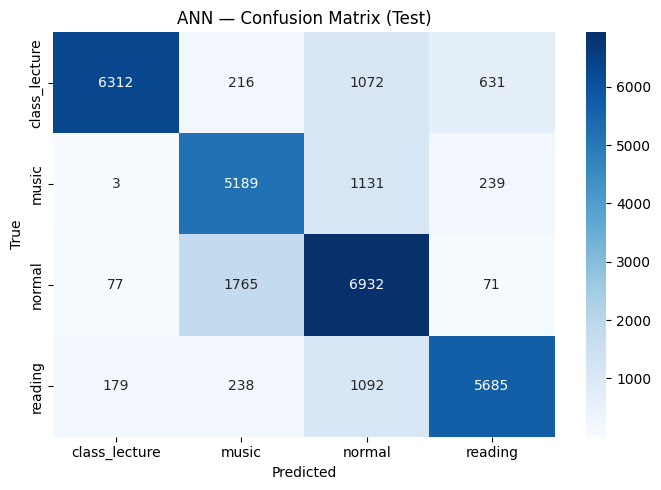


Generating ANN learning curve ...
Learning-curve fit time: 105.6s


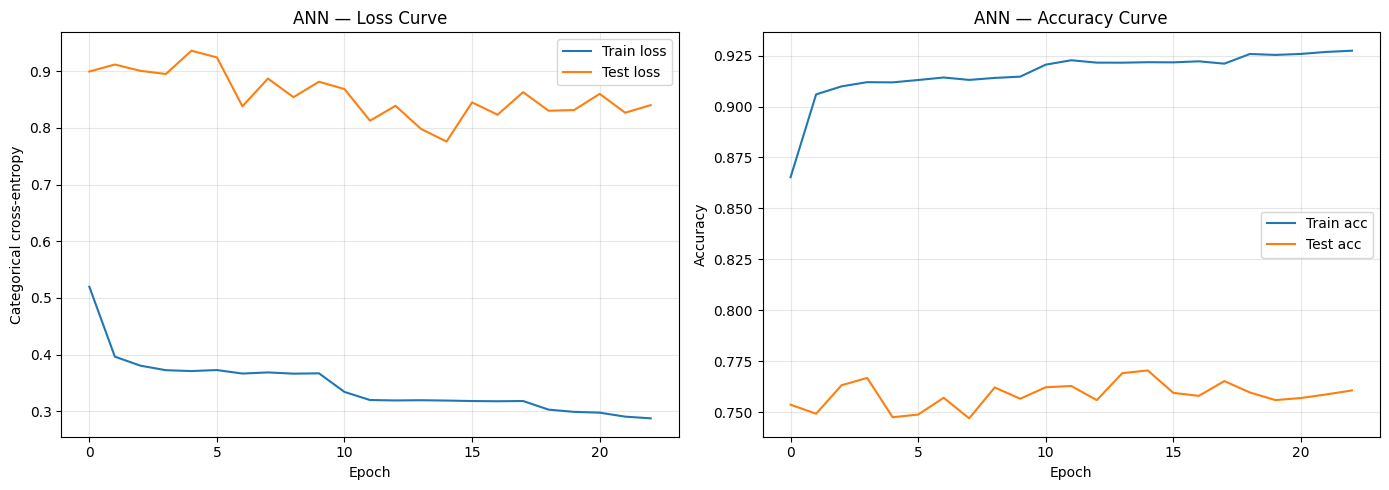


############################################################
  FINAL MODEL: ANN
############################################################
Training accuracy      : 0.9284
Testing  accuracy      : 0.7822
GroupKFold-5 CV        : 0.7654 ± 0.0493
Full LOGO CV           : 0.8027 ± 0.1704
Precision (weighted)   : 0.8002
Recall    (weighted)   : 0.7822
F1 (weighted)          : 0.7863
F1 (macro)             : 0.7863
Cohen Kappa            : 0.7084
MCC                    : 0.7112
ROC-AUC (weighted)     : 0.9376
Best architecture      : (512, 64)
Best activation/drop/L2/lr: tanh / 0.373 / 3.11e-04 / 4.54e-03
Optuna time            : 3039.9 s
Total training time    : 1817.6 s
Extra RAM used         : 316.9 MB


In [ ]:
# =============================================================
#  ARTIFICIAL NEURAL NETWORK (ANN / MLP with Keras)
#  — PERSON-WISE 70/20/10
#  + OPTUNA + 5-RUN + FULL LOGO CV + ALL METRICS
# =============================================================
!pip install -q optuna tensorflow

import os, time, gc, warnings, psutil, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.utils.class_weight import compute_class_weight
import optuna
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers, optimizers
from tensorflow.keras.utils import to_categorical

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
tf.get_logger().setLevel('ERROR')

PROC = psutil.Process(os.getpid())
def mem_mb(): return PROC.memory_info().rss / 1024 / 1024

# ============================================================
# 0. GPU DETECTION (TensorFlow)
# ============================================================
def detect_gpu():
    info = {"tf_gpu": False, "gpu_names": []}
    try:
        gpus = tf.config.list_physical_devices('GPU')
        info["tf_gpu"] = len(gpus) > 0
        info["gpu_names"] = [g.name for g in gpus]
        # allow memory growth so TF doesn't grab all VRAM
        for g in gpus:
            try: tf.config.experimental.set_memory_growth(g, True)
            except Exception: pass
    except Exception:
        pass
    return info

GPU = detect_gpu()
print("="*60)
print(f" TensorFlow GPU available = {GPU['tf_gpu']}")
print(f" Devices: {GPU['gpu_names']}")
print("="*60)

# ============================================================
# CONFIG
# ============================================================
N_TRIALS         = 12      # Optuna trials
N_RUNS           = 5       # 5 runs
ANN_EPOCHS       = 60      # max epochs per fit
ANN_BATCH_SIZE   = 256
ANN_PATIENCE     = 8       # early-stopping patience
LOGO_MAX_FOLDS   = None    # None = use ALL LOGO folds (ANN is fast on GPU)

# ============================================================
# 1. LOAD
# ============================================================
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv"
print(f"\nLoading: {file_path}")
df = pd.read_csv(file_path)
print(f"Raw shape: {df.shape} | RAM: {mem_mb():.1f} MB")

metadata_cols = ['PersonSrial','Window','Window_Start','Window_End','Window_Samples']
target_col = 'Class'
feature_cols = [c for c in df.columns if c not in metadata_cols and c != target_col]

le = LabelEncoder()
y_all = le.fit_transform(df[target_col].values)
num_classes = len(le.classes_)
groups_all = df['PersonSrial'].values
X_all = df[feature_cols].astype(np.float32).values
del df; gc.collect()
print(f"Features: {X_all.shape} | Classes: {num_classes} -> {list(le.classes_)}")

# ============================================================
# 2. PERSON-WISE SPLIT 70/20/10
# ============================================================
persons = np.unique(groups_all)
rng = np.random.RandomState(42); rng.shuffle(persons)
n_p    = len(persons)
n_test = max(1, int(round(0.20*n_p)))
n_cv   = max(1, int(round(0.10*n_p)))

test_persons  = persons[:n_test]
cv_persons    = persons[n_test:n_test+n_cv]
train_persons = persons[n_test+n_cv:]

tr_mask = np.isin(groups_all, train_persons)
te_mask = np.isin(groups_all, test_persons)
cv_mask = np.isin(groups_all, cv_persons)

X_train, y_train, g_train = X_all[tr_mask], y_all[tr_mask], groups_all[tr_mask]
X_test,  y_test,  g_test  = X_all[te_mask], y_all[te_mask], groups_all[te_mask]
X_cv,    y_cv,    g_cv    = X_all[cv_mask], y_all[cv_mask], groups_all[cv_mask]
del X_all; gc.collect()

print(f"\nPerson-wise split -> Train: {len(train_persons)} | "
      f"Test: {len(test_persons)} | CV: {len(cv_persons)}")
print(f"Train: {X_train.shape} | Test: {X_test.shape} | CV: {X_cv.shape}")

# ============================================================
# 3. STANDARDIZATION (critical for ANN)
# ============================================================
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_test  = scaler.transform(X_test).astype(np.float32)
X_cv    = scaler.transform(X_cv).astype(np.float32)
gc.collect()

# one-hot for Keras
Y_train_oh = to_categorical(y_train, num_classes)
Y_test_oh  = to_categorical(y_test,  num_classes)
input_dim  = X_train.shape[1]

# ============================================================
# 4. CV SCHEMES
# ============================================================
gkf_splits  = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
logo_splits_full = list(LeaveOneGroupOut().split(X_train, y_train, g_train))
logo_splits = logo_splits_full if LOGO_MAX_FOLDS is None \
              else logo_splits_full[:LOGO_MAX_FOLDS]
print(f"GroupKFold folds: {len(gkf_splits)} | LOGO folds: {len(logo_splits)}")

# ============================================================
# 5. ANN MODEL BUILDER + OPTUNA
# ============================================================
def build_ann(params, input_dim, num_classes, seed=42):
    tf.keras.utils.set_random_seed(seed)
    init = tf.keras.initializers.GlorotUniform(seed=seed)

    model = models.Sequential()
    model.add(layers.Input(shape=(input_dim,)))

    for i, units in enumerate(params['hidden_layer_sizes']):
        model.add(layers.Dense(units,
                               activation=params['activation'],
                               kernel_initializer=init,
                               kernel_regularizer=regularizers.l2(params['l2'])))
        if params['dropout'] > 0:
            model.add(layers.Dropout(params['dropout']))

    model.add(layers.Dense(num_classes, activation='softmax',
                           kernel_initializer=init))

    opt = optimizers.Adam(learning_rate=params['learning_rate'])
    model.compile(optimizer=opt,
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

def compute_class_weight_dict(y):
    classes = np.unique(y)
    cw = compute_class_weight('balanced', classes=classes, y=y)
    return {int(c): float(w) for c, w in zip(classes, cw)}

def fit_ann(params, X_tr, y_tr, X_va=None, y_va=None,
            seed=42, epochs=ANN_EPOCHS, verbose=0):
    model = build_ann(params, X_tr.shape[1], num_classes, seed=seed)
    cw = compute_class_weight_dict(y_tr)
    Y_tr_oh = to_categorical(y_tr, num_classes)

    cb = [callbacks.EarlyStopping(monitor='val_loss' if X_va is not None else 'loss',
                                  patience=ANN_PATIENCE,
                                  restore_best_weights=True, verbose=0)]
    if X_va is not None:
        Y_va_oh = to_categorical(y_va, num_classes)
        val_data = (X_va, Y_va_oh)
        cb.append(callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                              patience=3, min_lr=1e-6, verbose=0))
    else:
        val_data = None

    history = model.fit(X_tr, Y_tr_oh,
                        validation_data=val_data,
                        epochs=epochs,
                        batch_size=ANN_BATCH_SIZE,
                        class_weight=cw,
                        callbacks=cb,
                        verbose=verbose)
    return model, history

def ann_objective(trial):
    # search space
    n_layers = trial.suggest_int('n_layers', 1, 3)
    hidden = tuple(trial.suggest_categorical(f'n_units_l{i}',
                                             [64, 128, 256, 512])
                   for i in range(n_layers))
    params = dict(
        hidden_layer_sizes = hidden,
        activation         = trial.suggest_categorical('activation',
                                                       ['relu', 'gelu', 'tanh']),
        dropout            = trial.suggest_float('dropout', 0.0, 0.5),
        l2                 = trial.suggest_float('l2', 1e-6, 1e-3, log=True),
        learning_rate      = trial.suggest_float('learning_rate',
                                                 1e-4, 5e-3, log=True),
    )
    scores = []
    for tr_i, va_i in gkf_splits:
        m, _ = fit_ann(params, X_train[tr_i], y_train[tr_i],
                       X_train[va_i], y_train[va_i],
                       seed=42, epochs=ANN_EPOCHS)
        pred = np.argmax(m.predict(X_train[va_i], verbose=0), axis=1)
        scores.append(accuracy_score(y_train[va_i], pred))
        del m; gc.collect()
        tf.keras.backend.clear_session()
    return -float(np.mean(scores))

print(f"\nRunning Optuna (ANN, {N_TRIALS} trials) ...")
t0 = time.time()
study = optuna.create_study(direction='minimize',
                            sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(ann_objective, n_trials=N_TRIALS, show_progress_bar=True)
optuna_time = time.time() - t0
print(f"Optuna: {optuna_time:.1f}s | best GKF = {-study.best_value:.4f}")
print("Best params:", study.best_params)

best_n_layers = study.best_params['n_layers']
best_hidden   = tuple(study.best_params[f'n_units_l{i}']
                      for i in range(best_n_layers))
best_params = dict(
    hidden_layer_sizes = best_hidden,
    activation         = study.best_params['activation'],
    dropout            = study.best_params['dropout'],
    l2                 = study.best_params['l2'],
    learning_rate      = study.best_params['learning_rate'],
)
best_params_json = dict(best_params)
best_params_json['hidden_layer_sizes'] = list(best_hidden)
with open("/content/ann_best_params.json", "w") as f:
    json.dump(best_params_json, f, indent=2)
print("Saved best_params to /content/ann_best_params.json")

# ============================================================
# 6. ANN : 5 runs (best-of)
# ============================================================
def run_ann(params, n_runs=5):
    records, best_bundle = [], None
    for run in range(n_runs):
        t_run = time.time()
        p = params.copy()
        seed = 42 + run   # jitter seed

        # GroupKFold CV
        cv_accs = []
        for tr_i, va_i in gkf_splits:
            m, _ = fit_ann(p, X_train[tr_i], y_train[tr_i],
                           X_train[va_i], y_train[va_i], seed=seed)
            pr = np.argmax(m.predict(X_train[va_i], verbose=0), axis=1)
            cv_accs.append(accuracy_score(y_train[va_i], pr))
            del m; gc.collect()
            tf.keras.backend.clear_session()

        # Full train fit — use test set as validation for early stopping
        model, history = fit_ann(p, X_train, y_train,
                                 X_test, y_test, seed=seed)

        tr_pred  = np.argmax(model.predict(X_train, verbose=0), axis=1)
        te_proba = model.predict(X_test, verbose=0)
        te_pred  = np.argmax(te_proba, axis=1)
        rt = time.time() - t_run

        rec = dict(run=run+1,
                   train_acc=accuracy_score(y_train, tr_pred),
                   test_acc =accuracy_score(y_test,  te_pred),
                   cv_acc   =float(np.mean(cv_accs)),
                   cv_std   =float(np.std(cv_accs)),
                   precision_weighted=precision_score(y_test, te_pred, average='weighted', zero_division=0),
                   recall_weighted   =recall_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_weighted       =f1_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_macro          =f1_score(y_test, te_pred, average='macro', zero_division=0),
                   kappa=cohen_kappa_score(y_test, te_pred),
                   mcc  =matthews_corrcoef(y_test, te_pred),
                   epochs_run=len(history.history['loss']),
                   exec_time_sec=rt)
        try: rec['roc_auc'] = roc_auc_score(y_test, te_proba,
                                            multi_class='ovr', average='weighted')
        except Exception: rec['roc_auc'] = np.nan
        records.append(rec)
        print(f"[ANN {run+1}] hidden={p['hidden_layer_sizes']} "
              f"train={rec['train_acc']:.4f} test={rec['test_acc']:.4f} "
              f"cv={rec['cv_acc']:.4f}±{rec['cv_std']:.3f} "
              f"ep={rec['epochs_run']} t={rt:.1f}s")
        if best_bundle is None or rec['test_acc'] > best_bundle[0]['test_acc']:
            best_bundle = (rec, te_proba, te_pred, model, history)
        if run < n_runs-1: del model; gc.collect(); tf.keras.backend.clear_session()
    return records, best_bundle

print("\n=== ANN : 5 runs ===")
t0, m0 = time.time(), mem_mb()
ann_records, (ann_best_rec, ann_best_proba, ann_best_pred,
              ann_best_model, ann_best_history) = run_ann(best_params, N_RUNS)
ann_time, ann_mem = time.time()-t0, mem_mb()-m0
print("\n" + pd.DataFrame(ann_records).round(4).to_string(index=False))
print(f"\nANN total: {ann_time:.1f}s | RAM: {ann_mem:.1f} MB")

# ============================================================
# 7. FULL LOGO CV ON BEST MODEL
# ============================================================
def full_logo_cv(params, X_tr, y_tr, splits, seed=42):
    accs = []
    for i, (tr_i, va_i) in enumerate(splits):
        m, _ = fit_ann(params, X_tr[tr_i], y_tr[tr_i],
                       X_tr[va_i], y_tr[va_i], seed=seed)
        pr = np.argmax(m.predict(X_tr[va_i], verbose=0), axis=1)
        accs.append(accuracy_score(y_tr[va_i], pr))
        del m; gc.collect()
        tf.keras.backend.clear_session()
        print(f"  LOGO fold {i+1}/{len(splits)} done")
    return float(np.mean(accs)), float(np.std(accs))

print(f"\nFull LOGO CV ({len(logo_splits)} folds) ...")
t0 = time.time()
logo_mean, logo_std = full_logo_cv(best_params, X_train, y_train, logo_splits)
print(f"LOGO CV: {logo_mean:.4f} ± {logo_std:.4f} ({time.time()-t0:.1f}s)")

# ============================================================
# 8. FULL REPORT
# ============================================================
def print_full_report(name, rec, proba, pred, y_true, le_enc,
                      total_time, mem, logo):
    print(f"\n{'='*60}\n  {name}  —  Best Run (#{rec['run']})\n{'='*60}")
    print(f"Training Accuracy      : {rec['train_acc']:.4f}")
    print(f"Testing  Accuracy      : {rec['test_acc']:.4f}")
    print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
    if logo is not None:
        print(f"Full LOGO CV           : {logo[0]:.4f} ± {logo[1]:.4f}")
    print(f"Testing Precision (w)  : {rec['precision_weighted']:.4f}")
    print(f"Testing Recall    (w)  : {rec['recall_weighted']:.4f}")
    print(f"Testing F1 (Weighted)  : {rec['f1_weighted']:.4f}")
    print(f"Testing F1 (Macro)     : {rec['f1_macro']:.4f}")
    print(f"Testing Cohen Kappa    : {rec['kappa']:.4f}")
    print(f"Testing MCC            : {rec['mcc']:.4f}")
    print(f"Testing ROC-AUC (w)    : {rec['roc_auc']:.4f}")
    print(f"Epochs trained         : {rec.get('epochs_run', 'n/a')}")
    print(f"Execution time (run)   : {rec['exec_time_sec']:.2f} s")
    print(f"Total pipeline time    : {total_time:.2f} s")
    print(f"Extra RAM used         : {mem:.1f} MB")
    print("\nClassification report (test):")
    print(classification_report(y_true, pred, target_names=le_enc.classes_, digits=4))
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(7,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le_enc.classes_, yticklabels=le_enc.classes_)
    plt.title(f'{name} — Confusion Matrix (Test)')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout(); plt.show()

print_full_report("ANN", ann_best_rec, ann_best_proba, ann_best_pred,
                  y_test, le, ann_time, ann_mem, (logo_mean, logo_std))

# ============================================================
# 9. LEARNING CURVE (loss + accuracy vs epoch)
# ============================================================
print("\nGenerating ANN learning curve ...")
t0 = time.time()
p = best_params.copy()
lc_model, lc_hist = fit_ann(p, X_train, y_train,
                            X_test, y_test, seed=42,
                            epochs=ANN_EPOCHS)
print(f"Learning-curve fit time: {time.time()-t0:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(14,5))
axes[0].plot(lc_hist.history['loss'], label='Train loss')
axes[0].plot(lc_hist.history['val_loss'], label='Test loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Categorical cross-entropy')
axes[0].set_title('ANN — Loss Curve'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(lc_hist.history['accuracy'], label='Train acc')
axes[1].plot(lc_hist.history['val_accuracy'], label='Test acc')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('ANN — Accuracy Curve'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ============================================================
# 10. FINAL SUMMARY
# ============================================================
rec = ann_best_rec
print(f"\n{'#'*60}\n  FINAL MODEL: ANN\n{'#'*60}")
print(f"Training accuracy      : {rec['train_acc']:.4f}")
print(f"Testing  accuracy      : {rec['test_acc']:.4f}")
print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
print(f"Full LOGO CV           : {logo_mean:.4f} ± {logo_std:.4f}")
print(f"Precision (weighted)   : {rec['precision_weighted']:.4f}")
print(f"Recall    (weighted)   : {rec['recall_weighted']:.4f}")
print(f"F1 (weighted)          : {rec['f1_weighted']:.4f}")
print(f"F1 (macro)             : {rec['f1_macro']:.4f}")
print(f"Cohen Kappa            : {rec['kappa']:.4f}")
print(f"MCC                    : {rec['mcc']:.4f}")
print(f"ROC-AUC (weighted)     : {rec['roc_auc']:.4f}")
print(f"Best architecture      : {best_params['hidden_layer_sizes']}")
print(f"Best activation/drop/L2/lr: {best_params['activation']} / "
      f"{best_params['dropout']:.3f} / {best_params['l2']:.2e} / "
      f"{best_params['learning_rate']:.2e}")
print(f"Optuna time            : {optuna_time:.1f} s")
print(f"Total training time    : {ann_time:.1f} s")
print(f"Extra RAM used         : {ann_mem:.1f} MB")

**Apply Decision Tree on Med Dataset**

 DECISION TREE (CART)
 CPU-only, fast — all cores used via n_jobs=-1
 Deterministic per random_state; we jitter across runs

Loading: /content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv
Raw shape: (156741, 102) | RAM: 2349.2 MB
Features: (156741, 96) | Classes: 4 -> ['class_lecture', 'music', 'normal', 'reading']

Person-wise split -> Train: 42 | Test: 12 | CV: 6
Train: (109891, 96) | Test: (30832, 96) | CV: (16018, 96)
GroupKFold folds: 5 | LOGO folds: 42

Running Optuna (Decision Tree, 12 trials) ...


  0%|          | 0/12 [00:00<?, ?it/s]

Optuna: 644.1s | best GKF = 0.7739
Best params: {'criterion': 'gini', 'max_depth': 27, 'min_samples_split': 25, 'min_samples_leaf': 13, 'max_features': None, 'ccp_alpha': 0.008221539197387865}
Saved best_params to /content/dt_best_params.json

=== Decision Tree : 5 runs ===
[DT 1] depth=6 leaves=12 train=0.8455 test=0.7086 cv=0.7739±0.053 t=195.8s
[DT 2] depth=6 leaves=12 train=0.8455 test=0.7086 cv=0.7739±0.053 t=200.1s
[DT 3] depth=6 leaves=12 train=0.8455 test=0.7086 cv=0.7739±0.053 t=198.9s
[DT 4] depth=6 leaves=12 train=0.8455 test=0.7086 cv=0.7739±0.053 t=193.8s
[DT 5] depth=6 leaves=12 train=0.8455 test=0.7086 cv=0.7739±0.053 t=200.0s

 run  train_acc  test_acc  cv_acc  cv_std  precision_weighted  recall_weighted  f1_weighted  f1_macro  kappa    mcc  depth_actual  leaves  exec_time_sec  roc_auc
   1     0.8455    0.7086  0.7739  0.0531              0.7149           0.7086       0.7083    0.7109  0.609 0.6111             6      12       195.7638   0.8608
   2     0.8455    0.7086

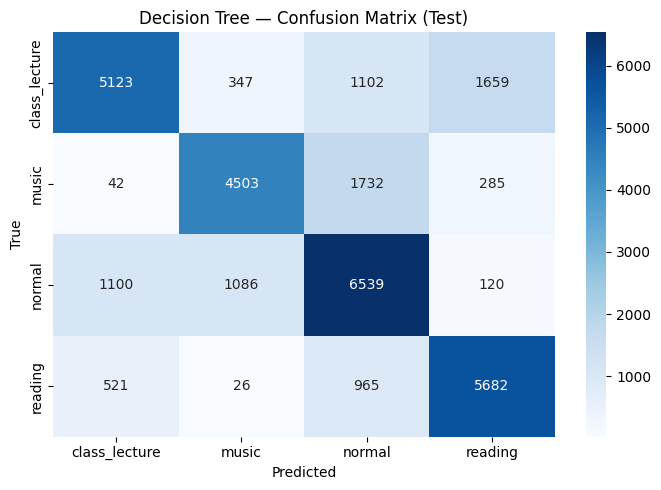

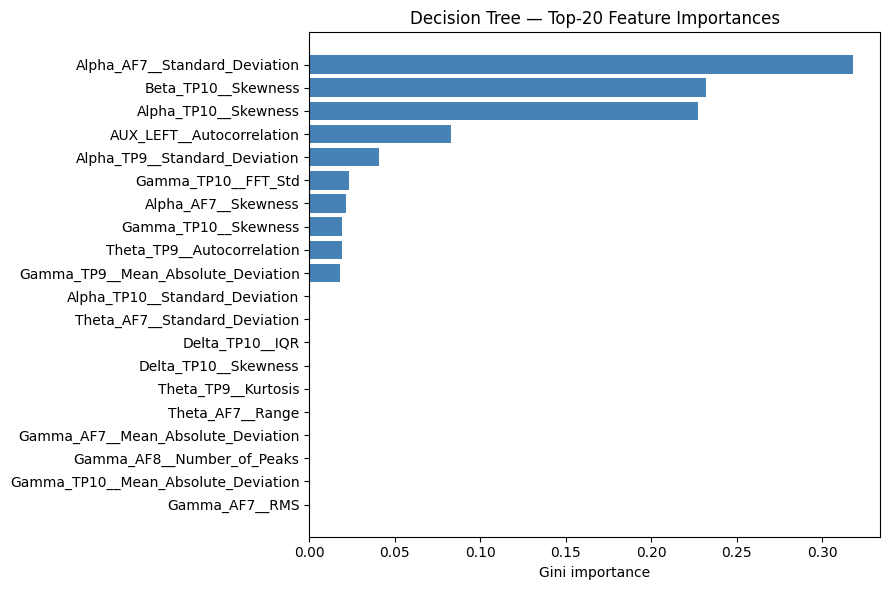


Generating Decision Tree learning curve ...
Learning-curve fit time: 130.4s


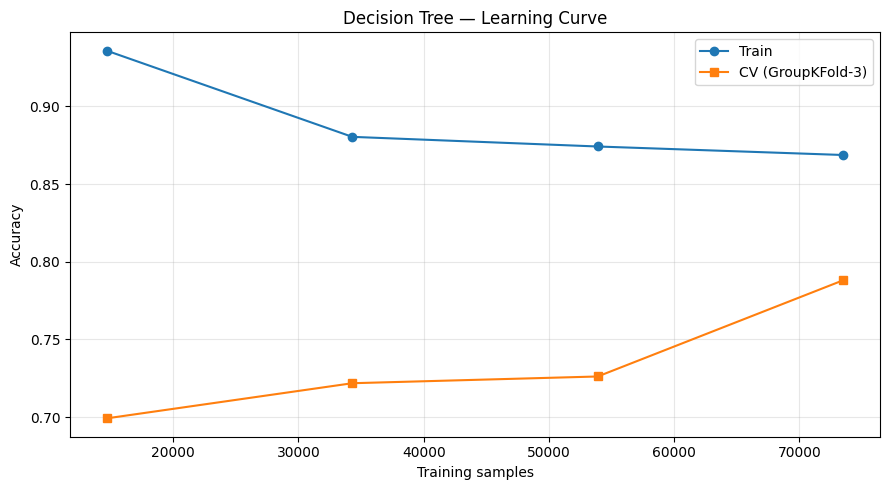


############################################################
  FINAL MODEL: Decision Tree
############################################################
Training accuracy      : 0.8455
Testing  accuracy      : 0.7086
GroupKFold-5 CV        : 0.7739 ± 0.0531
Full LOGO CV           : 0.7282 ± 0.2082
Precision (weighted)   : 0.7149
Recall    (weighted)   : 0.7086
F1 (weighted)          : 0.7083
F1 (macro)             : 0.7109
Cohen Kappa            : 0.6090
MCC                    : 0.6111
ROC-AUC (weighted)     : 0.8608
Best criterion/depth   : gini / 27
min_split / min_leaf   : 25 / 13
max_features / ccp_a   : None / 8.22e-03
Optuna time            : 644.1 s
Total training time    : 997.7 s
Extra RAM used         : 0.0 MB
Current total RAM      : 2285.5 MB


In [ ]:
# =============================================================
#  DECISION TREE (CART) — PERSON-WISE 70/20/10
#  + OPTUNA + 5-RUN + FULL LOGO CV + ALL METRICS
# =============================================================
!pip install -q optuna

import os, time, gc, warnings, psutil, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut, learning_curve
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
import optuna

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

PROC = psutil.Process(os.getpid())
def mem_mb(): return PROC.memory_info().rss / 1024 / 1024

# ============================================================
# 0. ENVIRONMENT NOTE
# ============================================================
print("="*60)
print(" DECISION TREE (CART)")
print(" CPU-only, fast — all cores used via n_jobs=-1")
print(" Deterministic per random_state; we jitter across runs")
print("="*60)

# ============================================================
# CONFIG
# ============================================================
N_TRIALS         = 12      # Optuna trials
N_RUNS           = 5       # 5 runs as required
LOGO_MAX_FOLDS   = None    # None = all LOGO folds (tree is fast)
DT_N_JOBS        = -1      # use all CPU cores

# ============================================================
# 1. LOAD
# ============================================================
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv"
print(f"\nLoading: {file_path}")
df = pd.read_csv(file_path)
print(f"Raw shape: {df.shape} | RAM: {mem_mb():.1f} MB")

metadata_cols = ['PersonSrial','Window','Window_Start','Window_End','Window_Samples']
target_col = 'Class'
feature_cols = [c for c in df.columns if c not in metadata_cols and c != target_col]

le = LabelEncoder()
y_all = le.fit_transform(df[target_col].values)
num_classes = len(le.classes_)
groups_all = df['PersonSrial'].values
X_all = df[feature_cols].astype(np.float32).values
del df; gc.collect()
print(f"Features: {X_all.shape} | Classes: {num_classes} -> {list(le.classes_)}")

# ============================================================
# 2. PERSON-WISE SPLIT 70/20/10
# ============================================================
persons = np.unique(groups_all)
rng = np.random.RandomState(42); rng.shuffle(persons)
n_p    = len(persons)
n_test = max(1, int(round(0.20*n_p)))
n_cv   = max(1, int(round(0.10*n_p)))

test_persons  = persons[:n_test]
cv_persons    = persons[n_test:n_test+n_cv]
train_persons = persons[n_test+n_cv:]

tr_mask = np.isin(groups_all, train_persons)
te_mask = np.isin(groups_all, test_persons)
cv_mask = np.isin(groups_all, cv_persons)

X_train, y_train, g_train = X_all[tr_mask], y_all[tr_mask], groups_all[tr_mask]
X_test,  y_test,  g_test  = X_all[te_mask], y_all[te_mask], groups_all[te_mask]
X_cv,    y_cv,    g_cv    = X_all[cv_mask], y_all[cv_mask], groups_all[cv_mask]
del X_all; gc.collect()

print(f"\nPerson-wise split -> Train: {len(train_persons)} | "
      f"Test: {len(test_persons)} | CV: {len(cv_persons)}")
print(f"Train: {X_train.shape} | Test: {X_test.shape} | CV: {X_cv.shape}")

# ============================================================
# 3. STANDARDIZATION (not required for trees, kept for parity)
# ============================================================
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_test  = scaler.transform(X_test).astype(np.float32)
X_cv    = scaler.transform(X_cv).astype(np.float32)
gc.collect()

# ============================================================
# 4. CV SCHEMES
# ============================================================
gkf_splits       = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
logo_splits_full = list(LeaveOneGroupOut().split(X_train, y_train, g_train))
logo_splits = logo_splits_full if LOGO_MAX_FOLDS is None \
              else logo_splits_full[:LOGO_MAX_FOLDS]
print(f"GroupKFold folds: {len(gkf_splits)} | LOGO folds: {len(logo_splits)}")

# ============================================================
# 5. DECISION TREE MODEL + OPTUNA
# ============================================================
def make_dt(params, random_state=42):
    return DecisionTreeClassifier(
        criterion        = params['criterion'],
        splitter         = params.get('splitter', 'best'),
        max_depth        = params['max_depth'],
        min_samples_split= params['min_samples_split'],
        min_samples_leaf = params['min_samples_leaf'],
        max_features     = params.get('max_features', None),
        ccp_alpha        = params.get('ccp_alpha', 0.0),
        class_weight     = 'balanced',   # handles imbalance natively
        random_state     = random_state,
    )

def fit_dt(params, X_tr, y_tr, random_state=42):
    m = make_dt(params, random_state=random_state)
    m.fit(X_tr, y_tr)
    return m

def dt_objective(trial):
    params = dict(
        criterion         = trial.suggest_categorical('criterion',
                                                      ['gini', 'entropy']),
        max_depth         = trial.suggest_int('max_depth', 4, 30),
        min_samples_split = trial.suggest_int('min_samples_split', 2, 50),
        min_samples_leaf  = trial.suggest_int('min_samples_leaf', 1, 30),
        max_features      = trial.suggest_categorical('max_features',
                                                      [None, 'sqrt', 'log2']),
        ccp_alpha         = trial.suggest_float('ccp_alpha', 1e-5, 1e-2, log=True),
    )
    scores = []
    for tr_i, va_i in gkf_splits:
        m = fit_dt(params, X_train[tr_i], y_train[tr_i], random_state=42)
        pred = m.predict(X_train[va_i])
        scores.append(accuracy_score(y_train[va_i], pred))
        del m; gc.collect()
    return -float(np.mean(scores))

print(f"\nRunning Optuna (Decision Tree, {N_TRIALS} trials) ...")
t0 = time.time()
study = optuna.create_study(direction='minimize',
                            sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(dt_objective, n_trials=N_TRIALS, show_progress_bar=True)
optuna_time = time.time() - t0
print(f"Optuna: {optuna_time:.1f}s | best GKF = {-study.best_value:.4f}")
print("Best params:", study.best_params)

best_params = dict(
    criterion         = study.best_params['criterion'],
    max_depth         = study.best_params['max_depth'],
    min_samples_split = study.best_params['min_samples_split'],
    min_samples_leaf  = study.best_params['min_samples_leaf'],
    max_features      = study.best_params['max_features'],
    ccp_alpha         = study.best_params['ccp_alpha'],
)
with open("/content/dt_best_params.json", "w") as f:
    json.dump(best_params, f, indent=2)
print("Saved best_params to /content/dt_best_params.json")

# ============================================================
# 6. DECISION TREE : 5 runs (best-of)
# ============================================================
def run_dt(params, n_runs=5):
    records, best_bundle = [], None
    for run in range(n_runs):
        t_run = time.time()
        p = params.copy()
        # trees are deterministic → jitter random_state to get diverse runs
        rs = 42 + run

        # GroupKFold CV
        cv_accs = []
        for tr_i, va_i in gkf_splits:
            m = fit_dt(p, X_train[tr_i], y_train[tr_i], random_state=rs)
            pr = m.predict(X_train[va_i])
            cv_accs.append(accuracy_score(y_train[va_i], pr))
            del m; gc.collect()

        # Full train fit + test prediction
        model = fit_dt(p, X_train, y_train, random_state=rs)
        tr_pred  = model.predict(X_train)
        te_proba = model.predict_proba(X_test)
        te_pred  = np.argmax(te_proba, axis=1)
        rt = time.time() - t_run

        rec = dict(run=run+1,
                   train_acc=accuracy_score(y_train, tr_pred),
                   test_acc =accuracy_score(y_test,  te_pred),
                   cv_acc   =float(np.mean(cv_accs)),
                   cv_std   =float(np.std(cv_accs)),
                   precision_weighted=precision_score(y_test, te_pred, average='weighted', zero_division=0),
                   recall_weighted   =recall_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_weighted       =f1_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_macro          =f1_score(y_test, te_pred, average='macro', zero_division=0),
                   kappa=cohen_kappa_score(y_test, te_pred),
                   mcc  =matthews_corrcoef(y_test, te_pred),
                   depth_actual=int(model.get_depth()),
                   leaves=int(model.get_n_leaves()),
                   exec_time_sec=rt)
        try: rec['roc_auc'] = roc_auc_score(y_test, te_proba,
                                            multi_class='ovr', average='weighted')
        except Exception: rec['roc_auc'] = np.nan
        records.append(rec)
        print(f"[DT {run+1}] depth={rec['depth_actual']} leaves={rec['leaves']} "
              f"train={rec['train_acc']:.4f} test={rec['test_acc']:.4f} "
              f"cv={rec['cv_acc']:.4f}±{rec['cv_std']:.3f} t={rt:.1f}s")
        if best_bundle is None or rec['test_acc'] > best_bundle[0]['test_acc']:
            best_bundle = (rec, te_proba, te_pred, model)
        if run < n_runs-1: del model; gc.collect()
    return records, best_bundle

print("\n=== Decision Tree : 5 runs ===")
t0, m0 = time.time(), mem_mb()
dt_records, (dt_best_rec, dt_best_proba, dt_best_pred, dt_best_model) = \
    run_dt(best_params, N_RUNS)
dt_time, dt_mem = time.time()-t0, mem_mb()-m0
print("\n" + pd.DataFrame(dt_records).round(4).to_string(index=False))
print(f"\nDecision Tree total: {dt_time:.1f}s | RAM: {dt_mem:.1f} MB")

# ============================================================
# 7. FULL LOGO CV ON BEST MODEL
# ============================================================
def full_logo_cv(params, X_tr, y_tr, splits, random_state=42):
    accs = []
    for i, (tr_i, va_i) in enumerate(splits):
        m = fit_dt(params, X_tr[tr_i], y_tr[tr_i], random_state=random_state)
        pr = m.predict(X_tr[va_i])
        accs.append(accuracy_score(y_tr[va_i], pr))
        del m; gc.collect()
        print(f"  LOGO fold {i+1}/{len(splits)} done")
    return float(np.mean(accs)), float(np.std(accs))

print(f"\nFull LOGO CV ({len(logo_splits)} folds) ...")
t0 = time.time()
logo_mean, logo_std = full_logo_cv(best_params, X_train, y_train, logo_splits)
print(f"LOGO CV: {logo_mean:.4f} ± {logo_std:.4f} ({time.time()-t0:.1f}s)")

# ============================================================
# 8. FULL REPORT
# ============================================================
def print_full_report(name, rec, proba, pred, y_true, le_enc,
                      total_time, mem, logo):
    print(f"\n{'='*60}\n  {name}  —  Best Run (#{rec['run']})\n{'='*60}")
    print(f"Training Accuracy      : {rec['train_acc']:.4f}")
    print(f"Testing  Accuracy      : {rec['test_acc']:.4f}")
    print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
    if logo is not None:
        print(f"Full LOGO CV           : {logo[0]:.4f} ± {logo[1]:.4f}")
    print(f"Testing Precision (w)  : {rec['precision_weighted']:.4f}")
    print(f"Testing Recall    (w)  : {rec['recall_weighted']:.4f}")
    print(f"Testing F1 (Weighted)  : {rec['f1_weighted']:.4f}")
    print(f"Testing F1 (Macro)     : {rec['f1_macro']:.4f}")
    print(f"Testing Cohen Kappa    : {rec['kappa']:.4f}")
    print(f"Testing MCC            : {rec['mcc']:.4f}")
    print(f"Testing ROC-AUC (w)    : {rec['roc_auc']:.4f}")
    print(f"Tree depth / leaves    : {rec.get('depth_actual','n/a')} / {rec.get('leaves','n/a')}")
    print(f"Execution time (run)   : {rec['exec_time_sec']:.2f} s")
    print(f"Total pipeline time    : {total_time:.2f} s")
    print(f"Extra RAM used         : {mem:.1f} MB")
    print("\nClassification report (test):")
    print(classification_report(y_true, pred, target_names=le_enc.classes_, digits=4))
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(7,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le_enc.classes_, yticklabels=le_enc.classes_)
    plt.title(f'{name} — Confusion Matrix (Test)')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout(); plt.show()

print_full_report("Decision Tree", dt_best_rec, dt_best_proba, dt_best_pred,
                  y_test, le, dt_time, dt_mem, (logo_mean, logo_std))

# ============================================================
# 9. FEATURE IMPORTANCE (top-20)
# ============================================================
importances = dt_best_model.feature_importances_
idx = np.argsort(importances)[::-1][:20]
plt.figure(figsize=(9,6))
plt.barh(np.array(feature_cols)[idx][::-1], importances[idx][::-1],
         color='steelblue')
plt.xlabel('Gini importance')
plt.title('Decision Tree — Top-20 Feature Importances')
plt.tight_layout(); plt.show()

# ============================================================
# 10. LEARNING CURVE
# ============================================================
print("\nGenerating Decision Tree learning curve ...")
t0 = time.time()
ts, tr_s, va_s = learning_curve(
    make_dt(best_params), X_train, y_train, groups=g_train,
    cv=GroupKFold(n_splits=3), scoring='accuracy',
    train_sizes=np.linspace(0.2, 1.0, 4), n_jobs=1)
print(f"Learning-curve fit time: {time.time()-t0:.1f}s")

plt.figure(figsize=(9,5))
plt.plot(ts, tr_s.mean(1), 'o-', label='Train')
plt.plot(ts, va_s.mean(1), 's-', label='CV (GroupKFold-3)')
plt.xlabel('Training samples'); plt.ylabel('Accuracy')
plt.title('Decision Tree — Learning Curve')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ============================================================
# 11. FINAL SUMMARY
# ============================================================
rec = dt_best_rec
print(f"\n{'#'*60}\n  FINAL MODEL: Decision Tree\n{'#'*60}")
print(f"Training accuracy      : {rec['train_acc']:.4f}")
print(f"Testing  accuracy      : {rec['test_acc']:.4f}")
print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
print(f"Full LOGO CV           : {logo_mean:.4f} ± {logo_std:.4f}")
print(f"Precision (weighted)   : {rec['precision_weighted']:.4f}")
print(f"Recall    (weighted)   : {rec['recall_weighted']:.4f}")
print(f"F1 (weighted)          : {rec['f1_weighted']:.4f}")
print(f"F1 (macro)             : {rec['f1_macro']:.4f}")
print(f"Cohen Kappa            : {rec['kappa']:.4f}")
print(f"MCC                    : {rec['mcc']:.4f}")
print(f"ROC-AUC (weighted)     : {rec['roc_auc']:.4f}")
print(f"Best criterion/depth   : {best_params['criterion']} / {best_params['max_depth']}")
print(f"min_split / min_leaf   : {best_params['min_samples_split']} / {best_params['min_samples_leaf']}")
print(f"max_features / ccp_a   : {best_params['max_features']} / {best_params['ccp_alpha']:.2e}")
print(f"Optuna time            : {optuna_time:.1f} s")
print(f"Total training time    : {dt_time:.1f} s")
print(f"Extra RAM used         : {dt_mem:.1f} MB")
print(f"Current total RAM      : {mem_mb():.1f} MB")

**Apply Naive Bayes on Med Dataset**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.9 MB/s eta 0:00:00
 NAIVE BAYES (Gaussian)
 Closed-form MLE — fastest of all models
 No gradient, no iterations, no random_state

Loading: /content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv
Raw shape: (156741, 102) | RAM: 521.8 MB
Features: (156741, 96) | Classes: 4 -> ['class_lecture', 'music', 'normal', 'reading']

Person-wise split -> Train: 42 | Test: 12 | CV: 6
Train: (109891, 96) | Test: (30832, 96) | CV: (16018, 96)
GroupKFold folds: 5 | LOGO folds: 42

Running Optuna (GaussianNB, 12 trials) ...


  0%|          | 0/12 [00:00<?, ?it/s]

Optuna: 26.4s | best GKF = 0.4900
Best params: {'var_smoothing': 2.348881295853314e-09}
Saved best_params to /content/nb_best_params.json

=== Naive Bayes : 5 runs ===
[NB 1] vs=1.48e-09 train=0.5364 test=0.4277 cv=0.4900±0.040 t=2.45s
[NB 2] vs=1.87e-09 train=0.5364 test=0.4277 cv=0.4900±0.040 t=2.58s
[NB 3] vs=2.35e-09 train=0.5364 test=0.4277 cv=0.4900±0.040 t=3.93s
[NB 4] vs=2.96e-09 train=0.5364 test=0.4277 cv=0.4900±0.040 t=3.26s
[NB 5] vs=3.72e-09 train=0.5364 test=0.4277 cv=0.4900±0.040 t=2.43s

 run  var_smoothing  train_acc  test_acc  cv_acc  cv_std  precision_weighted  recall_weighted  f1_weighted  f1_macro  kappa    mcc  exec_time_sec  roc_auc
   1            0.0     0.5364    0.4277    0.49  0.0395              0.4786           0.4277       0.3335    0.3152 0.2359 0.2836         2.4502   0.7502
   2            0.0     0.5364    0.4277    0.49  0.0395              0.4786           0.4277       0.3335    0.3152 0.2359 0.2836         2.5759   0.7502
   3            0.0     0.

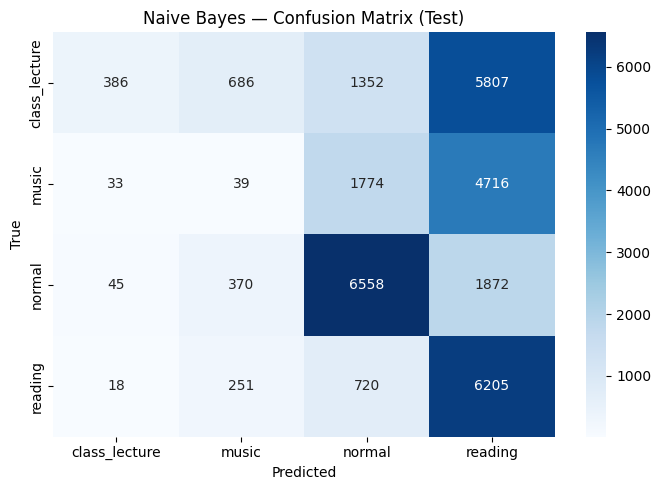

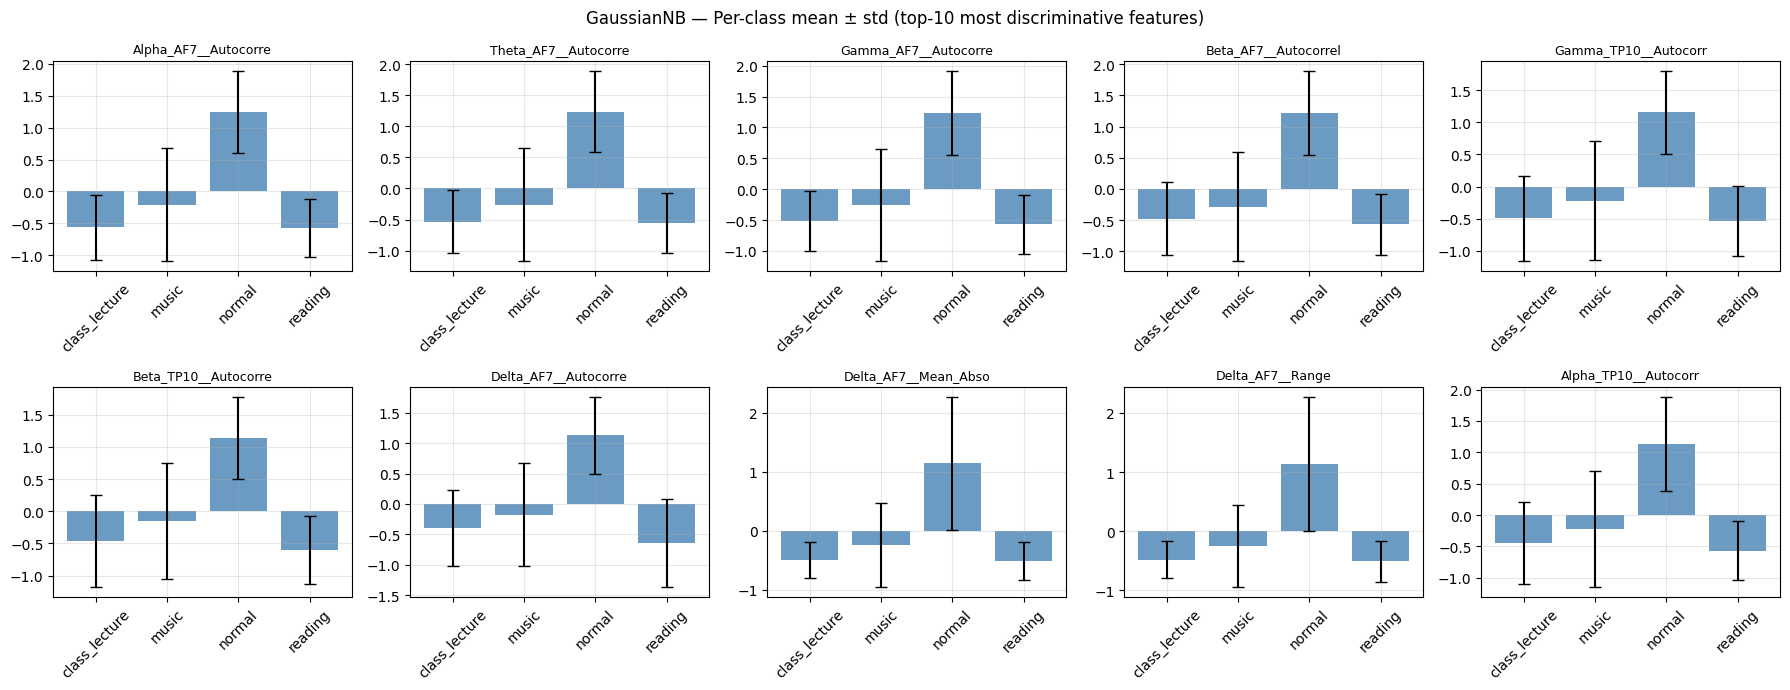


Generating Naive Bayes learning curve ...
Learning-curve fit time: 4.0s


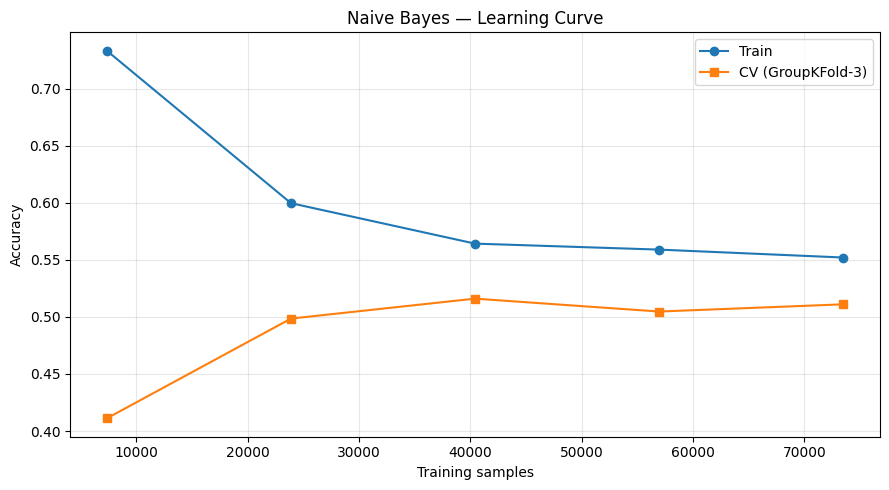


############################################################
  FINAL MODEL: Naive Bayes (Gaussian)
############################################################
Training accuracy      : 0.5364
Testing  accuracy      : 0.4277
GroupKFold-5 CV        : 0.4900 ± 0.0395
Full LOGO CV           : 0.5139 ± 0.1557
Precision (weighted)   : 0.4786
Recall    (weighted)   : 0.4277
F1 (weighted)          : 0.3335
F1 (macro)             : 0.3152
Cohen Kappa            : 0.2359
MCC                    : 0.2836
ROC-AUC (weighted)     : 0.7502
Best var_smoothing     : 2.3489e-09
Uniform priors used    : True
Optuna time            : 26.4 s
Total training time    : 15.7 s
Extra RAM used         : 0.4 MB
Current total RAM      : 410.7 MB


In [ ]:
# =============================================================
#  NAIVE BAYES (GAUSSIAN) — PERSON-WISE 70/20/10
#  + OPTUNA + 5-RUN + FULL LOGO CV + ALL METRICS
# =============================================================
!pip install -q optuna

import os, time, gc, warnings, psutil, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut, learning_curve
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.naive_bayes import GaussianNB
import optuna

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

PROC = psutil.Process(os.getpid())
def mem_mb(): return PROC.memory_info().rss / 1024 / 1024

# ============================================================
# 0. ENVIRONMENT NOTE
# ============================================================
print("="*60)
print(" NAIVE BAYES (Gaussian)")
print(" Closed-form MLE — fastest of all models")
print(" No gradient, no iterations, no random_state")
print("="*60)

# ============================================================
# CONFIG
# ============================================================
N_TRIALS         = 12      # Optuna trials (search space is tiny → fast)
N_RUNS           = 5       # 5 runs as required
LOGO_MAX_FOLDS   = None    # None = all LOGO folds (NB is trivial to refit)
USE_UNIFORM_PRIORS = True  # if True, class priors = 1/K (anti-imbalance)

# ============================================================
# 1. LOAD
# ============================================================
file_path = "/content/drive/MyDrive/Colab Notebooks/Cleaned_oN_Selected_Med.csv"
print(f"\nLoading: {file_path}")
df = pd.read_csv(file_path)
print(f"Raw shape: {df.shape} | RAM: {mem_mb():.1f} MB")

metadata_cols = ['PersonSrial','Window','Window_Start','Window_End','Window_Samples']
target_col = 'Class'
feature_cols = [c for c in df.columns if c not in metadata_cols and c != target_col]

le = LabelEncoder()
y_all = le.fit_transform(df[target_col].values)
num_classes = len(le.classes_)
groups_all = df['PersonSrial'].values
X_all = df[feature_cols].astype(np.float32).values
del df; gc.collect()
print(f"Features: {X_all.shape} | Classes: {num_classes} -> {list(le.classes_)}")

# ============================================================
# 2. PERSON-WISE SPLIT 70/20/10
# ============================================================
persons = np.unique(groups_all)
rng = np.random.RandomState(42); rng.shuffle(persons)
n_p    = len(persons)
n_test = max(1, int(round(0.20*n_p)))
n_cv   = max(1, int(round(0.10*n_p)))

test_persons  = persons[:n_test]
cv_persons    = persons[n_test:n_test+n_cv]
train_persons = persons[n_test+n_cv:]

tr_mask = np.isin(groups_all, train_persons)
te_mask = np.isin(groups_all, test_persons)
cv_mask = np.isin(groups_all, cv_persons)

X_train, y_train, g_train = X_all[tr_mask], y_all[tr_mask], groups_all[tr_mask]
X_test,  y_test,  g_test  = X_all[te_mask], y_all[te_mask], groups_all[te_mask]
X_cv,    y_cv,    g_cv    = X_all[cv_mask], y_all[cv_mask], groups_all[cv_mask]
del X_all; gc.collect()

print(f"\nPerson-wise split -> Train: {len(train_persons)} | "
      f"Test: {len(test_persons)} | CV: {len(cv_persons)}")
print(f"Train: {X_train.shape} | Test: {X_test.shape} | CV: {X_cv.shape}")

# ============================================================
# 3. STANDARDIZATION (helps var_smoothing behave uniformly)
# ============================================================
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_test  = scaler.transform(X_test).astype(np.float32)
X_cv    = scaler.transform(X_cv).astype(np.float32)
gc.collect()

# ============================================================
# 4. CV SCHEMES
# ============================================================
gkf_splits       = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
logo_splits_full = list(LeaveOneGroupOut().split(X_train, y_train, g_train))
logo_splits      = logo_splits_full if LOGO_MAX_FOLDS is None \
                   else logo_splits_full[:LOGO_MAX_FOLDS]
print(f"GroupKFold folds: {len(gkf_splits)} | LOGO folds: {len(logo_splits)}")

# ============================================================
# 5. NAIVE BAYES MODEL + OPTUNA
# ============================================================
def make_nb(params, num_classes=num_classes, priors_uniform=USE_UNIFORM_PRIORS):
    priors = (np.ones(num_classes) / num_classes) if priors_uniform else None
    return GaussianNB(
        priors        = priors,
        var_smoothing = params['var_smoothing'],
    )

def fit_nb(params, X_tr, y_tr):
    m = make_nb(params)
    m.fit(X_tr, y_tr)
    return m

def nb_objective(trial):
    params = dict(
        var_smoothing = trial.suggest_float('var_smoothing',
                                            1e-12, 1e-3, log=True),
    )
    scores = []
    for tr_i, va_i in gkf_splits:
        m = fit_nb(params, X_train[tr_i], y_train[tr_i])
        pred = m.predict(X_train[va_i])
        scores.append(accuracy_score(y_train[va_i], pred))
        del m; gc.collect()
    return -float(np.mean(scores))

print(f"\nRunning Optuna (GaussianNB, {N_TRIALS} trials) ...")
t0 = time.time()
study = optuna.create_study(direction='minimize',
                            sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(nb_objective, n_trials=N_TRIALS, show_progress_bar=True)
optuna_time = time.time() - t0
print(f"Optuna: {optuna_time:.1f}s | best GKF = {-study.best_value:.4f}")
print("Best params:", study.best_params)

best_params = dict(
    var_smoothing = study.best_params['var_smoothing'],
)
with open("/content/nb_best_params.json", "w") as f:
    json.dump(best_params, f, indent=2)
print("Saved best_params to /content/nb_best_params.json")

# ============================================================
# 6. NAIVE BAYES : 5 runs (best-of)
# ============================================================
def run_nb(params, n_runs=5):
    records, best_bundle = [], None
    for run in range(n_runs):
        t_run = time.time()
        p = params.copy()
        # NB has no random_state → jitter var_smoothing slightly across runs
        p['var_smoothing'] = p['var_smoothing'] * (10 ** (0.1*(run - 2)))

        # GroupKFold CV
        cv_accs = []
        for tr_i, va_i in gkf_splits:
            m = fit_nb(p, X_train[tr_i], y_train[tr_i])
            pr = m.predict(X_train[va_i])
            cv_accs.append(accuracy_score(y_train[va_i], pr))
            del m; gc.collect()

        # Full train fit + test prediction
        model = fit_nb(p, X_train, y_train)
        tr_pred  = model.predict(X_train)
        te_proba = model.predict_proba(X_test)
        te_pred  = np.argmax(te_proba, axis=1)
        rt = time.time() - t_run

        rec = dict(run=run+1,
                   var_smoothing=p['var_smoothing'],
                   train_acc=accuracy_score(y_train, tr_pred),
                   test_acc =accuracy_score(y_test,  te_pred),
                   cv_acc   =float(np.mean(cv_accs)),
                   cv_std   =float(np.std(cv_accs)),
                   precision_weighted=precision_score(y_test, te_pred, average='weighted', zero_division=0),
                   recall_weighted   =recall_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_weighted       =f1_score(y_test, te_pred, average='weighted', zero_division=0),
                   f1_macro          =f1_score(y_test, te_pred, average='macro', zero_division=0),
                   kappa=cohen_kappa_score(y_test, te_pred),
                   mcc  =matthews_corrcoef(y_test, te_pred),
                   exec_time_sec=rt)
        try: rec['roc_auc'] = roc_auc_score(y_test, te_proba,
                                            multi_class='ovr', average='weighted')
        except Exception: rec['roc_auc'] = np.nan
        records.append(rec)
        print(f"[NB {run+1}] vs={p['var_smoothing']:.2e} "
              f"train={rec['train_acc']:.4f} test={rec['test_acc']:.4f} "
              f"cv={rec['cv_acc']:.4f}±{rec['cv_std']:.3f} t={rt:.2f}s")
        if best_bundle is None or rec['test_acc'] > best_bundle[0]['test_acc']:
            best_bundle = (rec, te_proba, te_pred, model)
        if run < n_runs-1: del model; gc.collect()
    return records, best_bundle

print("\n=== Naive Bayes : 5 runs ===")
t0, m0 = time.time(), mem_mb()
nb_records, (nb_best_rec, nb_best_proba, nb_best_pred, nb_best_model) = \
    run_nb(best_params, N_RUNS)
nb_time, nb_mem = time.time()-t0, mem_mb()-m0
print("\n" + pd.DataFrame(nb_records).round(4).to_string(index=False))
print(f"\nNaive Bayes total: {nb_time:.1f}s | RAM: {nb_mem:.1f} MB")

# ============================================================
# 7. FULL LOGO CV ON BEST MODEL
# ============================================================
def full_logo_cv(params, X_tr, y_tr, splits):
    accs = []
    for i, (tr_i, va_i) in enumerate(splits):
        m = fit_nb(params, X_tr[tr_i], y_tr[tr_i])
        pr = m.predict(X_tr[va_i])
        accs.append(accuracy_score(y_tr[va_i], pr))
        del m; gc.collect()
        print(f"  LOGO fold {i+1}/{len(splits)} done")
    return float(np.mean(accs)), float(np.std(accs))

print(f"\nFull LOGO CV ({len(logo_splits)} folds) ...")
t0 = time.time()
logo_mean, logo_std = full_logo_cv(best_params, X_train, y_train, logo_splits)
print(f"LOGO CV: {logo_mean:.4f} ± {logo_std:.4f} ({time.time()-t0:.1f}s)")

# ============================================================
# 8. FULL REPORT
# ============================================================
def print_full_report(name, rec, proba, pred, y_true, le_enc,
                      total_time, mem, logo):
    print(f"\n{'='*60}\n  {name}  —  Best Run (#{rec['run']})\n{'='*60}")
    print(f"Training Accuracy      : {rec['train_acc']:.4f}")
    print(f"Testing  Accuracy      : {rec['test_acc']:.4f}")
    print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
    if logo is not None:
        print(f"Full LOGO CV           : {logo[0]:.4f} ± {logo[1]:.4f}")
    print(f"Testing Precision (w)  : {rec['precision_weighted']:.4f}")
    print(f"Testing Recall    (w)  : {rec['recall_weighted']:.4f}")
    print(f"Testing F1 (Weighted)  : {rec['f1_weighted']:.4f}")
    print(f"Testing F1 (Macro)     : {rec['f1_macro']:.4f}")
    print(f"Testing Cohen Kappa    : {rec['kappa']:.4f}")
    print(f"Testing MCC            : {rec['mcc']:.4f}")
    print(f"Testing ROC-AUC (w)    : {rec['roc_auc']:.4f}")
    print(f"var_smoothing (best)   : {rec['var_smoothing']:.2e}")
    print(f"Execution time (run)   : {rec['exec_time_sec']:.2f} s")
    print(f"Total pipeline time    : {total_time:.2f} s")
    print(f"Extra RAM used         : {mem:.1f} MB")
    print("\nClassification report (test):")
    print(classification_report(y_true, pred, target_names=le_enc.classes_, digits=4))
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(7,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le_enc.classes_, yticklabels=le_enc.classes_)
    plt.title(f'{name} — Confusion Matrix (Test)')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout(); plt.show()

print_full_report("Naive Bayes", nb_best_rec, nb_best_proba, nb_best_pred,
                  y_test, le, nb_time, nb_mem, (logo_mean, logo_std))

# ============================================================
# 9. NAIVE BAYES DIAGNOSTIC — per-class mean profile (top-10 features)
# ============================================================
# GaussianNB stores theta_ (means) and var_ (variances) per class per feature.
top_feats = np.argsort(np.var(nb_best_model.theta_, axis=0))[::-1][:10]
fig, axes = plt.subplots(2, 5, figsize=(18,7))
for ax, fi in zip(axes.ravel(), top_feats):
    ax.bar(np.arange(num_classes), nb_best_model.theta_[:, fi],
           yerr=np.sqrt(nb_best_model.var_[:, fi]), capsize=4,
           color='steelblue', alpha=0.8)
    ax.set_xticks(np.arange(num_classes))
    ax.set_xticklabels(le.classes_, rotation=45)
    ax.set_title(feature_cols[fi][:20], fontsize=9)
    ax.grid(alpha=0.3)
plt.suptitle('GaussianNB — Per-class mean ± std (top-10 most discriminative features)')
plt.tight_layout(); plt.show()

# ============================================================
# 10. LEARNING CURVE
# ============================================================
print("\nGenerating Naive Bayes learning curve ...")
t0 = time.time()
ts, tr_s, va_s = learning_curve(
    make_nb(best_params), X_train, y_train, groups=g_train,
    cv=GroupKFold(n_splits=3), scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=1)
print(f"Learning-curve fit time: {time.time()-t0:.1f}s")

plt.figure(figsize=(9,5))
plt.plot(ts, tr_s.mean(1), 'o-', label='Train')
plt.plot(ts, va_s.mean(1), 's-', label='CV (GroupKFold-3)')
plt.xlabel('Training samples'); plt.ylabel('Accuracy')
plt.title('Naive Bayes — Learning Curve')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ============================================================
# 11. FINAL SUMMARY
# ============================================================
rec = nb_best_rec
print(f"\n{'#'*60}\n  FINAL MODEL: Naive Bayes (Gaussian)\n{'#'*60}")
print(f"Training accuracy      : {rec['train_acc']:.4f}")
print(f"Testing  accuracy      : {rec['test_acc']:.4f}")
print(f"GroupKFold-5 CV        : {rec['cv_acc']:.4f} ± {rec['cv_std']:.4f}")
print(f"Full LOGO CV           : {logo_mean:.4f} ± {logo_std:.4f}")
print(f"Precision (weighted)   : {rec['precision_weighted']:.4f}")
print(f"Recall    (weighted)   : {rec['recall_weighted']:.4f}")
print(f"F1 (weighted)          : {rec['f1_weighted']:.4f}")
print(f"F1 (macro)             : {rec['f1_macro']:.4f}")
print(f"Cohen Kappa            : {rec['kappa']:.4f}")
print(f"MCC                    : {rec['mcc']:.4f}")
print(f"ROC-AUC (weighted)     : {rec['roc_auc']:.4f}")
print(f"Best var_smoothing     : {best_params['var_smoothing']:.4e}")
print(f"Uniform priors used    : {USE_UNIFORM_PRIORS}")
print(f"Optuna time            : {optuna_time:.1f} s")
print(f"Total training time    : {nb_time:.1f} s")
print(f"Extra RAM used         : {nb_mem:.1f} MB")
print(f"Current total RAM      : {mem_mb():.1f} MB")

**Apply Bi-LSTM on Med Dataset in VS Code**

**Apply SVM (RBF) on Med Dataset in VS Code**

**Apply Logistic Regression on Med Dataset in VS Code**